# ĐỒ ÁN TRÍ TUỆ NHÂN TẠO — ĐỀ TÀI 5
# 🎮 Game Tic-Tac-Toe giữa Người và Máy với thuật toán Minimax

**Nhóm thực hiện:** *(điền tên các thành viên và MSSV)*

---

### Mục tiêu
Xây dựng một **tác nhân (agent)** chơi Tic-Tac-Toe với con người. Tác nhân mô hình hóa trạng thái là **bàn cờ**, Transition Function là **đặt X hoặc O**, và dùng **Minimax** (cùng các cải tiến trong bài giảng) để **chọn nước đi tối ưu**.

> 📚 Notebook **bám sát bài giảng *Lecture 3 – Adversarial Search and Games (AIMA Chapter 6)*** cùng các file *examples.pptx* và *exercises.pptx* của môn học: dùng đúng ký hiệu (`s0, Actions(s), Result(s,a), Terminal(s), Utility(s)`, MAX/MIN, α/β, Eval, UCB1…), đúng mã giả, và **tái hiện lại các con số, bài tập trong slide**.

### Đối chiếu slide bài giảng ↔ notebook
| Nội dung trong slide | Trang slide | Ở đâu trong notebook |
|---|---|---|
| Games: strategic, episodic, two-player zero-sum, deterministic, perfect information; Max/Min | tr. 3 | Phần 1 |
| *Definition of a Game* và ví dụ *Tic-tac-toe* | tr. 4–5 | Phần 2 |
| Game tree, 3⁹ = 19.683 trạng thái, cây < 986.409 nút | tr. 6–7, 19 | Mục 2.1, Phần 4 |
| Exact method: *Nondeterministic actions*, **AND-OR search** | tr. 9–12 | Mục 5.1 |
| **Minimax search**, minimax value, độ phức tạp O(bᵐ) | tr. 13–19; examples tr. 1–6 | Mục 5.2 |
| **Alpha-Beta pruning**, điều kiện cắt α ≥ β | tr. 20–24; examples tr. 7–29 | Mục 5.3 |
| *Exercise: Simple 2-Ply Game* (có/không Alpha-Beta, Move ordering) | tr. 18, 24, 26; exercises.pptx | Mục 5.4 |
| **Move ordering** (center, corner, rest) và bảng hiệu quả | tr. 25–27 | Mục 5.5 |
| **Heuristic Alpha-Beta Tree Search**: cut-off + Eval, forward pruning | tr. 29–35 | Mục 5.7 |
| **Pure Monte Carlo Search**, **MCTS**, **UCB1** | tr. 36–44 | Mục 5.8 |
| Stochastic games, Expectiminimax | tr. 45–48 | Không áp dụng — Tic-Tac-Toe không có yếu tố may rủi (giải thích ở Phần 1) |

### Đối chiếu yêu cầu đề tài ↔ notebook
| Yêu cầu | Phần |
|---|---|
| 1. PEAS + phân loại môi trường | Phần 1 |
| 2. Định nghĩa bài toán tìm kiếm | Phần 2 |
| 3. Transition Function (lời + bảng ≥ 10 dòng) | Phần 3 |
| 4. Cây tìm kiếm (10–30 trạng thái) | Phần 4 |
| 5. ≥ 3 giải thuật + so sánh + thu hẹp không gian + ≥ 2 heuristic | Phần 5 (7 giải thuật, 2 heuristic) |
| 6. Giao diện đồ họa, đổi tham số | Phần 6 |

### Cách chạy notebook
1. Mở bằng **Jupyter Notebook / JupyterLab / VS Code** (hoặc Google Colab).
2. Cài thư viện nếu chưa có (ô code ngay bên dưới).
3. Chọn **Kernel → Restart & Run All**. Toàn bộ notebook chạy khoảng **1 phút**.
4. Kéo xuống **Phần 6** để chơi với máy.

> 📌 **Cách đọc:** mỗi phần có **Ý tưởng** (markdown, có dẫn trang slide) → **Code** (chú thích từng dòng) → **Giải thích kết quả**. Khung 💡 là ghi chú "hiểu sâu" — hay bị hỏi khi bảo vệ.

In [1]:
# Nếu máy chưa có thư viện, bỏ dấu # ở dòng dưới rồi chạy ô này (chỉ cần chạy 1 lần):
# %pip install matplotlib pandas ipywidgets

In [2]:
# ===== Nạp thư viện dùng trong toàn bộ notebook =====
import math            # math.inf = vô cực (dùng cho alpha, beta); sqrt, log cho UCB1
import time            # đo thời gian chạy
import random          # sinh ngẫu nhiên (nhánh cây, playout Monte Carlo, đối thủ ngẫu nhiên)
import tracemalloc     # đo bộ nhớ đỉnh (peak memory) khi chạy thuật toán
from collections import namedtuple, deque   # namedtuple: kiểu State gọn; deque: hàng đợi cho BFS
from dataclasses import dataclass           # lớp chứa kết quả tìm kiếm

import pandas as pd                          # hiển thị bảng
import matplotlib.pyplot as plt              # vẽ bàn cờ, cây tìm kiếm, biểu đồ
from matplotlib.patches import Rectangle
from IPython.display import display, HTML

random.seed(2026)                            # cố định hạt giống ngẫu nhiên -> chạy lại cho kết quả giống nhau
pd.set_option('display.max_colwidth', None)
print('✅ Đã nạp thư viện xong!')

✅ Đã nạp thư viện xong!


---
# PHẦN 1 — ĐẶC TẢ BÀI TOÁN THEO MÔ HÌNH PEAS

Theo slide (tr. 3), trò chơi có **hai người chơi**:
1. **Max (Agent)** — *cố gắng tối đa hóa utility của mình* → ở đây là **máy (AI)**.
2. **Min (Opponent)** — *cố gắng tối thiểu hóa utility của Max* (trò chơi tổng bằng 0) → ở đây là **người chơi**.

Người chơi là **một phần của môi trường** (slide tr. 10: *"The opponent is considered part of the strategic environment"*).

> 💡 **Loại tác nhân:** slide tr. 5 ghi chú *"This game still uses a **goal-based agent** that plans actions to reach a winning terminal state"* — tác nhân lập kế hoạch để đến trạng thái kết thúc thắng. Vì dùng hàm **Utility** (+1/0/−1) để so sánh các kết cục (thắng > hòa > thua) nên cũng có thể nhìn nó như **utility-based agent**.

### 1.1 Bảng PEAS

| Thành phần | Mô tả cụ thể cho bài toán Tic-Tac-Toe |
|---|---|
| **P – Performance measure** (thước đo hiệu năng) | • Kết quả ván cờ theo **Utility của Max**: **thắng = +1**, **hòa = 0**, **thua = −1** (slide tr. 5).<br>• Với bàn 3×3: AI **không bao giờ thua**.<br>• *(Tùy chọn)* thắng càng **sớm** càng tốt, thua càng **muộn** càng tốt.<br>• Tiêu chí phụ: thời gian suy nghĩ ngắn, số nút duyệt ít, bộ nhớ nhỏ. |
| **E – Environment** (môi trường) | • Bàn cờ **n×n** (mặc định 3×3), mỗi ô: trống / X / O.<br>• Luật: ai có **k quân liên tiếp** (hàng, cột, chéo) trước thì thắng; bàn đầy mà chưa ai thắng là hòa (mặc định k = 3).<br>• **Đối thủ (Min)** là con người, hai bên **đi luân phiên**. |
| **A – Actuators** (bộ phận hành động) | • **Đặt một quân** (X hoặc O) vào **một ô trống** — đúng *"Result(s, a): Symbol (x/o) is placed on empty square"* (slide tr. 5).<br>• Trên giao diện: hiển thị quân, tô màu điểm đánh giá các ô, thông báo kết quả. |
| **S – Sensors** (cảm biến) | • **Đọc toàn bộ bàn cờ** (ô nào trống, ô nào X/O) và **đến lượt ai**.<br>• Nhận **nước đi của người** (sự kiện click chuột trên giao diện). |

### 1.2 Phân loại môi trường (theo các tiêu chí đề yêu cầu + thuật ngữ của slide)

| Tiêu chí | Kết luận | Giải thích |
|---|---|---|
| Quan sát được hay không | **Quan sát được đầy đủ** (fully observable) — slide gọi là **perfect information** | Agent thấy toàn bộ bàn cờ, không có thông tin ẩn. |
| Xác định hay ngẫu nhiên | **Xác định** (deterministic game mechanics) | Đặt quân vào ô *a* thì chắc chắn quân nằm ở ô *a*, **không có xúc xắc, rút bài** ⇒ không cần *Expectiminimax / chance node* (slide tr. 45–48). Phần "không biết trước" duy nhất là **nước đi của đối thủ** → slide gọi đây là môi trường **chiến lược (strategic)** và xử lý bằng cách coi nước đi của đối thủ là **hành động không xác định (nondeterministic actions)** — tr. 10. |
| Tĩnh hay động | **Tĩnh** (static) | Khi agent đang suy nghĩ, bàn cờ không tự thay đổi (không bấm giờ). |
| Rời rạc hay liên tục | **Rời rạc** (discrete) | Số ô, số trạng thái, số hành động hữu hạn; thời gian chia theo **lượt**. |
| Đơn hay đa tác nhân | **Đa tác nhân – cạnh tranh**, **two-player zero-sum** | Hai người chơi đối kháng; Max được bao nhiêu thì Min mất bấy nhiêu. |
| *(bổ sung)* Episodic hay sequential | **Episodic giữa các ván** (slide tr. 3: *"One game does not affect the next"*), nhưng **sequential trong một ván** | Mỗi nước đi trong ván ảnh hưởng đến các nước sau; còn ván này không ảnh hưởng ván sau. |

> 💡 **Vì sao dùng Minimax?** Slide tr. 3 nói rõ ta tập trung vào *"two-player zero-sum games with deterministic game mechanics and perfect information"* — Tic-Tac-Toe thỏa **đúng cả 3 điều kiện**, nên Minimax (và Alpha-Beta) cho **quyết định tối ưu**.

---
# PHẦN 2 — ĐỊNH NGHĨA BÀI TOÁN TÌM KIẾM

Slide tr. 6: *"Making a move is a decision problem that can be addressed as a search problem."* Slide tr. 4–5 định nghĩa một **Game** gồm 5 thành phần; ta ánh xạ sang 6 thành phần đề yêu cầu:

| Đề yêu cầu | Ký hiệu trong slide | Định nghĩa cho Tic-Tac-Toe (slide tr. 5) |
|---|---|---|
| (1) Trạng thái | *position, board* | Cặp **s = (board, to_move)** |
| (2) Trạng thái ban đầu | **s0** | *Empty board* — bàn trống, X (Max) đi trước |
| (3) Tập hành động | **Actions(s)** | *Play empty squares* — các ô còn trống |
| (4) Transition Function | **Result(s, a)** | *Symbol (x/o) is placed on empty square* |
| (5) Kiểm tra đích/kết thúc | **Terminal(s)** | *Did a player win or is the game a draw?* |
| (6) Chi phí / tiện ích | **Utility(s)** | *+1 if x wins, −1 if o wins and 0 for a draw* |

### (1) Trạng thái (State)
**`s = (board, to_move)`**:
- **`board`**: chuỗi **n×n ký tự** `'X'`, `'O'` hoặc `'.'` (ô trống). Ô ở hàng `r`, cột `c` có **chỉ số** `i = r·n + c`:

```
  chỉ số ô           (hàng, cột)
 0 | 1 | 2       (0,0) (0,1) (0,2)
 ---------
 3 | 4 | 5       (1,0) (1,1) (1,2)
 ---------
 6 | 7 | 8       (2,0) (2,1) (2,2)
```
- **`to_move`**: người đang đến lượt (`'X'` hoặc `'O'`).

Ví dụ `board = "X.O.X...."`, `to_move = 'O'`:
```
 X . O
 . X .
 . . .      và đến lượt O.
```
> 💡 Dùng **chuỗi** vì chuỗi *immutable* và *hashable* → làm **khóa từ điển** được (cần cho tập `visited` của BFS và bảng chuyển vị ở Phần 5).

### (2) Trạng thái ban đầu **s0**
Bàn cờ **trống hoàn toàn**; theo slide **x là Max và đi trước**. *(Chương trình cho phép đổi ai đi trước.)*

### (3) Tập hành động **Actions(s)**
`Actions(s) = { i | board[i] = '.' }` — **các ô trống** (*legal moves in state s*). Nếu `s` đã kết thúc thì `Actions(s) = ∅`. Hệ số phân nhánh **b** giảm dần 9, 8, 7, …, 1.

### (4) Transition Function **Result(s, a)** (*transition model*)
Đặt quân của người đang đến lượt vào ô `a`, rồi **đổi lượt**. *(Chi tiết + bảng ở Phần 3.)*

### (5) Kiểm tra kết thúc **Terminal(s)**
`Terminal(s) = True` khi **(a)** có người đạt **k quân liên tiếp** (hàng/cột/chéo) — *"did a player win"*; hoặc **(b)** **bàn đầy** — *"is the game a draw"*. Trạng thái đích mà Max hướng tới là trạng thái kết thúc **Max thắng**.

### (6) Chi phí đường đi và hàm **Utility(s)**
Theo slide tr. 5, **Utility chỉ định nghĩa cho trạng thái kết thúc** và tính **cho Max**:

$$
\text{Utility}(s)=\begin{cases}
+1 & \text{nếu Max thắng}\\
-1 & \text{nếu Min thắng}\\
\;\;\,0 & \text{nếu hòa}
\end{cases}
$$

- **Chi phí đường đi:** mỗi nước đi có chi phí bằng nhau (= 1). Slide tr. 14 giải thích: trạng thái chưa kết thúc có *immediate reward* = 0, giá trị thật của nó là **long-term reward** (sẽ tính bằng Minimax). Vì vậy trong trò chơi ta **không tối thiểu chi phí** mà **tối đa hóa Utility** ở trạng thái kết thúc.
- **Biến thể "thắng nhanh" (tùy chọn, `fast_win=True`):** đưa chi phí đường đi vào Utility: **Utility = ±(1 + số ô trống)**. Thắng càng sớm (còn nhiều ô trống) điểm càng cao; thua càng muộn càng đỡ. Lý do: với +1/0/−1, hai nước "thắng ngay" và "thắng sau 4 nước" **cùng giá trị +1**, AI có thể chọn nước thắng chậm (xem ví dụ ở mục 4.2). Giao diện Phần 6 có ô chọn bật/tắt biến thể này.

**Tổng bằng 0 (zero-sum):** `Utility(s, X) = − Utility(s, O)`.

**Tham số tổng quát** (đổi được trên giao diện): **n** (kích thước bàn 3/4/5), **k** (số quân liên tiếp để thắng, 3 ≤ k ≤ n), **người đi trước**, **fast_win**.

In [3]:
# ======================================================================
#  MÔ HÌNH BÀI TOÁN: lớp TicTacToe chứa đầy đủ các thành phần của "Definition of a Game"
# ======================================================================
EMPTY, X, O = '.', 'X', 'O'                       # ký hiệu ô trống và 2 loại quân
State = namedtuple('State', ['board', 'to_move'])  # trạng thái s = (bàn cờ, người đến lượt)


def other(p):
    """Trả về đối thủ của người chơi p (X <-> O)."""
    return O if p == X else X


class TicTacToe:
    def __init__(self, n=3, k=None, first=X, fast_win=False):
        """n: kích thước bàn n x n;  k: số quân liên tiếp để thắng (mặc định k = n);
        first: ai đi trước;  fast_win: True -> Utility = ±(1 + số ô trống) (ưu tiên thắng nhanh)."""
        k = n if k is None else k
        if not (3 <= k <= n):
            raise ValueError('Cần 3 <= k <= n')
        self.n, self.k, self.first, self.fast_win = n, k, first, fast_win
        self.max_utility = (1 + n * n) if fast_win else 1   # |Utility| lớn nhất (dùng để chuẩn hóa)

        # Tính sẵn MỌI "đường thắng" (dãy k ô liên tiếp). Bàn 3x3, k=3: 3 hàng + 3 cột + 2 chéo = 8 đường.
        self.lines = self._build_lines()

        # position_weight[i] = số đường thắng đi qua ô i (3x3: giữa = 4, góc = 3, cạnh = 2)
        self.cell_lines = [[] for _ in range(n * n)]
        for li, line in enumerate(self.lines):
            for c in line:
                self.cell_lines[c].append(li)
        self.position_weight = [len(ls) for ls in self.cell_lines]

        # MOVE ORDERING (slide tr. 27): "center, corner, rest" = ô nằm trên nhiều đường thắng xét trước
        self.move_order = sorted(range(n * n), key=lambda i: -self.position_weight[i])

        # 8 phép đối xứng của hình vuông (4 phép quay + 4 phép lật) -> dùng để thu hẹp không gian
        self.symmetries = self._build_symmetries()

    # ---------------- các hàm hỗ trợ dựng sẵn ----------------
    def _build_lines(self):
        n, k = self.n, self.k
        lines = []
        for r in range(n):
            for c in range(n):
                # 4 hướng: ngang (0,1), dọc (1,0), chéo xuống phải (1,1), chéo xuống trái (1,-1)
                for dr, dc in [(0, 1), (1, 0), (1, 1), (1, -1)]:
                    er, ec = r + dr * (k - 1), c + dc * (k - 1)   # ô cuối của dãy
                    if 0 <= er < n and 0 <= ec < n:                 # dãy nằm trọn trong bàn
                        lines.append(tuple((r + dr * i) * n + (c + dc * i) for i in range(k)))
        return lines

    def _build_symmetries(self):
        n = self.n
        transforms = [
            lambda r, c: (r, c),                 # giữ nguyên
            lambda r, c: (c, n - 1 - r),         # quay 90°
            lambda r, c: (n - 1 - r, n - 1 - c), # quay 180°
            lambda r, c: (n - 1 - c, r),         # quay 270°
            lambda r, c: (r, n - 1 - c),         # lật ngang (gương trái-phải)
            lambda r, c: (n - 1 - r, c),         # lật dọc (gương trên-dưới)
            lambda r, c: (c, r),                 # lật theo đường chéo chính
            lambda r, c: (n - 1 - c, n - 1 - r), # lật theo đường chéo phụ
        ]
        perms = []
        for t in transforms:
            perm = [0] * (n * n)
            for r in range(n):
                for c in range(n):
                    nr, nc = t(r, c)
                    perm[nr * n + nc] = r * n + c   # ô mới (nr,nc) lấy quân của ô cũ (r,c)
            perms.append(perm)
        return perms

    # ================= DEFINITION OF A GAME (slide tr. 4) =================
    # s0: trạng thái ban đầu - bàn trống
    def initial_state(self):
        return State(EMPTY * (self.n * self.n), self.first)

    def empty_cells(self, board):
        """Danh sách chỉ số các ô trống (dùng trực tiếp trong thuật toán cho nhanh)."""
        return [i for i, ch in enumerate(board) if ch == EMPTY]

    # Actions(s): các nước đi hợp lệ = ô trống; trạng thái kết thúc thì không còn hành động
    def actions(self, s):
        if self.terminal(s):
            return []
        return self.empty_cells(s.board)

    # Result(s, a): transition model - đặt quân của người đến lượt vào ô a rồi đổi lượt
    def result(self, s, a):
        if s.board[a] != EMPTY:
            raise ValueError(f'Hành động không hợp lệ: ô {a} đã có quân')
        new_board = s.board[:a] + s.to_move + s.board[a + 1:]   # chỉ thay đúng ký tự thứ a
        return State(new_board, other(s.to_move))

    # Terminal(s): có người thắng hoặc hòa (bàn đầy)?
    def winning_line(self, board):
        """Trả về đường thắng (tuple chỉ số ô) nếu có người thắng, ngược lại None."""
        for line in self.lines:
            ch = board[line[0]]
            if ch != EMPTY:
                for i in line[1:]:
                    if board[i] != ch:
                        break
                else:               # vòng for chạy hết mà không 'break' -> k ô giống nhau
                    return line
        return None

    def winner(self, board):
        line = self.winning_line(board)
        return board[line[0]] if line else None

    def terminal(self, s):
        return EMPTY not in s.board or self.winner(s.board) is not None

    # Utility(s): chỉ định nghĩa cho trạng thái kết thúc, tính cho người chơi 'player' (Max)
    def utility(self, s, player):
        w = self.winner(s.board)
        if w is None:
            return 0                                                  # hòa
        score = (1 + s.board.count(EMPTY)) if self.fast_win else 1    # slide: +1 / -1
        return score if w == player else -score

    # ---------------- tiện ích hiển thị / đối xứng ----------------
    def canonical(self, board):
        """Dạng chuẩn của bàn cờ: chuỗi nhỏ nhất trong 8 ảnh đối xứng.
        Hai bàn cờ đối xứng nhau sẽ có CÙNG dạng chuẩn."""
        return min(''.join(board[p] for p in perm) for perm in self.symmetries)

    def rc(self, a):
        """Đổi chỉ số ô -> (hàng, cột)."""
        return divmod(a, self.n)

    def pretty(self, board):
        n = self.n
        return '\n'.join(' '.join(board[r * n:(r + 1) * n]) for r in range(n))

print('✅ Đã định nghĩa lớp TicTacToe')

✅ Đã định nghĩa lớp TicTacToe


### Thử nghiệm nhanh mô hình
Ô dưới đây kiểm tra từng thành phần: `s0`, `Actions`, `Result`, `Terminal`, `Utility`.

In [4]:
game = TicTacToe(n=3, k=3)                     # bàn 3x3, 3 quân liên tiếp thì thắng, Utility +1/0/-1 như slide
print('Số đường thắng trên bàn 3x3:', len(game.lines))
print('Các đường thắng (theo chỉ số ô):', game.lines)
print('Trọng số vị trí (số đường qua mỗi ô):', game.position_weight)
print('Move ordering "center, corner, rest":', game.move_order)

s0 = game.initial_state()
print('\ns0 =', s0)
print(game.pretty(s0.board))
print('Actions(s0) =', game.actions(s0), '-> có', len(game.actions(s0)), 'hành động')

s1 = game.result(s0, 4)                         # X đánh vào ô giữa
print('\nResult(s0, 4) =', s1)
print(game.pretty(s1.board))

s = s0                                          # một ván X thắng theo đường chéo 0-4-8
for a in [4, 1, 0, 2, 8]:
    s = game.result(s, a)
print('\nSau chuỗi nước [4, 1, 0, 2, 8]:')
print(game.pretty(s.board))
print('Terminal(s) =', game.terminal(s), '| người thắng =', game.winner(s.board),
      '| đường thắng =', game.winning_line(s.board))
print('Utility(s) cho X (Max) =', game.utility(s, X), ' | cho O =', game.utility(s, O))
game_fast = TicTacToe(3, 3, fast_win=True)
print('Biến thể thắng nhanh: Utility =', game_fast.utility(s, X), '(= 1 + 4 ô trống)')

try:                                            # hành động không hợp lệ: đánh vào ô đã có quân
    game.result(s1, 4)
except ValueError as e:
    print('\nThử đánh lại vào ô 4 ->', e)

Số đường thắng trên bàn 3x3: 8
Các đường thắng (theo chỉ số ô): [(0, 1, 2), (0, 3, 6), (0, 4, 8), (1, 4, 7), (2, 5, 8), (2, 4, 6), (3, 4, 5), (6, 7, 8)]
Trọng số vị trí (số đường qua mỗi ô): [3, 2, 3, 2, 4, 2, 3, 2, 3]
Move ordering "center, corner, rest": [4, 0, 2, 6, 8, 1, 3, 5, 7]

s0 = State(board='.........', to_move='X')
. . .
. . .
. . .
Actions(s0) = [0, 1, 2, 3, 4, 5, 6, 7, 8] -> có 9 hành động

Result(s0, 4) = State(board='....X....', to_move='O')
. . .
. X .
. . .

Sau chuỗi nước [4, 1, 0, 2, 8]:
X O O
. X .
. . X
Terminal(s) = True | người thắng = X | đường thắng = (0, 4, 8)
Utility(s) cho X (Max) = 1  | cho O = -1
Biến thể thắng nhanh: Utility = 5 (= 1 + 4 ô trống)

Thử đánh lại vào ô 4 -> Hành động không hợp lệ: ô 4 đã có quân


### 2.1 Kích thước không gian trạng thái và cây trò chơi
Slide tr. 7 và tr. 19 đưa ra 3 con số; ta kiểm chứng bằng code:
- Số bàn cờ < **3⁹ = 19.683** (mỗi ô có 3 khả năng).
- Cây trò chơi đầy đủ < **1 + 9 + 9·8 + 9·8·7 + … + 9! = 986.409** nút.
- Độ phức tạp thời gian Minimax O(bᵐ) với b = 9, m = 9: **9⁹ = 387.420.489**.

Dùng **BFS** duyệt mọi trạng thái **đạt được** từ `s0` để biết chính xác số trạng thái.

In [5]:
def explore_state_space(game):
    """BFS từ s0, đếm các trạng thái khác nhau đạt được."""
    start = game.initial_state()
    visited = {start}                 # tập trạng thái đã gặp
    queue = deque([start])
    terminal = {'X thắng': 0, 'O thắng': 0, 'Hòa': 0}
    while queue:
        s = queue.popleft()
        if game.terminal(s):          # trạng thái kết thúc: thống kê, không mở rộng tiếp
            w = game.winner(s.board)
            terminal[f'{w} thắng' if w else 'Hòa'] += 1
            continue
        for a in game.actions(s):     # sinh trạng thái con bằng Result(s, a)
            t = game.result(s, a)
            if t not in visited:
                visited.add(t)
                queue.append(t)
    return visited, terminal

states, terminal = explore_state_space(game)
canon_all = {game.canonical(s.board) for s in states}
canon_term = {game.canonical(s.board) for s in states if game.terminal(s)}
tree_bound = sum(math.perm(9, k) for k in range(10))       # 1 + 9 + 9*8 + ... + 9!

display(pd.DataFrame({
    'Đại lượng': ['Cận trên số bàn cờ 3^9 (slide tr. 7)',
                  'Số trạng thái hợp lệ đạt được (BFS)',
                  '   trong đó: trạng thái kết thúc',
                  '      • X thắng', '      • O thắng', '      • Hòa',
                  'Số trạng thái sau khi GỘP ĐỐI XỨNG',
                  'Cận trên số nút cây trò chơi 1+9+9·8+…+9! (slide tr. 7)',
                  'O(b^m) = 9^9 (slide tr. 19)'],
    'Giá trị': [f'{3 ** 9:,}', f'{len(states):,}', f'{sum(terminal.values()):,}',
                terminal['X thắng'], terminal['O thắng'], terminal['Hòa'],
                f'{len(canon_all):,}', f'{tree_bound:,}', f'{9 ** 9:,}']
}))

,Đại lượng,Giá trị
0,Cận trên số bàn cờ 3^9 (slide tr. 7),"19,683"
1,Số trạng thái hợp lệ đạt được (BFS),"5,478"
2,trong đó: trạng thái kết thúc,958
3,• X thắng,626
4,• O thắng,316
5,• Hòa,16
6,Số trạng thái sau khi GỘP ĐỐI XỨNG,765
7,Cận trên số nút cây trò chơi 1+9+9·8+…+9! (slide tr. 7),"986,410"
8,O(b^m) = 9^9 (slide tr. 19),"387,420,489"


**Nhận xét:**
- Chỉ có **5.478** trạng thái hợp lệ (ít hơn nhiều so với 19.683 vì nhiều bàn cờ không thể xảy ra, ví dụ 5 quân X và 0 quân O). Gộp các bàn cờ **đối xứng** chỉ còn **765**.
- Cây trò chơi lại lớn hơn rất nhiều: Minimax ở Phần 5 phải duyệt **549.946 nút** (khớp đúng con số ở slide tr. 27), < 986.409 vì nhiều ván kết thúc sớm. Lý do cây lớn hơn số trạng thái: **cùng một bàn cờ đạt được bằng nhiều thứ tự nước đi** — slide tr. 7 gọi là **redundant path**. Ví dụ X đánh 0 rồi 8, hay 8 rồi 0, đều ra cùng một bàn.

> 💡 Bàn **4×4** có cận trên 3¹⁶ ≈ **43 triệu** trạng thái, **5×5** là 3²⁵ ≈ **847 tỷ** → phải dùng các phương pháp **heuristic** của slide (cut-off + Eval, Monte Carlo).

---
# PHẦN 3 — TRANSITION FUNCTION

### 3.1 Trình bày bằng lời
> Cho trạng thái hiện tại **s = (board, p)** với *p* là người đang đến lượt, và hành động **a** là chỉ số một **ô còn trống**.
> Hàm chuyển trạng thái **Result(s, a)** tạo ra trạng thái mới **s' = (board', p')** bằng cách:
> 1. **Sao chép** bàn cờ cũ, rồi **đặt ký hiệu của p** (X hoặc O) vào ô *a*; các ô khác giữ nguyên — *"Symbol (x/o) is placed on empty square"* (slide tr. 5).
> 2. **Đổi lượt**: p' là đối thủ của p (X → O, O → X).
>
> Điều kiện: ô *a* phải **trống** (nếu không, hành động *không hợp lệ*, không thuộc Actions(s)) và *s* **chưa kết thúc**.

### 3.2 Công thức
$$
\text{Result}\big((board,\,p),\,a\big) = (board',\ \overline{p}),\quad
board'[i]=\begin{cases} p & i=a\\ board[i] & i\ne a\end{cases}
$$
Với **nước đi của chính agent**, Result là hàm **xác định** (mỗi cặp *(s, a)* cho đúng **một** trạng thái). Còn nếu nhìn từ góc độ agent **cả một "vòng"** (nước của Max + nước trả lời chưa biết của Min) thì kết quả là **một tập trạng thái** — slide tr. 10 viết `Results(s1, a) = {s2, s4, s5}`. Ý tưởng này dẫn đến **AND-OR search** ở mục 5.1.

### 3.3 Bảng Transition Function (14 dòng, tập con trạng thái đại diện)
Bảng **sinh tự động bằng chính hàm `game.result`** (không gõ tay):
- **Dòng 1–7**: một ván hoàn chỉnh X thắng bằng **"nước đôi" (fork)**.
- **Dòng 8–11**: các nhánh khác nhau từ cùng một trạng thái.
- **Dòng 12–14**: nước **chặn**, ván đi tới **hòa**, và trạng thái kết thúc.

In [6]:
def board_html(game, board, last=None):
    """Hiển thị bàn cờ dạng khối chữ nhỏ trong bảng HTML (ô vừa đánh được tô vàng)."""
    rows = []
    for r in range(game.n):
        cells = []
        for c in range(game.n):
            i = r * game.n + c
            ch = board[i]
            color = '#1f5fbf' if ch == X else '#d62728' if ch == O else '#aaa'
            bg = 'background:#ffe08a;' if i == last else ''
            cells.append(f'<span style="color:{color};{bg}font-weight:bold;padding:0 3px">{ch}</span>')
        rows.append(''.join(cells))
    return '<div style="font-family:monospace;font-size:15px;line-height:1.25">' + '<br>'.join(rows) + '</div>'


def transition_rows(game, start, moves):
    """Áp dụng lần lượt các hành động trong 'moves' từ 'start', ghi lại mỗi bước (s, a, s', ghi chú)."""
    rows, s = [], start
    for a in moves:
        t = game.result(s, a)                         # <-- dùng đúng Transition Function
        note = ''
        if game.terminal(t):
            w = game.winner(t.board)
            note = f'KẾT THÚC: {w} thắng (đường {game.winning_line(t.board)})' if w else 'KẾT THÚC: bàn đầy → Hòa'
        rows.append((s, a, t, note))
        s = t
    return rows


s0 = game.initial_state()
rows = []
# Dòng 1-7: ván X thắng bằng nước đôi
notes = ['X chiếm ô giữa (ô quý nhất)', 'O đánh cạnh (nước yếu)', 'X đánh góc',
         'O buộc phải chặn đường chéo 0-4-8', 'X tạo NƯỚC ĐÔI: đe dọa 0-3-6 và 2-4-6',
         'O chỉ chặn được 1 đường (0-3-6)', None]
for i, (s, a, t, n) in enumerate(transition_rows(game, s0, [4, 1, 0, 8, 6, 3, 2])):
    rows.append((s, a, t, notes[i] or n))
# Dòng 8-11: các nhánh khác nhau từ cùng trạng thái
for a in [0, 8]:
    rows.append((s0, a, game.result(s0, a), 'Nhánh khác từ trạng thái ban đầu s0'))
s_after4 = game.result(s0, 4)
for a in [2, 7]:
    rows.append((s_after4, a, game.result(s_after4, a), 'Nhánh khác sau khi X đánh ô giữa'))
# Dòng 12-14: ván hòa  X0 O4 X8 O2 X6 O3 X5 O7 X1
s = s0
for a in [0, 4, 8, 2, 6, 3]:
    s = game.result(s, a)
rows.append((s, 5, game.result(s, 5), 'X chặn đường 3-4-5 của O'))
s = game.result(game.result(s, 5), 7)
t = game.result(s, 1)
rows.append((s, 1, t, 'KẾT THÚC: bàn đầy → Hòa'))
rows.append((t, None, None, 'Trạng thái kết thúc: Actions(s) = ∅, không có trạng thái kế tiếp'))

html = ['<table style="border-collapse:collapse;text-align:center">',
        '<tr style="background:#eef"><th>STT</th><th>Trạng thái hiện tại s</th><th>Lượt</th>'
        '<th>Hành động a<br>(ô → hàng, cột)</th><th>Trạng thái kế tiếp s\' = Result(s, a)</th>'
        '<th>Lượt kế tiếp</th><th style="text-align:left">Ghi chú</th></tr>']
for i, (s, a, t, note) in enumerate(rows, 1):
    act = f'Đặt {s.to_move} vào ô {a} → {game.rc(a)}' if a is not None else '—'
    nxt = board_html(game, t.board, last=a) if t else '—'
    nxt_turn = t.to_move if t and not game.terminal(t) else '—'
    html.append(f'<tr style="border-top:1px solid #ccc"><td>{i}</td><td>{board_html(game, s.board)}</td>'
                f'<td><b>{s.to_move}</b></td><td>{act}</td><td>{nxt}</td><td><b>{nxt_turn}</b></td>'
                f'<td style="text-align:left">{note}</td></tr>')
html.append('</table>')
display(HTML(''.join(html)))
print(f'Bảng có {len(rows)} dòng (yêu cầu tối thiểu 10 dòng).')

STT,Trạng thái hiện tại s,Lượt,"Hành động a(ô → hàng, cột)","Trạng thái kế tiếp s' = Result(s, a)",Lượt kế tiếp,Ghi chú
1,.........,X,"Đặt X vào ô 4 → (1, 1)",....X....,O,X chiếm ô giữa (ô quý nhất)
2,....X....,O,"Đặt O vào ô 1 → (0, 1)",.O..X....,X,O đánh cạnh (nước yếu)
3,.O..X....,X,"Đặt X vào ô 0 → (0, 0)",XO..X....,O,X đánh góc
4,XO..X....,O,"Đặt O vào ô 8 → (2, 2)",XO..X...O,X,O buộc phải chặn đường chéo 0-4-8
5,XO..X...O,X,"Đặt X vào ô 6 → (2, 0)",XO..X.X.O,O,X tạo NƯỚC ĐÔI: đe dọa 0-3-6 và 2-4-6
6,XO..X.X.O,O,"Đặt O vào ô 3 → (1, 0)",XO.OX.X.O,X,O chỉ chặn được 1 đường (0-3-6)
7,XO.OX.X.O,X,"Đặt X vào ô 2 → (0, 2)",XOXOX.X.O,—,"KẾT THÚC: X thắng (đường (2, 4, 6))"
8,.........,X,"Đặt X vào ô 0 → (0, 0)",X........,O,Nhánh khác từ trạng thái ban đầu s0
9,.........,X,"Đặt X vào ô 8 → (2, 2)",........X,O,Nhánh khác từ trạng thái ban đầu s0
10,....X....,O,"Đặt O vào ô 2 → (0, 2)",..O.X....,X,Nhánh khác sau khi X đánh ô giữa


Bảng có 14 dòng (yêu cầu tối thiểu 10 dòng).


**Cách đọc bảng:** mỗi dòng là bộ ba *(trạng thái hiện tại, hành động, trạng thái kế tiếp)*; ô vừa đặt quân được **tô vàng**.
- Trạng thái kế tiếp **chỉ khác đúng 1 ô**, và lượt luôn **đổi** X ↔ O.
- Từ **cùng một trạng thái** (dòng 1, 8, 9 đều xuất phát từ s0) các hành động khác nhau cho các trạng thái khác nhau → đó là các **nhánh** của cây tìm kiếm (Phần 4).
- Dòng cuối: trạng thái kết thúc không còn hành động nào.

Dưới đây là các **hàm vẽ bàn cờ và cây** (dùng lại cho Phần 4, 5 và giao diện Phần 6), kèm hình minh họa chuỗi transition dòng 1–7.

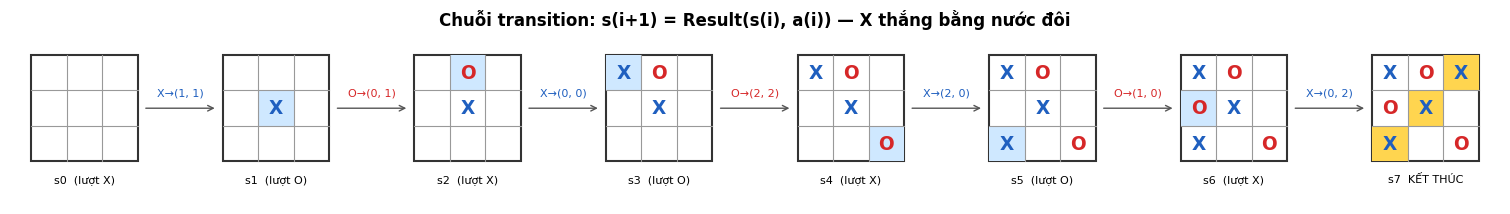

In [7]:
# ======================================================================
#  CÔNG CỤ VẼ: bàn cờ nhỏ, cây tìm kiếm (dùng lại ở Phần 4, 5, 6)
# ======================================================================
COLORS = {X: '#1f5fbf', O: '#d62728'}


def draw_board(ax, game, board, x, y, size=1.0, highlight=(), last=None,
               face='white', edge='#333', lw=1.5, alpha=1.0, fontsize=None):
    """Vẽ bàn cờ nhỏ có tâm (x, y), cạnh dài 'size' (đơn vị tọa độ của ax)."""
    n = game.n
    cell = size / n
    x0, y0 = x - size / 2, y - size / 2
    fontsize = fontsize or 40 / n
    ax.add_patch(Rectangle((x0, y0), size, size, facecolor=face, edgecolor=edge, lw=lw, alpha=alpha, zorder=2))
    for idx, ch in enumerate(board):
        r, c = divmod(idx, n)
        if idx in highlight or idx == last:              # tô nền ô thắng (vàng) / ô vừa đánh (xanh nhạt)
            ax.add_patch(Rectangle((x0 + c * cell, y0 + size - (r + 1) * cell), cell, cell,
                                   facecolor='#ffd54f' if idx in highlight else '#cfe8ff',
                                   edgecolor='none', alpha=alpha, zorder=2.5))
        if ch != EMPTY:
            ax.text(x0 + (c + .5) * cell, y0 + size - (r + .5) * cell, ch, ha='center', va='center',
                    fontsize=fontsize, color=COLORS[ch], weight='bold', alpha=alpha, zorder=4)
    for i in range(1, n):                                # các đường kẻ ô
        ax.plot([x0 + i * cell] * 2, [y0, y0 + size], color='#999', lw=.8, alpha=alpha, zorder=3)
        ax.plot([x0, x0 + size], [y0 + i * cell] * 2, color='#999', lw=.8, alpha=alpha, zorder=3)


class TreeNode:
    """Một nút của cây tìm kiếm: trạng thái, hành động dẫn tới nó, các con, nhãn giá trị."""
    def __init__(self, state, action=None, parent=None):
        self.state, self.action, self.parent = state, action, parent
        self.children = []
        self.label = ''          # chữ hiện dưới nút (ví dụ minimax value)
        self.style = None        # None | 'best' (nước được chọn) | 'reply' (MIN chọn) | 'pruned' (bị cắt tỉa)

    def add(self, game, a):
        child = TreeNode(game.result(self.state, a), a, self)   # con sinh ra ĐÚNG bằng Result(s, a)
        self.children.append(child)
        return child

    def all_nodes(self):
        yield self
        for c in self.children:
            yield from c.all_nodes()


def _layout(root):
    """Xếp tọa độ: lá đặt lần lượt từ trái qua phải, nút cha nằm giữa các con."""
    counter = [0]
    def rec(node, depth):
        node.depth = depth
        if not node.children:
            node.x = counter[0]; counter[0] += 1
        else:
            for c in node.children:
                rec(c, depth + 1)
            node.x = (node.children[0].x + node.children[-1].x) / 2
    rec(root, 0)
    return counter[0], max(nd.depth for nd in root.all_nodes()) + 1


def draw_tree(game, root, title='', level_names=None, dx=1.35, dy=2.1):
    """Vẽ cây tìm kiếm: mỗi nút là một bàn cờ nhỏ, nhãn cạnh là (hàng, cột) của nước đi."""
    n_leaves, n_levels = _layout(root)
    fig, ax = plt.subplots(figsize=(max(8, n_leaves * dx * .95 + 1.5), n_levels * dy * .9 + .6))
    for node in root.all_nodes():
        x, y = node.x * dx, -node.depth * dy
        for c in node.children:                       # vẽ cạnh cha -> con
            cx, cy = c.x * dx, -c.depth * dy
            pruned = c.style == 'pruned'
            ax.plot([x, cx], [y - .5, cy + .5], color='#bbb' if pruned else '#555',
                    ls='--' if pruned else '-', lw=1, zorder=1)
            ax.text(x + (cx - x) * .72, (y - .5) + ((cy + .5) - (y - .5)) * .72, str(game.rc(c.action)),
                    fontsize=8, ha='center', va='center', color='#999' if pruned else '#333', zorder=5,
                    bbox=dict(boxstyle='round,pad=.15', fc='white', ec='none', alpha=.9))
        face, edge, lw, alpha = 'white', '#333', 1.5, 1.0
        if node.style == 'best':
            face, edge, lw = '#e8f5e9', '#2e7d32', 3
        elif node.style == 'reply':
            face, edge, lw = '#fff3e0', '#ef6c00', 3
        elif node.style == 'pruned':
            face, edge, alpha = '#f2f2f2', '#bbb', .35
        win = game.winning_line(node.state.board) or ()
        draw_board(ax, game, node.state.board, x, y, highlight=win, last=node.action,
                   face=face, edge=edge, lw=lw, alpha=alpha)
        if node.label:
            ax.text(x, y - .62, node.label, ha='center', va='top', fontsize=9, weight='bold',
                    color='#999' if node.style == 'pruned' else '#111', zorder=5)
    if level_names:
        for d in range(n_levels):
            ax.text(-dx * .9, -d * dy, level_names[d % len(level_names)], ha='right', va='center',
                    fontsize=10, color='#444', style='italic')
    ax.set_xlim(-dx * (2.4 if level_names else .8), (n_leaves - 1) * dx + .8)
    ax.set_ylim(-(n_levels - 1) * dy - 1.1, .75)
    ax.set_aspect('equal'); ax.axis('off')
    if title:
        ax.set_title(title, fontsize=13, weight='bold')
    plt.tight_layout()
    return fig


def draw_sequence(game, states, actions, title=''):
    """Vẽ chuỗi trạng thái s0 -a1-> s1 -a2-> s2 ... theo hàng ngang."""
    fig, ax = plt.subplots(figsize=(1.9 * len(states), 2.3))
    for i, s in enumerate(states):
        draw_board(ax, game, s.board, i * 1.8, 0, highlight=game.winning_line(s.board) or (),
                   last=actions[i - 1] if i else None)
        ax.text(i * 1.8, -.7, f's{i}  (lượt {s.to_move})' if not game.terminal(s) else f's{i}  KẾT THÚC',
                ha='center', fontsize=8)
        if i:
            ax.annotate('', xy=(i * 1.8 - .55, 0), xytext=((i - 1) * 1.8 + .55, 0),
                        arrowprops=dict(arrowstyle='->', color='#555'))
            ax.text((i - .5) * 1.8, .12, f'{states[i-1].to_move}→{game.rc(actions[i-1])}',
                    ha='center', fontsize=8, color=COLORS[states[i - 1].to_move])
    ax.set_xlim(-.7, (len(states) - 1) * 1.8 + .7); ax.set_ylim(-.9, .7)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title, weight='bold')
    plt.tight_layout()
    return fig


seq_moves = [4, 1, 0, 8, 6, 3, 2]
seq_states = [game.initial_state()]
for a in seq_moves:
    seq_states.append(game.result(seq_states[-1], a))
draw_sequence(game, seq_states, seq_moves, 'Chuỗi transition: s(i+1) = Result(s(i), a(i)) — X thắng bằng nước đôi')
plt.show()

---
# PHẦN 4 — CÂY TÌM KIẾM (GAME TREE)

Slide tr. 6: *"The search tree is called **game tree**… it consists of the set of paths through the state space representing all possible games."* Slide tr. 7 minh họa *partial game tree* của Tic-Tac-Toe: 1 nút gốc, 9 nút mức 1, 9×8 nút mức 2…

### 4.1 Cây tìm kiếm bắt đầu từ trạng thái ban đầu s0 (21 trạng thái)
**Cách dựng cây:**
1. **Gốc** = s0 (bàn trống, X = Max đi).
2. **Mức 1**: mở rộng **đầy đủ** 9 nước đi của X.
3. **Mức 2**: chọn **ngẫu nhiên 3** nút ở mức 1, mỗi nút mở rộng **ngẫu nhiên 3** nước của O (Min).
4. **Mức 3**: chọn ngẫu nhiên 1 nút ở mức 2, mở rộng 2 nước của X.

⇒ Tổng số trạng thái = 1 + 9 + 9 + 2 = **21** (trong khoảng 10–30). Mọi nút con đều sinh bằng `game.result(...)` nên **chắc chắn đúng Transition Function**.

Cây có 21 trạng thái; mọi cạnh đều thỏa Result(cha, a) = con ✔

.........  (lượt X)
    X........  (lượt O)  <-- X đánh (0, 0)
    .X.......  (lượt O)  <-- X đánh (0, 1)
    ..X......  (lượt O)  <-- X đánh (0, 2)
        O.X......  (lượt X)  <-- O đánh (0, 0)
            OXX......  (lượt O)  <-- X đánh (0, 1)
            O.X..X...  (lượt O)  <-- X đánh (1, 2)
        ..X..O...  (lượt X)  <-- O đánh (1, 2)
        ..X.....O  (lượt X)  <-- O đánh (2, 2)
    ...X.....  (lượt O)  <-- X đánh (1, 0)
        .O.X.....  (lượt X)  <-- O đánh (0, 1)
        ..OX.....  (lượt X)  <-- O đánh (0, 2)
        ...X.O...  (lượt X)  <-- O đánh (1, 2)
    ....X....  (lượt O)  <-- X đánh (1, 1)
    .....X...  (lượt O)  <-- X đánh (1, 2)
        O....X...  (lượt X)  <-- O đánh (0, 0)
        .O...X...  (lượt X)  <-- O đánh (0, 1)
        ....OX...  (lượt X)  <-- O đánh (1, 1)
    ......X..  (lượt O)  <-- X đánh (2, 0)
    .......X.  (lượt O)  <-- X đánh (2, 1)
    ........X  (lượt O)  <-- X đánh (2, 2)


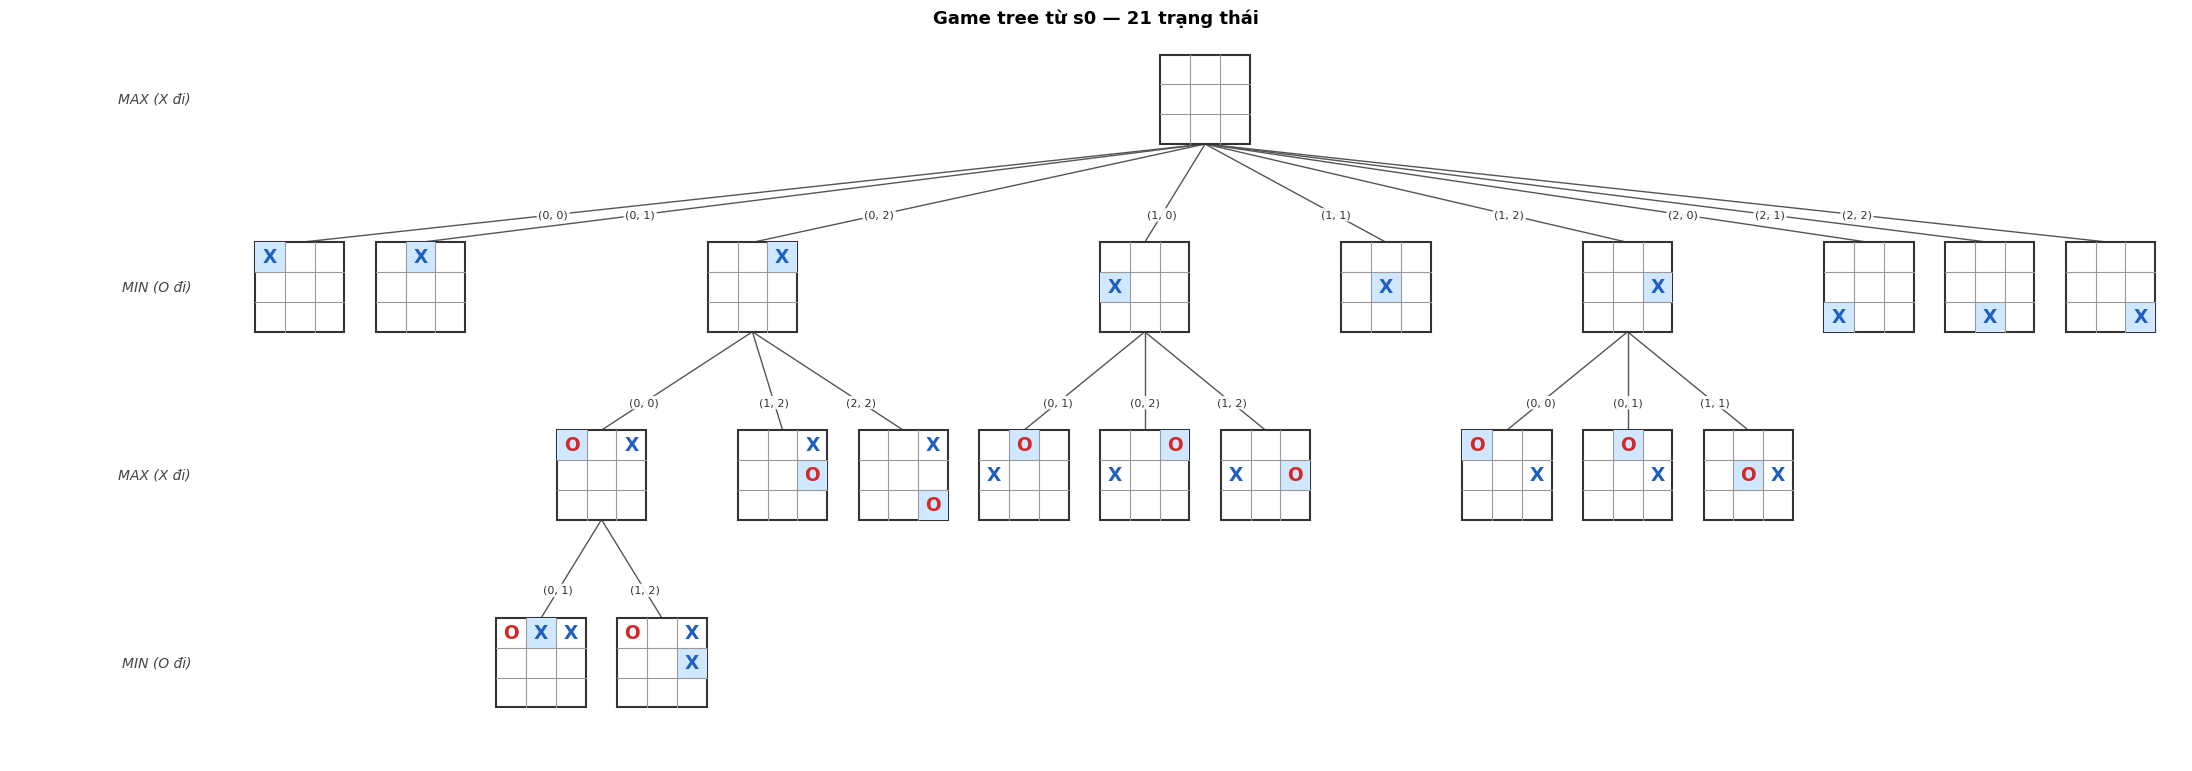

In [8]:
rng = random.Random(7)                                   # hạt giống cố định để cây luôn giống nhau
tree1 = TreeNode(game.initial_state())
for a in game.actions(tree1.state):                      # mức 1: đầy đủ 9 nước của X
    tree1.add(game, a)
level2 = []
for node in sorted(rng.sample(tree1.children, 3), key=lambda n: n.action):   # mức 2: 3 nút x 3 con
    for a in sorted(rng.sample(game.actions(node.state), 3)):
        level2.append(node.add(game, a))
node3 = rng.choice(level2)                               # mức 3: 1 nút x 2 con
for a in sorted(rng.sample(game.actions(node3.state), 2)):
    node3.add(game, a)

n_nodes = sum(1 for _ in tree1.all_nodes())
assert 10 <= n_nodes <= 30, 'Số trạng thái trong cây phải từ 10 đến 30'
for nd in tree1.all_nodes():                             # kiểm tra lại: mọi cạnh đều đúng Result(cha, a) = con
    for c in nd.children:
        assert c.state == game.result(nd.state, c.action)
print(f'Cây có {n_nodes} trạng thái; mọi cạnh đều thỏa Result(cha, a) = con ✔\n')


def print_tree(game, node, indent=''):
    act = '' if node.action is None else f'  <-- {node.parent.state.to_move} đánh {game.rc(node.action)}'
    print(f'{indent}{node.state.board}  (lượt {node.state.to_move}){act}')
    for c in node.children:
        print_tree(game, c, indent + '    ')

print_tree(game, tree1)
draw_tree(game, tree1, f'Game tree từ s0 — {n_nodes} trạng thái', level_names=['MAX (X đi)', 'MIN (O đi)'])
plt.show()

> Giá trị **minimax value (MV)** của từng nút cần thuật toán ở Phần 5, nên hình cây **có kèm MV** được vẽ lại ở mục **"4.1 (tiếp)"** ngay sau khi định nghĩa hàm `solve()` (cuối mục 5.9).

### 4.2 Cây Minimax đầy đủ từ một thế cờ giữa ván + cắt tỉa Alpha-Beta
Slide tr. 16 minh họa cách **back-up minimax values** từ lá lên gốc. Ta làm đúng như vậy với một thế cờ giữa ván, AI cầm **O** (Max = O), còn 4 ô trống — cây con đầy đủ có **30 trạng thái**:

```
 X X .
 . O O      ← đến lượt O (MAX = O = AI)
 . X .
```
- Mức chẵn: nút **MAX** (O chọn MV **lớn nhất**); mức lẻ: nút **MIN** (X chọn MV **nhỏ nhất**).
- Nút **viền xanh** = nước Max chọn; nút **mờ, cạnh đứt nét** = nút **Alpha-Beta không cần xét** (bị cắt tỉa).

Cây có 30 trạng thái. Minimax duyệt 30 nút, Alpha-Beta chỉ duyệt 14 nút (cắt bỏ 16 nút). MV của gốc = +1 ở cả hai thuật toán.


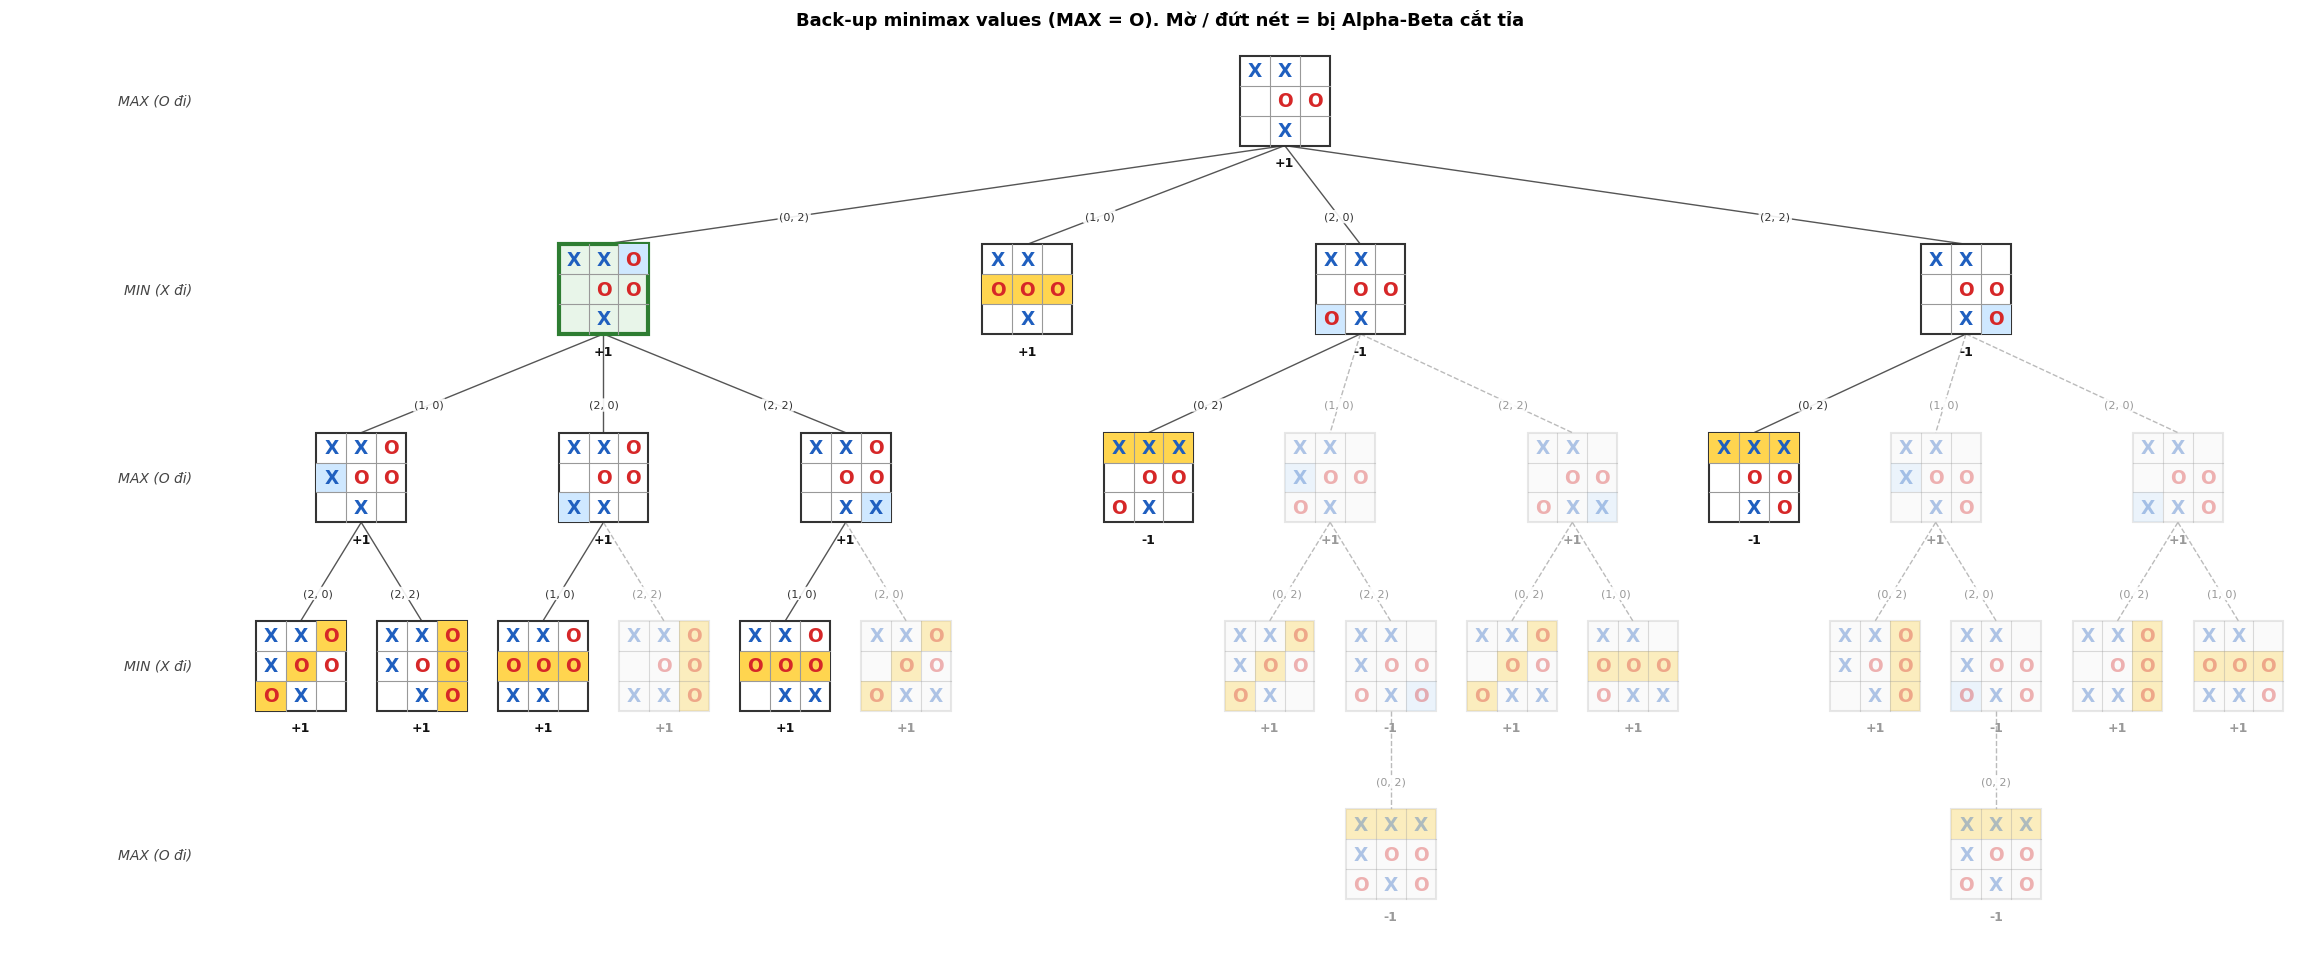

In [9]:
def build_full_tree(game, state):
    """Dựng TOÀN BỘ cây con từ 'state' đến các trạng thái kết thúc."""
    root = TreeNode(state)
    def rec(node):
        if not game.terminal(node.state):
            for a in game.actions(node.state):
                rec(node.add(game, a))
    rec(root)
    return root


def minimax_on_tree(game, node, player):
    """Back-up minimax values (slide tr. 16): lá lấy Utility, MAX lấy max, MIN lấy min."""
    if not node.children:
        node.value = game.utility(node.state, player)
    else:
        vals = [minimax_on_tree(game, c, player) for c in node.children]
        node.value = max(vals) if node.state.to_move == player else min(vals)
    return node.value


def fmt_ab(v):
    return {math.inf: '+∞', -math.inf: '-∞'}.get(v, f'{v:g}')


def alphabeta_on_tree(game, node, player, alpha, beta, visited, log, depth=0):
    """Alpha-Beta trên cây tường minh, ghi lại nút đã thăm và nhật ký α, β theo kiểu slide examples."""
    visited.add(id(node))
    max_player = node.state.to_move == player
    where = 'gốc' if node.action is None else f'{node.parent.state.to_move}→{game.rc(node.action)}'
    pad = '   ' * depth
    if not node.children:
        log.append(f'{pad}• Lá ({where}): Utility = {fmt_ab(node.value)}')
        return node.value
    log.append(f'{pad}{"MAX" if max_player else "MIN"} ({where}) nhận α={fmt_ab(alpha)}, β={fmt_ab(beta)}')
    best = -math.inf if max_player else math.inf
    for i, c in enumerate(node.children):
        val = alphabeta_on_tree(game, c, player, alpha, beta, visited, log, depth + 1)
        if max_player:
            best = max(best, val); old = alpha; alpha = max(alpha, best)
            log.append(f'{pad}  α = max({fmt_ab(old)}, {fmt_ab(val)}) = {fmt_ab(alpha)}')
        else:
            best = min(best, val); old = beta; beta = min(beta, best)
            log.append(f'{pad}  β = min({fmt_ab(old)}, {fmt_ab(val)}) = {fmt_ab(beta)}')
        if alpha >= beta:                                  # điều kiện cắt tỉa α >= β
            rest = [game.rc(x.action) for x in node.children[i + 1:]]
            if rest:
                log.append(f'{pad}  ✂ α={fmt_ab(alpha)} ≥ β={fmt_ab(beta)} → cắt tỉa các nhánh {rest}')
            break
    return best


mid_state = State('XX..OO.X.', O)                  # thế cờ giữa ván, đến lượt O
tree2 = build_full_tree(game, mid_state)
minimax_on_tree(game, tree2, O)
visited, ab_log = set(), []
alphabeta_on_tree(game, tree2, O, -math.inf, math.inf, visited, ab_log)

best_child = max(tree2.children, key=lambda c: c.value)   # Max chọn MV lớn nhất (bằng nhau -> nước đầu tiên)
for nd in tree2.all_nodes():
    nd.label = f'{nd.value:+g}' if nd.value else '0'
    if id(nd) not in visited:
        nd.style = 'pruned'
best_child.style = 'best'

total = sum(1 for _ in tree2.all_nodes())
print(f'Cây có {total} trạng thái. Minimax duyệt {total} nút, Alpha-Beta chỉ duyệt {len(visited)} nút '
      f'(cắt bỏ {total - len(visited)} nút). MV của gốc = {tree2.value:+g} ở cả hai thuật toán.')
draw_tree(game, tree2, 'Back-up minimax values (MAX = O). Mờ / đứt nét = bị Alpha-Beta cắt tỉa',
          level_names=['MAX (O đi)', 'MIN (X đi)'])
plt.show()

In [10]:
print('NHẬT KÝ ALPHA-BETA (thụt lề = độ sâu):\n')
print('\n'.join(ab_log))

# So sánh với biến thể Utility "thắng nhanh"
tree2f = build_full_tree(game_fast, mid_state)
minimax_on_tree(game_fast, tree2f, O)
display(pd.DataFrame({'Nước của O (hàng, cột)': [game.rc(c.action) for c in tree2.children],
                      'MV với Utility +1/0/-1 (slide)': [c.value for c in tree2.children],
                      'MV với Utility thắng nhanh ±(1+ô trống)': [c.value for c in tree2f.children]}))

NHẬT KÝ ALPHA-BETA (thụt lề = độ sâu):

MAX (gốc) nhận α=-∞, β=+∞
   MIN (O→(0, 2)) nhận α=-∞, β=+∞
      MAX (X→(1, 0)) nhận α=-∞, β=+∞
         • Lá (O→(2, 0)): Utility = 1
        α = max(-∞, 1) = 1
         • Lá (O→(2, 2)): Utility = 1
        α = max(1, 1) = 1
     β = min(+∞, 1) = 1
      MAX (X→(2, 0)) nhận α=-∞, β=1
         • Lá (O→(1, 0)): Utility = 1
        α = max(-∞, 1) = 1
        ✂ α=1 ≥ β=1 → cắt tỉa các nhánh [(2, 2)]
     β = min(1, 1) = 1
      MAX (X→(2, 2)) nhận α=-∞, β=1
         • Lá (O→(1, 0)): Utility = 1
        α = max(-∞, 1) = 1
        ✂ α=1 ≥ β=1 → cắt tỉa các nhánh [(2, 0)]
     β = min(1, 1) = 1
  α = max(-∞, 1) = 1
   • Lá (O→(1, 0)): Utility = 1
  α = max(1, 1) = 1
   MIN (O→(2, 0)) nhận α=1, β=+∞
      • Lá (X→(0, 2)): Utility = -1
     β = min(+∞, -1) = -1
     ✂ α=1 ≥ β=-1 → cắt tỉa các nhánh [(1, 0), (2, 2)]
  α = max(1, -1) = 1
   MIN (O→(2, 2)) nhận α=1, β=+∞
      • Lá (X→(0, 2)): Utility = -1
     β = min(+∞, -1) = -1
     ✂ α=1 ≥ β=-1 → cắt t

,"Nước của O (hàng, cột)",MV với Utility +1/0/-1 (slide),MV với Utility thắng nhanh ±(1+ô trống)
0,"(0, 2)",1,2
1,"(1, 0)",1,4
2,"(2, 0)",-1,-3
3,"(2, 2)",-1,-3


**Giải thích (đọc từ lá lên gốc, đúng như slide tr. 16):**
1. **Lá** (trạng thái kết thúc) nhận Utility theo Max = O: O thắng → **+1**, X thắng → **−1**, hòa → **0**.
2. Nút **MIN** (lượt X) lấy MV **nhỏ nhất** của các con; nút **MAX** (lượt O) lấy MV **lớn nhất**.
3. Ở gốc, O có 4 lựa chọn: **(0,2)** chặn X rồi thắng sau → **+1**; **(1,0)** **thắng ngay** hàng giữa → **+1**; **(2,0)** hoặc **(2,2)** bỏ mặc X → X thắng ở (0,2) → **−1**.
4. **Alpha-Beta:** sau khi nhánh (0,2) cho MV = +1 thì α = +1 — đã là giá trị **lớn nhất có thể**. Ở mỗi nhánh MIN còn lại, vừa thấy con đầu tiên cho giá trị ≤ α là **α ≥ β** → cắt tỉa ngay (xem các dòng ✂). Kết quả gốc vẫn là +1, giống hệt Minimax.

> 💡 **Hạn chế của Utility +1/0/−1:** nước **(0,2)** (thắng chậm) và **(1,0)** (thắng ngay) có **cùng MV = +1**, Minimax chọn nước gặp trước là (0,2). Kết quả vẫn **tối ưu** (vẫn thắng) nhưng "dài dòng". Với **Utility thắng nhanh** (bảng trên) thì (1,0) = **+4** > (0,2) = **+2** → AI thắng ngay. Vì vậy giao diện Phần 6 có tùy chọn này.

---
# PHẦN 5 — HIỆN THỰC CÁC GIẢI THUẬT TÌM KIẾM

Slide tr. 8 chia các phương pháp cho trò chơi đối kháng làm 2 nhóm; nhóm hiện thực **đầy đủ các giải thuật trong slide** + 1 kỹ thuật mở rộng:

| Nhóm (slide tr. 8) | # | Giải thuật | Trang slide |
|---|---|---|---|
| **Exact methods** — tối ưu | 1 | **AND-OR Search** (coi nước của đối thủ là hành động không xác định) | tr. 9–12 |
| | 2 | **Minimax Search** | tr. 13–19 |
| | 3 | **Alpha-Beta Pruning** | tr. 20–24 |
| | 4 | **Alpha-Beta + Move Ordering** | tr. 25–27 |
| | 5 | *(mở rộng)* **Alpha-Beta + Move Ordering + Bảng chuyển vị + Đối xứng** | — |
| **Heuristic methods** — khi cây quá lớn | 6 | **Heuristic Alpha-Beta Tree Search** (cut-off + Eval h1/h2, forward pruning) | tr. 29–35 |
| | 7 | **Pure Monte Carlo Search** và **Monte Carlo Tree Search (UCB1)** | tr. 36–44 |

### 5.0 Công cụ đo lường chung
Mỗi thuật toán ghi lại: **số nút đã duyệt**, **độ sâu lớn nhất**, **số lần cắt tỉa**, **số lần tra bảng chuyển vị**, **thời gian**, **bộ nhớ đỉnh** — để so sánh ở mục 5.11. Có thể đặt **giới hạn số nút** để chương trình không bị "treo" khi bàn quá lớn.

In [11]:
INF = math.inf


class SearchLimitExceeded(Exception):
    """Ném ra khi thuật toán duyệt quá số nút cho phép (tránh treo máy ở bàn lớn)."""
    pass


class Stats:
    """Thống kê quá trình tìm kiếm."""
    def __init__(self, max_nodes=None):
        self.nodes = 0          # số nút (trạng thái) đã thăm / mô phỏng
        self.max_depth = 0      # độ sâu lớn nhất đã đi tới
        self.cutoffs = 0        # số lần cắt tỉa alpha-beta
        self.tt_hits = 0        # số lần lấy được kết quả từ bảng chuyển vị
        self.tt_size = 0        # số mục trong bảng chuyển vị / số nút của cây MCTS
        self.max_nodes = max_nodes
        self.time_ms = 0.0      # thời gian chạy (mili giây)
        self.peak_kb = None     # bộ nhớ đỉnh (KB), chỉ đo khi được yêu cầu

    def visit(self, depth):
        """Gọi mỗi khi thăm một nút."""
        self.nodes += 1
        if depth > self.max_depth:
            self.max_depth = depth
        if self.max_nodes is not None and self.nodes > self.max_nodes:
            raise SearchLimitExceeded(f'Vượt quá {self.max_nodes:,} nút')


@dataclass
class SearchResult:
    algorithm: str      # tên thuật toán
    move: int           # nước đi được chọn (chỉ số ô)
    value: float        # MV (hoặc giá trị ước lượng) của nước đó, theo góc nhìn người đang đi (Max)
    move_values: dict   # {ô: (giá trị, chính_xác?)} cho các nước ở gốc -> để vẽ lên giao diện
    stats: Stats

### 5.1 Giải thuật 1 — AND-OR Search (Exact method: Nondeterministic actions)
**Ý tưởng (slide tr. 10–12):** coi **đối thủ là một phần của môi trường**, nước đi của đối thủ là **hành động không xác định** (`Results(s, a)` là *một tập* trạng thái).
- **OR node** (lượt **Max**): chỉ cần **chọn 1 hành động** dẫn tới thành công.
- **AND node** (lượt **Min**): phải thành công với **mọi** nước đi có thể của đối thủ (*"consider all outcomes"*).
- **Mục tiêu:** tìm một **cây con** chỉ có **lá thắng** → trích ra **kế hoạch có điều kiện (conditional plan)**: "đi a; nếu đối thủ đi b1 thì …, nếu b2 thì …". Có kế hoạch như vậy nghĩa là **chơi tối ưu, thắng chắc chắn**.
- *"Abandon subtree if a loss is possible"* — ở AND node, chỉ cần **một** nước của đối thủ làm hỏng là bỏ cả cây con.

Ta cài đặt đúng thuật toán AND-OR DFS của slide tr. 12 (có kiểm tra vòng lặp *"don't follow loops"* dù Tic-Tac-Toe không có vòng lặp — slide tr. 7). Thêm tham số `goal`: `'win'` (thắng chắc) hoặc `'not_lose'` (ít nhất hòa).

In [12]:
def and_or_search(game, state, goal='win', stats=None):
    """AND-OR DFS (slide tr. 12). Trả về kế hoạch có điều kiện [a, {b: kế_hoạch_con}] hoặc None (failure)."""
    stats = stats or Stats()
    player = state.to_move                                   # Max
    success = (lambda u: u > 0) if goal == 'win' else (lambda u: u >= 0)

    def or_search(s, path, depth):                           # OR node: lượt của Max
        stats.visit(depth)
        if game.terminal(s):
            return [] if success(game.utility(s, player)) else None
        if s in path:                                        # don't follow loops
            return None
        for a in game.empty_cells(s.board):                  # thử từng nước của Max (chọn 1)
            plan = and_search(game.result(s, a), path | {s}, depth + 1)
            if plan is not None:
                return [a, plan]                             # tìm được 1 nước thành công là đủ
        return None

    def and_search(s, path, depth):                          # AND node: lượt của Min
        stats.visit(depth)
        if game.terminal(s):                                 # Max vừa thắng/hòa ở nước trước
            return {} if success(game.utility(s, player)) else None
        plans = {}
        for b in game.empty_cells(s.board):                  # xét MỌI nước của Min
            p = or_search(game.result(s, b), path | {s}, depth + 1)
            if p is None:
                return None                                  # abandon subtree if a loss is possible
            plans[b] = p                                     # "nếu Min đi b thì làm theo p"
        return plans

    return or_search(state, frozenset(), 0)


def print_plan(game, plan, state, indent=''):
    """In kế hoạch có điều kiện dạng if-then-else lồng nhau."""
    a, branches = plan
    s1 = game.result(state, a)
    print(f'{indent}{state.to_move} đánh {game.rc(a)}' + ('  → THẮNG' if game.winner(s1.board) == state.to_move else ''))
    for b, sub in branches.items():
        s2 = game.result(s1, b)
        print(f'{indent}   nếu {s1.to_move} đánh {game.rc(b)}:')
        if sub:
            print_plan(game, sub, s2, indent + '      ')


def plan_size(plan):
    """Số quyết định (OR node) trong kế hoạch."""
    if not plan:
        return 0
    return 1 + sum(plan_size(p) for p in plan[1].values())


fork_state = seq_states[4]            # bàn cờ sau 4 nước X4 O1 X0 O8 (dòng 5 của bảng transition)
print('Thế cờ (X đến lượt):'); print(game.pretty(fork_state.board))
st = Stats(); plan = and_or_search(game, fork_state, 'win', st)
print(f'\n→ Tìm được kế hoạch THẮNG CHẮC CHẮN ({plan_size(plan)} quyết định, duyệt {st.nodes} nút):')
print_plan(game, plan, fork_state)

rows = []
for g_name, goal in [('thắng chắc chắn', 'win'), ('không thua (ít nhất hòa)', 'not_lose')]:
    st = Stats(); t0 = time.perf_counter()
    p = and_or_search(game, game.initial_state(), goal, st)
    rows.append({'Từ s0 (bàn trống), mục tiêu': g_name, 'Có kế hoạch?': 'CÓ' if p else 'KHÔNG (failure)',
                 'Nước đầu': game.rc(p[0]) if p else '—', 'Số quyết định trong kế hoạch': plan_size(p),
                 'Số nút duyệt': st.nodes, 'Thời gian (ms)': round((time.perf_counter() - t0) * 1000, 1)})
display(pd.DataFrame(rows))

Thế cờ (X đến lượt):
X O .
. X .
. . O

→ Tìm được kế hoạch THẮNG CHẮC CHẮN (5 quyết định, duyệt 41 nút):
X đánh (1, 0)
   nếu O đánh (0, 2):
      X đánh (1, 2)  → THẮNG
   nếu O đánh (1, 2):
      X đánh (2, 0)  → THẮNG
   nếu O đánh (2, 0):
      X đánh (1, 2)  → THẮNG
   nếu O đánh (2, 1):
      X đánh (1, 2)  → THẮNG


,"Từ s0 (bàn trống), mục tiêu",Có kế hoạch?,Nước đầu,Số quyết định trong kế hoạch,Số nút duyệt,Thời gian (ms)
0,thắng chắc chắn,KHÔNG (failure),—,0,16159,34.2
1,không thua (ít nhất hòa),CÓ,"(0, 0)",177,966,2.1


**Nhận xét:**
- Ở thế cờ có **nước đôi**, AND-OR tìm ra kế hoạch thắng chắc chắn: in ra đúng dạng *"nested if-then-else statements"* như slide tr. 12.
- Từ **bàn trống**, **không tồn tại** kế hoạch thắng chắc chắn (failure) — vì đối thủ chơi đúng thì luôn hòa được. Nhưng có kế hoạch **"không thua"**.
- Hạn chế: AND-OR chỉ trả lời **có/không** đạt mục tiêu, không cho biết nước nào *tốt hơn* khi không có kế hoạch thắng → **Minimax** khái quát hóa bằng cách gán cho mỗi trạng thái một **giá trị** (slide tr. 17: *"Minimax is just a modification of the AND-OR Tree Search"*).

### 5.2 Giải thuật 2 — Minimax Search
**Ý tưởng (slide tr. 15):** gán cho mỗi trạng thái **minimax value** = utility đạt được nếu **cả hai chơi tối ưu** đến hết ván (*long-term reward*):

$$
\text{Minimax}(s)=\begin{cases}
\text{Utility}(s) & \text{nếu Terminal}(s)\\
\max_{a\in \text{Actions}(s)} \text{Minimax}(\text{Result}(s,a)) & \text{nếu lượt Max}\\
\min_{a\in \text{Actions}(s)} \text{Minimax}(\text{Result}(s,a)) & \text{nếu lượt Min}
\end{cases}
$$

*Optimal decision for Max: chọn hành động dẫn đến trạng thái có MV lớn nhất.* Cài đặt bằng **DFS** (slide tr. 17): `MAX-VALUE` biểu diễn OR search, `MIN-VALUE` biểu diễn AND search.

**Độ phức tạp (slide tr. 19):** thời gian **O(bᵐ)**, bộ nhớ **O(bm)** (ngăn xếp lời gọi đệ quy). Với Tic-Tac-Toe b = 9, m = 9.

In [13]:
def minimax_search(game, state, stats):
    """MINIMAX SEARCH (slide tr. 17): DFS tới mọi trạng thái kết thúc rồi back-up minimax value."""
    player = state.to_move                   # Max = người đang đến lượt ở gốc

    def max_value(s, depth):                 # OR: Max chọn hành động có MV lớn nhất
        stats.visit(depth)
        if game.terminal(s):
            return game.utility(s, player)
        v = -INF
        for a in game.empty_cells(s.board):
            v = max(v, min_value(game.result(s, a), depth + 1))
        return v

    def min_value(s, depth):                 # AND: Min chọn hành động có MV nhỏ nhất
        stats.visit(depth)
        if game.terminal(s):
            return game.utility(s, player)
        v = INF
        for a in game.empty_cells(s.board):
            v = min(v, max_value(game.result(s, a), depth + 1))
        return v

    stats.visit(0)                           # thăm gốc
    move_values = {}
    for a in game.empty_cells(state.board):  # gốc là nút MAX: tính MV của từng con (nút MIN)
        move_values[a] = (min_value(game.result(state, a), 1), True)
    best = max(move_values, key=lambda a: move_values[a][0])   # bằng nhau -> chọn nước xuất hiện trước
    return best, move_values[best][0], move_values

### 5.3 Giải thuật 3 — Alpha-Beta Pruning
**Ý tưởng (slide tr. 21):** *"Do not search parts of the tree if they do not make a difference to the outcome."* Ví dụ `max(5, min(3, x, y, …))` luôn bằng 5 — không cần biết x, y.

Duy trì cận **[α, β]** cho minimax value (examples tr. 8–9):
- **α** — dùng bởi **Max**: *"Minimax(s) will be at least α"*; là lựa chọn tốt nhất (lớn nhất) của Max trên đường đi hiện tại; ban đầu **−∞**. **Chỉ Max cập nhật α.**
- **β** — dùng bởi **Min**: *"Minimax(s) will be at most β"*; lựa chọn tốt nhất (nhỏ nhất) của Min; ban đầu **+∞**. **Chỉ Min cập nhật β.**
- **Điều kiện cắt tỉa: α ≥ β.** α, β chỉ truyền **xuống** các con; khi quay lui thì truyền **giá trị nút** lên trên.

Code dưới đây viết **đúng theo mã giả `alpha_beta(node, depth, alpha, beta, max_player)` của examples.pptx tr. 10**. Tham số `move_ordering=True` sẽ dùng ở mục 5.5.

> 💡 Ở gốc, nước đi có MV ≤ α hiện tại chỉ biết **cận trên** (giá trị thật ≤ v). Code ghi cờ `chính_xác = False`; giao diện hiển thị **"≤ v"**.

In [14]:
def alphabeta_search(game, state, stats, move_ordering=False):
    """ALPHA-BETA PRUNING (slide tr. 23, examples tr. 10). move_ordering=True: xét center, corner, rest trước."""
    player = state.to_move
    if move_ordering:
        moves = lambda board: [a for a in game.move_order if board[a] == EMPTY]
    else:
        moves = game.empty_cells

    def alpha_beta(s, alpha, beta, max_player, depth):
        stats.visit(depth)
        if game.terminal(s):
            return game.utility(s, player)
        if max_player:                                  # for MAX player
            max_val = -INF
            for a in moves(s.board):
                val = alpha_beta(game.result(s, a), alpha, beta, False, depth + 1)
                max_val = max(max_val, val)
                alpha = max(alpha, max_val)             # chỉ Max cập nhật alpha
                if alpha >= beta:                       # điều kiện cắt tỉa
                    stats.cutoffs += 1
                    break                               # Min phía trên sẽ không bao giờ đi vào đây
            return max_val
        else:                                           # for MIN player
            min_val = INF
            for a in moves(s.board):
                val = alpha_beta(game.result(s, a), alpha, beta, True, depth + 1)
                min_val = min(min_val, val)
                beta = min(beta, min_val)               # chỉ Min cập nhật beta
                if alpha >= beta:
                    stats.cutoffs += 1
                    break                               # Max phía trên đã có lựa chọn tốt hơn
            return min_val

    stats.visit(0)                                      # gốc = nút MAX
    alpha, best, best_v, move_values = -INF, None, -INF, {}
    for a in moves(state.board):
        v = alpha_beta(game.result(state, a), alpha, INF, False, 1)
        move_values[a] = (v, v > alpha)                 # v <= alpha: nhánh bị cắt, v chỉ là cận trên
        if v > best_v:
            best, best_v = a, v
        alpha = max(alpha, v)
    return best, best_v, move_values

### 5.4 Kiểm chứng bằng các bài tập và ví dụ trong slide
Để chắc chắn code đúng **như cách thầy/cô dạy**, ta chạy cùng ý tưởng Minimax/Alpha-Beta trên **các cây trong slide** và in ra từng bước:
1. **Exercise: Simple 2-Ply Game** (slide tr. 18): tính mọi MV, nước tối ưu của Max.
2. **Exercise … with Alpha-Beta Pruning** (slide tr. 24): tìm khoảng [α, β] của mọi nút, nhánh nào bị cắt.
3. **Exercise … with Alpha-Beta Pruning and Move Ordering** (slide tr. 26): thứ tự **a2, a1, a3**.
4. **Ví dụ A–G và bài Practice** trong *examples.pptx* (tr. 11–29).

**Quy ước khoảng [α, β] của một nút** (slide tr. 22): khi cây con **được duyệt hết** thì khoảng có độ dài 0 (**α = β = MV**); nút MIN bị cắt chỉ biết **[−∞, v]** (*"utility cannot be more than v"*); nút MAX bị cắt chỉ biết **[v, +∞]**.

BÀI 1 (slide tr. 18) — Minimax:
  MV các nút Min: [0, -5, -7] → MV(Max) = 0 → hành động tối ưu: a1


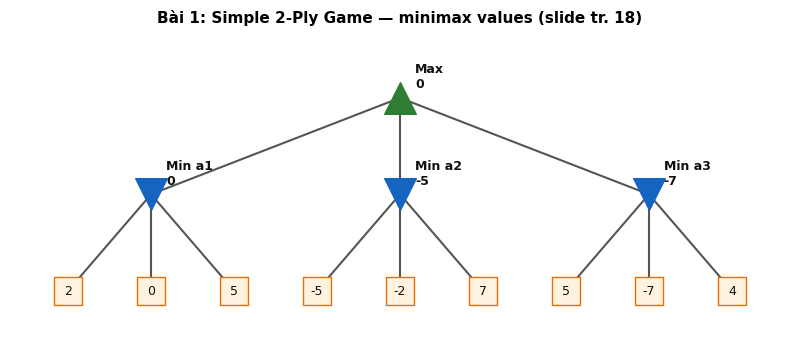


BÀI 2 (slide tr. 24) — Alpha-Beta, thứ tự a1, a2, a3
Nút Max (MAX) nhận α=-∞, β=+∞
   Nút Min a1 (MIN) nhận α=-∞, β=+∞
     tại Min a1: β = min(+∞, -5) = -5
     tại Min a1: β = min(-5, 2) = -5
     tại Min a1: β = min(-5, 5) = -5
   Nút Min a1 trả về -5
  tại Max: α = max(-∞, -5) = -5
   Nút Min a2 (MIN) nhận α=-5, β=+∞
     tại Min a2: β = min(+∞, 7) = 7
     tại Min a2: β = min(7, 0) = 0
     tại Min a2: β = min(0, 2) = 0
   Nút Min a2 trả về 0
  tại Max: α = max(-5, 0) = 0
   Nút Min a3 (MIN) nhận α=0, β=+∞
     tại Min a3: β = min(+∞, 5) = 5
     tại Min a3: β = min(5, -7) = -7
     ✂ α=0 ≥ β=-7 → cắt tỉa ['-4']
   Nút Min a3 trả về -7
  tại Max: α = max(0, -7) = 0
Nút Max trả về 0
  ⇒ MV(Max) = 0; khoảng [α,β]: Min a1=[-5, -5], Min a2=[0, 0], Min a3=[-∞, -7]; số lá bị cắt tỉa = 1
  ⇒ Chuỗi nước tối ưu: Max đi a2, Min đáp trả a2 (Utility = 0)


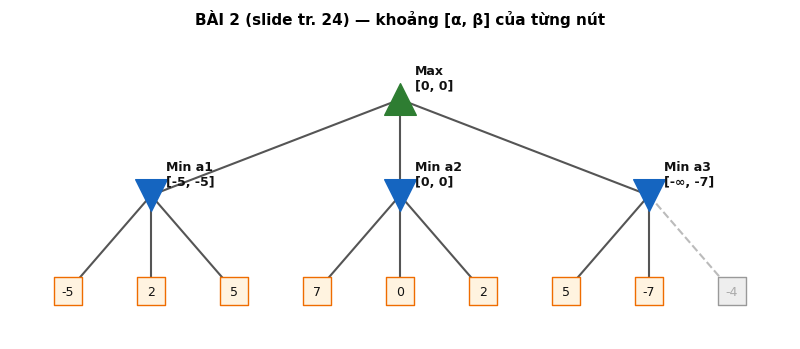


BÀI 3 (slide tr. 26) — Alpha-Beta + Move ordering a2, a1, a3
Nút Max (MAX) nhận α=-∞, β=+∞
   Nút Min a2 (MIN) nhận α=-∞, β=+∞
     tại Min a2: β = min(+∞, 7) = 7
     tại Min a2: β = min(7, 0) = 0
     tại Min a2: β = min(0, 2) = 0
   Nút Min a2 trả về 0
  tại Max: α = max(-∞, 0) = 0
   Nút Min a1 (MIN) nhận α=0, β=+∞
     tại Min a1: β = min(+∞, -5) = -5
     ✂ α=0 ≥ β=-5 → cắt tỉa ['2', '5']
   Nút Min a1 trả về -5
  tại Max: α = max(0, -5) = 0
   Nút Min a3 (MIN) nhận α=0, β=+∞
     tại Min a3: β = min(+∞, 5) = 5
     tại Min a3: β = min(5, -7) = -7
     ✂ α=0 ≥ β=-7 → cắt tỉa ['-4']
   Nút Min a3 trả về -7
  tại Max: α = max(0, -7) = 0
Nút Max trả về 0
  ⇒ MV(Max) = 0; khoảng [α,β]: Min a2=[0, 0], Min a1=[-∞, -5], Min a3=[-∞, -7]; số lá bị cắt tỉa = 3
  ⇒ Chuỗi nước tối ưu: Max đi a2, Min đáp trả a2 (Utility = 0)


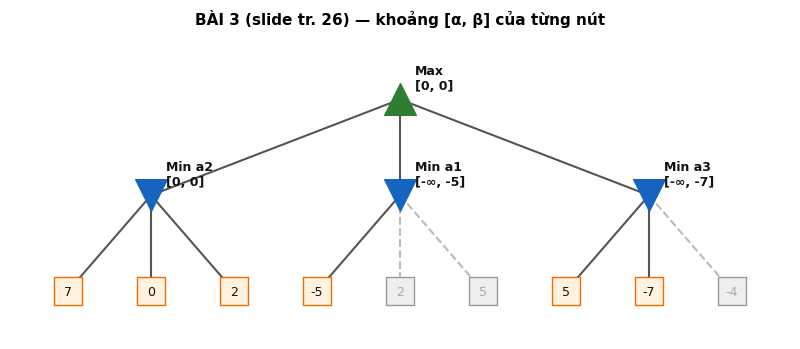

In [15]:
class Node:
    """Nút của cây số học trong slide: lá là số (hoặc None = giá trị không cần biết vì bị cắt tỉa)."""
    def __init__(self, name, *children):
        self.name, self.children = name, list(children)


def leaf_name(v):
    return '?' if v is None else f'{v:g}'


def minimax_tree(node, max_player=True):
    """Minimax trên cây số học. Trả về MV và ghi MV vào node.mv."""
    if not isinstance(node, Node):
        return node
    vals = [minimax_tree(c, not max_player) for c in node.children]
    node.mv = max(vals) if max_player else min(vals)
    return node.mv


def alphabeta_tree(node, alpha, beta, max_player, log, pruned, depth=0):
    """Alpha-Beta trên cây số học, in từng bước giống examples.pptx; ghi khoảng [α, β] vào node.interval."""
    if not isinstance(node, Node):
        assert node is not None, 'Lỗi: đã đọc một lá đáng lẽ bị cắt tỉa!'
        return node
    pad = '   ' * depth
    who = 'MAX' if max_player else 'MIN'
    log.append(f'{pad}Nút {node.name} ({who}) nhận α={fmt_ab(alpha)}, β={fmt_ab(beta)}')
    best = -INF if max_player else INF
    cut = False
    for i, c in enumerate(node.children):
        val = alphabeta_tree(c, alpha, beta, not max_player, log, pruned, depth + 1)
        if max_player:
            best = max(best, val); old = alpha; alpha = max(alpha, best)
            log.append(f'{pad}  tại {node.name}: α = max({fmt_ab(old)}, {fmt_ab(val)}) = {fmt_ab(alpha)}')
        else:
            best = min(best, val); old = beta; beta = min(beta, best)
            log.append(f'{pad}  tại {node.name}: β = min({fmt_ab(old)}, {fmt_ab(val)}) = {fmt_ab(beta)}')
        if alpha >= beta and i < len(node.children) - 1:
            rest = node.children[i + 1:]
            pruned.extend((id(node), j, node.children[j]) for j in range(i + 1, len(node.children)))
            names = [x.name if isinstance(x, Node) else leaf_name(x) for x in rest]
            log.append(f'{pad}  ✂ α={fmt_ab(alpha)} ≥ β={fmt_ab(beta)} → cắt tỉa {names}')
            cut = True
            break
    node.mv = best
    node.interval = (best, best) if not cut else ((-INF, best) if not max_player else (best, INF))
    log.append(f'{pad}Nút {node.name} trả về {fmt_ab(best)}')
    return best


def draw_number_tree(root, pruned=(), title='', show_interval=False):
    """Vẽ cây số học: ▲ = MAX, ▼ = MIN, ô vuông = lá; nhánh bị cắt tỉa đứt nét màu xám."""
    pruned_keys = {(pid, j) for pid, j, _ in pruned}       # (nút cha, chỉ số con) bị cắt tỉa
    nodes, edges, counter = [], [], [0]

    def layout(node, depth, is_pruned):
        if isinstance(node, Node):
            kids = []
            for j, c in enumerate(node.children):
                cp = is_pruned or (id(node), j) in pruned_keys
                kids.append((layout(c, depth + 1, cp), cp))
            x = sum(k[0] for k in kids) / len(kids)
            for cx, cp in kids:
                edges.append((x, -depth, cx, -depth - 1, cp))
        else:
            x = counter[0]; counter[0] += 1
        nodes.append((x, -depth, depth, node, is_pruned))
        return x

    layout(root, 0, False)
    fig, ax = plt.subplots(figsize=(max(6, counter[0] * .9), 3.6))
    for x1, y1, x2, y2, cp in edges:
        ax.plot([x1, x2], [y1, y2], color='#bbb' if cp else '#555', ls='--' if cp else '-', zorder=1)
    for x, y, depth, node, is_pruned in nodes:
        if isinstance(node, Node):
            color = '#bbb' if is_pruned else ('#2e7d32' if depth % 2 == 0 else '#1565c0')
            ax.scatter([x], [y], marker='^' if depth % 2 == 0 else 'v', s=520, color=color, zorder=2)
            label = node.name
            if hasattr(node, 'mv') and not is_pruned:
                label += (f'\n{node.mv:g}' if not show_interval
                          else f'\n[{fmt_ab(node.interval[0])}, {fmt_ab(node.interval[1])}]')
            ax.text(x + .18, y + .08, label, fontsize=9, va='bottom', weight='bold', color='#999' if is_pruned else '#111')
        else:
            ax.scatter([x], [y], marker='s', s=380, color='#eee' if is_pruned else '#fff3e0',
                       edgecolors='#999' if is_pruned else '#ef6c00', zorder=2)
            ax.text(x, y, leaf_name(node), ha='center', va='center', fontsize=9,
                    color='#aaa' if is_pruned else '#111', zorder=3)
    ax.set_xlim(-.7, counter[0] - .3); ax.set_ylim(min(n[1] for n in nodes) - .5, .7); ax.axis('off')
    ax.set_title(title, fontsize=11, weight='bold')
    plt.tight_layout()
    return fig


# ---------- Bài 1: Simple 2-Ply Game (slide tr. 18) ----------
ex1 = Node('Max', Node('Min a1', 2, 0, 5), Node('Min a2', -5, -2, 7), Node('Min a3', 5, -7, 4))
mv = minimax_tree(ex1)
best = max(range(3), key=lambda i: ex1.children[i].mv)
print('BÀI 1 (slide tr. 18) — Minimax:')
print('  MV các nút Min:', [c.mv for c in ex1.children], '→ MV(Max) =', mv, '→ hành động tối ưu: a' + str(best + 1))
draw_number_tree(ex1, title='Bài 1: Simple 2-Ply Game — minimax values (slide tr. 18)')
plt.show()

# ---------- Bài 2: với Alpha-Beta (slide tr. 24) ----------
def ex2_tree(order=(0, 1, 2)):
    subs = [Node('Min a1', -5, 2, 5), Node('Min a2', 7, 0, 2), Node('Min a3', 5, -7, -4)]
    return Node('Max', *[subs[i] for i in order])

for title, order in [('BÀI 2 (slide tr. 24) — Alpha-Beta, thứ tự a1, a2, a3', (0, 1, 2)),
                     ('BÀI 3 (slide tr. 26) — Alpha-Beta + Move ordering a2, a1, a3', (1, 0, 2))]:
    tree, log, pruned = ex2_tree(order), [], []
    v = alphabeta_tree(tree, -INF, INF, True, log, pruned)
    n_pruned_leaves = sum(1 if not isinstance(ch, Node) else len(ch.children) for _, _, ch in pruned)
    best = max(tree.children, key=lambda c: c.mv if c.interval[0] == c.interval[1] else -INF)
    print(f'\n{title}')
    print('\n'.join(log))
    print(f'  ⇒ MV(Max) = {v}; khoảng [α,β]: ' +
          ', '.join(f'{c.name}=[{fmt_ab(c.interval[0])}, {fmt_ab(c.interval[1])}]' for c in tree.children) +
          f'; số lá bị cắt tỉa = {n_pruned_leaves}')
    reply = min(range(len(best.children)), key=lambda i: best.children[i])
    print(f'  ⇒ Chuỗi nước tối ưu: Max đi {best.name.split()[1]}, Min đáp trả a{reply + 1} (Utility = {v})')
    draw_number_tree(tree, pruned, title=title.split(' — ')[0] + ' — khoảng [α, β] của từng nút', show_interval=True)
    plt.show()


===== VÍ DỤ examples.pptx tr. 11–18 =====
Nút A (MAX) nhận α=-∞, β=+∞
   Nút B (MIN) nhận α=-∞, β=+∞
      Nút D (MAX) nhận α=-∞, β=+∞
        tại D: α = max(-∞, 2) = 2
        tại D: α = max(2, 3) = 3
      Nút D trả về 3
     tại B: β = min(+∞, 3) = 3
      Nút E (MAX) nhận α=-∞, β=3
        tại E: α = max(-∞, 5) = 5
        ✂ α=5 ≥ β=3 → cắt tỉa ['9']
      Nút E trả về 5
     tại B: β = min(3, 5) = 3
   Nút B trả về 3
  tại A: α = max(-∞, 3) = 3
   Nút C (MIN) nhận α=3, β=+∞
      Nút F (MAX) nhận α=3, β=+∞
        tại F: α = max(3, 0) = 3
        tại F: α = max(3, 1) = 3
      Nút F trả về 1
     tại C: β = min(+∞, 1) = 1
     ✂ α=3 ≥ β=1 → cắt tỉa ['G']
   Nút C trả về 1
  tại A: α = max(3, 1) = 3
Nút A trả về 3
⇒ Giá trị tối ưu của Max = 3  (slide: 3)


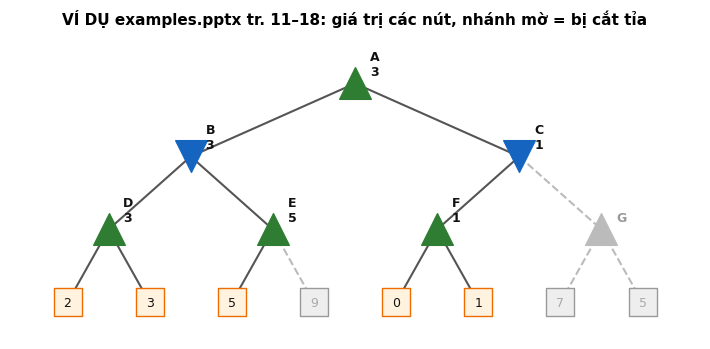


===== PRACTICE examples.pptx tr. 19–29 =====
Nút A (MAX) nhận α=-∞, β=+∞
   Nút B (MIN) nhận α=-∞, β=+∞
      Nút D (MAX) nhận α=-∞, β=+∞
        tại D: α = max(-∞, 3) = 3
        tại D: α = max(3, 5) = 5
      Nút D trả về 5
     tại B: β = min(+∞, 5) = 5
      Nút E (MAX) nhận α=-∞, β=5
        tại E: α = max(-∞, 6) = 6
        ✂ α=6 ≥ β=5 → cắt tỉa ['?']
      Nút E trả về 6
     tại B: β = min(5, 6) = 5
   Nút B trả về 5
  tại A: α = max(-∞, 5) = 5
   Nút C (MIN) nhận α=5, β=+∞
      Nút F (MAX) nhận α=5, β=+∞
        tại F: α = max(5, 1) = 5
        tại F: α = max(5, 2) = 5
      Nút F trả về 2
     tại C: β = min(+∞, 2) = 2
     ✂ α=5 ≥ β=2 → cắt tỉa ['G']
   Nút C trả về 2
  tại A: α = max(5, 2) = 5
Nút A trả về 5
⇒ Giá trị tối ưu của Max = 5  (slide: 5)


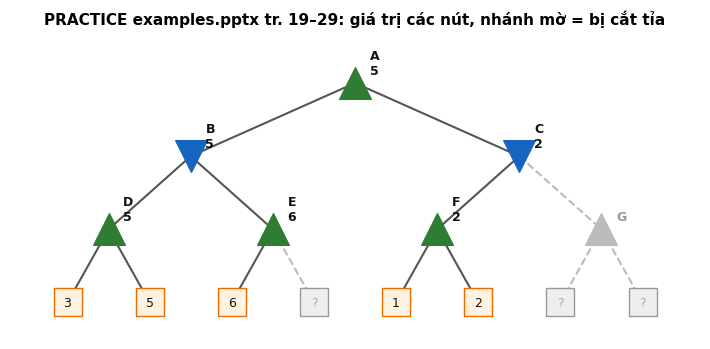

In [16]:
# ---------- Ví dụ A–G và Practice trong examples.pptx (tr. 11–29) ----------
# None = lá bị cắt tỉa nên slide không cần ghi giá trị; code sẽ báo lỗi nếu lỡ đọc lá này.
example = Node('A', Node('B', Node('D', 2, 3), Node('E', 5, 9)), Node('C', Node('F', 0, 1), Node('G', 7, 5)))
practice = Node('A', Node('B', Node('D', 3, 5), Node('E', 6, None)), Node('C', Node('F', 1, 2), Node('G', None, None)))

for title, tree in [('VÍ DỤ examples.pptx tr. 11–18', example), ('PRACTICE examples.pptx tr. 19–29', practice)]:
    log, pruned = [], []
    v = alphabeta_tree(tree, -INF, INF, True, log, pruned)
    print(f'\n===== {title} =====')
    print('\n'.join(log))
    print(f'⇒ Giá trị tối ưu của Max = {v}  (slide: {"3" if tree is example else "5"})')
    draw_number_tree(tree, pruned, title=f'{title}: giá trị các nút, nhánh mờ = bị cắt tỉa')
    plt.show()

**Kết quả khớp với lời giải trong slide:**
- **Bài 1:** MV các nút Min = 0, −5, −7 ⇒ MV(Max) = **0**, hành động tối ưu **a1**.
- **Bài 2** (thứ tự a1, a2, a3): Max = **0**, nước tối ưu **a2**; chỉ **1 lá (−4)** bị cắt.
- **Bài 3** (move ordering **a2, a1, a3**): kết quả vẫn là **0** nhưng cắt được **3 lá** → minh chứng *"pruning is more effective if good alpha-beta bounds can be found in the first few checked subtrees"* (slide tr. 25).
- **Ví dụ A–G:** E bị cắt nhánh phải (α = 5 ≥ β = 3), cả cây con **G** bị cắt, giá trị tối ưu **3**. **Practice:** giá trị tối ưu **5** — đúng như slide. Các lá `?` (None) **không hề bị đọc** (nếu bị đọc code sẽ báo lỗi) ⇒ cắt tỉa đúng.

### 5.5 Giải thuật 4 — Alpha-Beta + Move Ordering
**Ý tưởng (slide tr. 25):** cắt tỉa hiệu quả hơn nếu tìm được cận α, β tốt **ngay từ những cây con đầu tiên** ⇒ **xét các nước tốt trước**. Giống *Greedy Best-first Search*, cần **kiến thức chuyên gia (heuristic)** để biết nước nào tốt. Slide tr. 27 dùng heuristic **"center, corner, rest"** (ô giữa → 4 góc → các ô còn lại) — chính là `game.move_order`.

Ta **tái hiện bảng ở slide tr. 27**:

In [17]:
s0 = game.initial_state()
st_mm, st_ab, st_mo = Stats(), Stats(), Stats()
t = time.perf_counter(); minimax_search(game, s0, st_mm); t_mm = time.perf_counter() - t
t = time.perf_counter(); alphabeta_search(game, s0, st_ab); t_ab = time.perf_counter() - t
t = time.perf_counter(); alphabeta_search(game, s0, st_mo, move_ordering=True); t_mo = time.perf_counter() - t
display(pd.DataFrame({
    'Method (slide tr. 27)': ['Minimax Search', '+ Alpha-Beta Pruning', '+ Move ordering (center, corner, rest)'],
    'Searched Nodes — slide': ['549,946', '18,297', '7,275'],
    'Searched Nodes — code của nhóm': [f'{st_mm.nodes:,}', f'{st_ab.nodes:,}', f'{st_mo.nodes:,}'],
    'Search Time — slide': ['13 s', '660 ms', '202 ms'],
    'Search Time — máy chạy notebook': [f'{t_mm:.2f} s', f'{t_ab * 1000:.0f} ms', f'{t_mo * 1000:.0f} ms'],
}))

,Method (slide tr. 27),Searched Nodes — slide,Searched Nodes — code của nhóm,Search Time — slide,Search Time — máy chạy notebook
0,Minimax Search,"549,946","549,946",13 s,1.03 s
1,+ Alpha-Beta Pruning,"18,297","18,297",660 ms,38 ms
2,"+ Move ordering (center, corner, rest)","7,275","7,275",202 ms,15 ms


**Số nút duyệt khớp CHÍNH XÁC với slide** (549.946 → 18.297 → 7.275) ⇒ cài đặt Minimax, Alpha-Beta và Move ordering **đúng như bài giảng**. Thời gian khác nhau do cấu hình máy, nhưng tỉ lệ giảm tương tự: Alpha-Beta giảm ~30 lần số nút, move ordering giảm thêm ~2,5 lần.

### 5.6 Giải thuật 5 *(mở rộng)* — Alpha-Beta + Move Ordering + Bảng chuyển vị + Đối xứng
Đề tài yêu cầu *"nếu không gian tìm kiếm lớn, nên áp dụng các phương pháp thu hẹp không gian tìm kiếm"*. Ngoài cắt tỉa và move ordering của slide, nhóm thêm 2 kỹ thuật xử lý đúng vấn đề **redundant path** mà slide tr. 7 chỉ ra:

**(a) Bảng chuyển vị (Transposition Table – TT):** từ điển `{trạng thái: giá trị}` — mỗi bàn cờ chỉ tính **một lần**, gặp lại thì tra bảng (ý tưởng *memoization*). Vì Alpha-Beta có thể trả về giá trị "bị cắt" (chỉ là cận), mỗi mục lưu kèm **cờ**: `EXACT` (chính xác), `LOWER` (giá trị thật ≥ v), `UPPER` (giá trị thật ≤ v).

**(b) Gộp đối xứng:** bàn cờ vuông có **8 phép đối xứng** (4 quay + 4 lật); các bàn đối xứng có **cùng minimax value** ⇒ dùng **dạng chuẩn** (`canonical`) làm khóa TT. Ở gốc, các nước đối xứng chỉ tính một lần: bàn trống 9 nước ⇒ chỉ **3 nước khác nhau** (giữa, góc, cạnh).

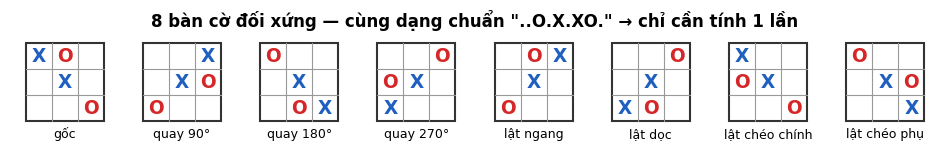

Ở bàn trống, 9 nước đi đầu tiên chỉ thuộc 3 nhóm đối xứng (góc, cạnh, giữa)


In [18]:
EXACT, LOWER, UPPER = 0, 1, 2      # cờ cho mục trong bảng chuyển vị


def alphabeta_tt_search(game, state, stats, use_symmetry=True):
    """ALPHA-BETA + Move ordering + Bảng chuyển vị (TT) + Gộp đối xứng."""
    player = state.to_move
    tt = {}                                                      # bảng chuyển vị
    key_of = game.canonical if use_symmetry else (lambda b: b)   # khóa = dạng chuẩn đối xứng

    def ordered(board):                                          # move ordering: center, corner, rest
        return [a for a in game.move_order if board[a] == EMPTY]

    def alpha_beta(s, alpha, beta, depth):
        stats.visit(depth)
        if game.terminal(s):
            return game.utility(s, player)

        # ---- (a) tra bảng chuyển vị ----
        key = (key_of(s.board), s.to_move)
        alpha0, beta0 = alpha, beta                  # nhớ cửa sổ ban đầu để gắn cờ khi lưu
        entry = tt.get(key)
        if entry is not None:
            stats.tt_hits += 1
            v, flag = entry
            if flag == EXACT:
                return v                             # đã biết chính xác -> dùng luôn
            if flag == LOWER:
                alpha = max(alpha, v)                # biết giá trị >= v -> nâng alpha
            else:
                beta = min(beta, v)                  # biết giá trị <= v -> hạ beta
            if alpha >= beta:
                return v

        # ---- Alpha-Beta như giải thuật 3 ----
        if s.to_move == player:                      # MAX
            v = -INF
            for a in ordered(s.board):
                v = max(v, alpha_beta(game.result(s, a), alpha, beta, depth + 1))
                alpha = max(alpha, v)
                if alpha >= beta:
                    stats.cutoffs += 1
                    break
        else:                                        # MIN
            v = INF
            for a in ordered(s.board):
                v = min(v, alpha_beta(game.result(s, a), alpha, beta, depth + 1))
                beta = min(beta, v)
                if alpha >= beta:
                    stats.cutoffs += 1
                    break

        # ---- lưu vào bảng chuyển vị kèm cờ ----
        flag = UPPER if v <= alpha0 else LOWER if v >= beta0 else EXACT
        tt[key] = (v, flag)
        return v

    stats.visit(0)
    # (b) ở gốc: gom các nước cho ra bàn cờ đối xứng nhau thành 1 nhóm, mỗi nhóm tính 1 lần
    groups = {}
    for a in ordered(state.board):
        groups.setdefault(key_of(game.result(state, a).board), []).append(a)
    alpha, best, best_v, move_values = -INF, None, -INF, {}
    for moves in groups.values():
        rep = moves[0]                                           # nước đại diện của nhóm
        v = alpha_beta(game.result(state, rep), alpha, INF, 1)
        for a in moves:                                          # các nước đối xứng có cùng giá trị
            move_values[a] = (v, v > alpha)
        if v > best_v:
            best, best_v = rep, v
        alpha = max(alpha, v)
    stats.tt_size = len(tt)
    return best, best_v, move_values


# Minh họa: 8 ảnh đối xứng của một bàn cờ đều có chung dạng chuẩn
b = 'XO..X...O'
fig, ax = plt.subplots(figsize=(12, 1.9))
names = ['gốc', 'quay 90°', 'quay 180°', 'quay 270°', 'lật ngang', 'lật dọc', 'lật chéo chính', 'lật chéo phụ']
for i, perm in enumerate(game.symmetries):
    draw_board(ax, game, ''.join(b[p] for p in perm), i * 1.5, 0)
    ax.text(i * 1.5, -.72, names[i], ha='center', fontsize=9)
ax.set_xlim(-.7, 7 * 1.5 + .7); ax.set_ylim(-.95, .6); ax.set_aspect('equal'); ax.axis('off')
ax.set_title(f'8 bàn cờ đối xứng — cùng dạng chuẩn "{game.canonical(b)}" → chỉ cần tính 1 lần', weight='bold')
plt.show()
n_groups = len({game.canonical(game.result(game.initial_state(), a).board) for a in range(9)})
print(f'Ở bàn trống, 9 nước đi đầu tiên chỉ thuộc {n_groups} nhóm đối xứng (góc, cạnh, giữa)')

### 5.7 Giải thuật 6 — Heuristic Alpha-Beta Tree Search
Slide tr. 28: các giải thuật tối ưu **không mở rộng được** cho cây lớn (bàn 4×4, 5×5) ⇒ cần phương pháp **xấp xỉ nhanh**, chấp nhận *"lose the optimality guarantee"*. Slide tr. 30 đưa ra 2 lựa chọn, nhóm cài đặt **cả hai**:

**Option A — Cut-off search (slide tr. 31–32):** dừng tìm ở độ sâu **d** (*look ahead d ply*), tại nút chưa kết thúc dùng **hàm đánh giá heuristic Eval(s)** để xấp xỉ utility → được **HMV (heuristic minimax value)**. Đây cũng chính là mã giả `minimax(node, depth, max_player)` trong *examples.pptx* tr. 4: *"if depth == 0 or node is a terminal node: return h(node)"*.

Eval cần (slide tr. 31): **(1)** nhanh, **(2) Eval(s) ∈ [Utility_loss, Utility_win]**, **(3)** tương quan với khả năng thắng thật. Slide gợi ý dạng **hàm tuyến tính có trọng số**: `Eval(s) = w1·f1(s) + w2·f2(s) + … + wn·fn(s)`.

**Option B — Forward pruning (slide tr. 33–34):** *"Focus search on good moves"* — **Beam search**: ở mỗi mức chỉ giữ **n nước tốt nhất** (theo Eval) và bỏ qua các nước còn lại. Nhược điểm: *"May prune important moves."*

#### Hai hàm heuristic (Eval) — đều là hàm tuyến tính có trọng số của các đặc trưng
Gọi một **"đường"** là dãy k ô liên tiếp (hàng / cột / chéo); đường **còn mở cho p** nếu **không có quân của đối thủ**. L = tổng số đường.

**h1 — Số đường còn mở (Open lines):** đặc trưng f₁ = #đường còn mở cho Max, f₂ = #đường còn mở cho Min, trọng số w = (+1, −1):
$$ h_1(s) = \frac{f_1(s) - f_2(s)}{L+1} $$

**h2 — Trọng số đe dọa (Weighted threats):** đặc trưng X_c = số đường có **đúng c quân Max và không có quân Min**, O_c tương tự cho Min; trọng số **w_c = 10^(c−1)** (1 quân: 1 điểm, 2 quân: 10 điểm, 3 quân: 100 điểm…):
$$ h_2(s) = \frac{\sum_{c} 10^{c-1}\,(X_c - O_c)}{L\cdot 10^{k-2}+1} $$

> 💡 **Vì sao chia cho (L+1) và (L·10^(k−2)+1)?** Để **|Eval| < 1**, tức **Eval ∈ (Utility_loss, Utility_win) = (−1, +1)** — đúng yêu cầu (2) của slide tr. 31. Nhờ vậy trạng thái *thắng thật* (+1) luôn được ưu tiên hơn mọi trạng thái *"trông có vẻ tốt"*.

In [19]:
def h1_open_lines(game, board, player):
    """h1: (số đường còn mở cho player - số đường còn mở cho đối thủ) / (L + 1)."""
    opp = other(player)
    mine = theirs = 0
    for line in game.lines:
        cells = [board[i] for i in line]
        if opp not in cells:        # đường không có quân đối thủ -> còn mở cho player
            mine += 1
        if player not in cells:     # đường không có quân player -> còn mở cho đối thủ
            theirs += 1
    return (mine - theirs) / (len(game.lines) + 1)


def h2_weighted(game, board, player):
    """h2: đường chỉ có c quân của một bên được 10^(c-1) điểm cho bên đó."""
    opp = other(player)
    score = 0
    for line in game.lines:
        cells = [board[i] for i in line]
        cp, co = cells.count(player), cells.count(opp)
        if cp and not co:           # đường chỉ có quân của player
            score += 10 ** (cp - 1)
        elif co and not cp:         # đường chỉ có quân của đối thủ
            score -= 10 ** (co - 1)
    return score / (len(game.lines) * 10 ** (game.k - 2) + 1)


HEURISTICS = {'h1': h1_open_lines, 'h2': h2_weighted}


# ---- Ví dụ tính tay 2 heuristic trên một bàn cờ ----
ex = 'XX..O....'
print('Bàn cờ ví dụ (Eval theo góc nhìn X = Max):')
print(game.pretty(ex), '\n')
rows = []
for line in game.lines:
    cells = ''.join(ex[i] for i in line)
    cx, co = cells.count(X), cells.count(O)
    rows.append({'Đường (ô)': line, 'Nội dung': cells,
                 'Mở cho X?': 'có' if co == 0 else '', 'Mở cho O?': 'có' if cx == 0 else '',
                 'Điểm h2 (chưa chuẩn hóa)': (10 ** (cx - 1) if cx and not co else -(10 ** (co - 1)) if co and not cx else 0)})
df = pd.DataFrame(rows)
display(df)
print(f"h1 = ({(df['Mở cho X?'] == 'có').sum()} - {(df['Mở cho O?'] == 'có').sum()}) / (8 + 1) = {h1_open_lines(game, ex, X):.4f}")
print(f"h2 = {df['Điểm h2 (chưa chuẩn hóa)'].sum()} / (8*10 + 1) = {h2_weighted(game, ex, X):.4f}")

Bàn cờ ví dụ (Eval theo góc nhìn X = Max):
X X .
. O .
. . . 



,Đường (ô),Nội dung,Mở cho X?,Mở cho O?,Điểm h2 (chưa chuẩn hóa)
0,"(0, 1, 2)",XX.,có,,10
1,"(0, 3, 6)",X..,có,,1
2,"(0, 4, 8)",XO.,,,0
3,"(1, 4, 7)",XO.,,,0
4,"(2, 5, 8)",...,có,có,0
5,"(2, 4, 6)",.O.,,có,-1
6,"(3, 4, 5)",.O.,,có,-1
7,"(6, 7, 8)",...,có,có,0


h1 = (4 - 4) / (8 + 1) = 0.0000
h2 = 9 / (8*10 + 1) = 0.1111


**Nhận xét:** X có đường 0-1-2 với **2 quân** (sắp thắng). h1 chỉ đếm "còn mở hay không" nên đường này chỉ được **1 điểm** như mọi đường khác; h2 cho nó **10 điểm** → h2 nhận ra **mối đe dọa** rõ hơn.

Code Heuristic Alpha-Beta dưới đây viết theo dạng **độ sâu giảm dần** như *examples.pptx* (`depth == 0 → return h(node)`), có move ordering, và tham số `beam` cho **forward pruning** (`beam = 0` là tắt).

In [20]:
def heuristic_alphabeta_search(game, state, stats, depth_limit=3, heuristic='h2', beam=0):
    """HEURISTIC ALPHA-BETA TREE SEARCH (slide tr. 30-34).
    Option A: cut-off ở độ sâu depth_limit, dùng Eval = heuristic.  Option B: beam > 0 -> forward pruning."""
    player = state.to_move
    h = HEURISTICS[heuristic] if isinstance(heuristic, str) else heuristic

    def candidates(s, max_player):
        moves = [a for a in game.move_order if s.board[a] == EMPTY]     # move ordering
        if beam and len(moves) > beam:                                   # FORWARD PRUNING (beam search)
            scored = []
            for a in moves:
                t = game.result(s, a)
                v = game.utility(t, player) if game.terminal(t) else h(game, t.board, player)
                scored.append((v, a))
            scored.sort(key=lambda p: -p[0] if max_player else p[0])     # Max: Eval cao trước; Min: thấp trước
            moves = [a for _, a in scored[:beam]]                        # giữ n nước tốt nhất, bỏ phần còn lại
        return moves

    def alpha_beta(s, depth, alpha, beta, max_player):
        stats.visit(depth_limit - depth)
        if game.terminal(s):                     # kết thúc thật -> Utility (chính xác)
            return game.utility(s, player)
        if depth == 0:                           # CUT-OFF: hết độ sâu -> Eval(s) (ước lượng)
            return h(game, s.board, player)
        if max_player:
            max_val = -INF
            for a in candidates(s, True):
                max_val = max(max_val, alpha_beta(game.result(s, a), depth - 1, alpha, beta, False))
                alpha = max(alpha, max_val)
                if alpha >= beta:
                    stats.cutoffs += 1
                    break
            return max_val
        else:
            min_val = INF
            for a in candidates(s, False):
                min_val = min(min_val, alpha_beta(game.result(s, a), depth - 1, alpha, beta, True))
                beta = min(beta, min_val)
                if alpha >= beta:
                    stats.cutoffs += 1
                    break
            return min_val

    stats.visit(0)
    alpha, best, best_v, move_values = -INF, None, -INF, {}
    for a in candidates(state, True):            # "Pick the action with the highest HMV" (slide tr. 32)
        v = alpha_beta(game.result(state, a), depth_limit - 1, alpha, INF, False)
        move_values[a] = (v, v > alpha)
        if v > best_v:
            best, best_v = a, v
        alpha = max(alpha, v)
    return best, best_v, move_values

### 5.8 Giải thuật 7 — Pure Monte Carlo Search và Monte Carlo Tree Search (MCTS)
**Ý tưởng (slide tr. 37):** ước lượng giá trị một trạng thái bằng **trung bình utility của nhiều playout** (ván đấu mô phỏng tới hết). **Playout policy** ở đây là **ngẫu nhiên**. Thích hợp khi hệ số phân nhánh lớn hoặc khó thiết kế hàm Eval.

**Pure Monte Carlo Search (slide tr. 38):**
1. Mô phỏng **N playout** từ trạng thái hiện tại (chia đều cho các nước đi).
2. Chọn nước có **utility trung bình (tỉ lệ thắng) cao nhất**.
- Dùng càng nhiều playout càng chính xác (*"as many playouts as you can given the time budget"*).

**MCTS (slide tr. 39–43):** Pure MC tốn nhiều playout cho **nước tệ**. MCTS xây một **cây bộ phận** và chọn chỗ bắt đầu playout bằng **UCB1** để cân bằng **khai thác (exploitation)** và **khám phá (exploration)**:

$$ \text{UCB1}(n) = \frac{U(n)}{N(n)} + C\sqrt{\frac{\log N(\text{Parent}(n))}{N(n)}} $$

*U(n)* = tổng utility các playout qua n, *N(n)* = số playout qua n, *C* ≈ √2. Mỗi vòng gồm 4 bước: **Selection** (đi xuống theo UCB1 lớn nhất) → **Expansion** (thêm 1 nút con) → **Simulation** (playout ngẫu nhiên, *không lưu đường đi để tiết kiệm bộ nhớ*) → **Backpropagation** (cập nhật U, N ngược lên gốc).

> 💡 Utility trong Monte Carlo được **chuẩn hóa về [−1, 1]** (chia cho `game.max_utility`) để hằng số C ≈ √2 có ý nghĩa ở cả 2 biến thể Utility. Kết quả có **yếu tố ngẫu nhiên** → nhóm cho phép truyền `seed` để chạy lại ra cùng kết quả.

In [21]:
def _rng(seed):
    """Bộ sinh ngẫu nhiên: seed cố định -> tái lập; None -> lấy từ random toàn cục (đã seed ở đầu notebook)."""
    return random.Random(seed if seed is not None else random.getrandbits(32))


def playout(game, s, rng, stats, depth):
    """Mô phỏng 1 ván từ s với playout policy NGẪU NHIÊN tới khi kết thúc. Trả về trạng thái kết thúc."""
    while not game.terminal(s):
        s = game.result(s, rng.choice(game.empty_cells(s.board)))
        depth += 1
        stats.visit(depth)
    return s


def pure_monte_carlo_search(game, state, stats, n_playouts=1000, seed=None):
    """PURE MONTE CARLO SEARCH (slide tr. 38)."""
    rng, player = _rng(seed), state.to_move
    moves = game.empty_cells(state.board)
    total = {a: 0.0 for a in moves}
    count = {a: 0 for a in moves}
    stats.visit(0)
    for i in range(n_playouts):
        a = moves[i % len(moves)]                         # chia đều playout cho các nước ở gốc
        s = game.result(state, a)
        stats.visit(1)
        end = playout(game, s, rng, stats, 1)
        total[a] += game.utility(end, player) / game.max_utility
        count[a] += 1
    move_values = {a: (total[a] / count[a], True) for a in moves if count[a]}
    best = max(move_values, key=lambda a: move_values[a][0])   # tỉ lệ thắng / utility TB cao nhất
    return best, move_values[best][0], move_values


class MCTSNode:
    __slots__ = ('state', 'parent', 'action', 'children', 'untried', 'N', 'U')

    def __init__(self, game, state, parent=None, action=None):
        self.state, self.parent, self.action = state, parent, action
        self.children = []
        self.untried = [] if game.terminal(state) else game.empty_cells(state.board)
        self.N = 0        # số playout đi qua nút
        self.U = 0.0      # tổng utility, theo góc nhìn người VỪA ĐI vào nút này


def mcts_search(game, state, stats, n_playouts=1000, c=math.sqrt(2), seed=None):
    """MONTE CARLO TREE SEARCH với UCB1 (slide tr. 39-43)."""
    rng, player = _rng(seed), state.to_move
    root = MCTSNode(game, state)
    size = 1

    def ucb1(n):
        return n.U / n.N + c * math.sqrt(math.log(n.parent.N) / n.N)

    for _ in range(n_playouts):
        node, depth = root, 0
        while not node.untried and node.children:          # 1) SELECTION: theo UCB1 lớn nhất
            node = max(node.children, key=ucb1)
            depth += 1
        if node.untried:                                   # 2) EXPANSION: thêm 1 nút con
            a = node.untried.pop(rng.randrange(len(node.untried)))
            child = MCTSNode(game, game.result(node.state, a), node, a)
            node.children.append(child)
            node, depth, size = child, depth + 1, size + 1
        stats.visit(depth)
        end = playout(game, node.state, rng, stats, depth)  # 3) SIMULATION (không lưu đường đi)
        u = game.utility(end, player) / game.max_utility    # utility theo góc nhìn Max, chuẩn hóa [-1, 1]
        while node is not None:                            # 4) BACKPROPAGATION
            node.N += 1
            if node.parent is not None:
                node.U += u if node.parent.state.to_move == player else -u
            node = node.parent
    stats.tt_size = size
    move_values = {ch.action: (ch.U / ch.N, True) for ch in root.children}
    best = max(root.children, key=lambda ch: ch.N).action  # nước được thử nhiều nhất (robust child)
    return best, move_values[best][0], move_values

### 5.9 Hàm `solve()` — giao diện chung cho các giải thuật chọn nước đi
Mọi phần sau (thí nghiệm, giao diện) chỉ cần gọi `solve(game, state, algo=...)`. Hàm bấm giờ, đo bộ nhớ (nếu yêu cầu) và gói kết quả. *(AND-OR search trả về kế hoạch chứ không phải một nước đi kèm giá trị, nên được dùng riêng như ở mục 5.1.)*

In [22]:
ALGORITHMS = {
    'minimax':      'Minimax Search',
    'alphabeta':    'Alpha-Beta Pruning',
    'alphabeta_mo': 'Alpha-Beta + Move Ordering',
    'alphabeta_tt': 'Alpha-Beta + Move Ordering + TT + Đối xứng',
    'heuristic_ab': 'Heuristic Alpha-Beta Tree Search',
    'pure_mc':      'Pure Monte Carlo Search',
    'mcts':         'Monte Carlo Tree Search (UCB1)',
}
EXACT_ALGOS = {'minimax', 'alphabeta', 'alphabeta_mo', 'alphabeta_tt'}   # tìm đến hết cây -> tối ưu
MC_ALGOS = {'pure_mc', 'mcts'}


def solve(game, state, algo='alphabeta_tt', depth_limit=3, heuristic='h2', beam=0,
          n_playouts=1000, c=math.sqrt(2), seed=None, max_nodes=None, measure_memory=False, use_symmetry=True):
    """Chạy giải thuật 'algo' từ 'state' cho người đang đến lượt (Max). Trả về SearchResult."""
    stats = Stats(max_nodes)
    runners = {
        'minimax':      lambda: minimax_search(game, state, stats),
        'alphabeta':    lambda: alphabeta_search(game, state, stats),
        'alphabeta_mo': lambda: alphabeta_search(game, state, stats, move_ordering=True),
        'alphabeta_tt': lambda: alphabeta_tt_search(game, state, stats, use_symmetry),
        'heuristic_ab': lambda: heuristic_alphabeta_search(game, state, stats, depth_limit, heuristic, beam),
        'pure_mc':      lambda: pure_monte_carlo_search(game, state, stats, n_playouts, seed),
        'mcts':         lambda: mcts_search(game, state, stats, n_playouts, c, seed),
    }
    if measure_memory:
        tracemalloc.start()
    t0 = time.perf_counter()
    try:
        move, value, move_values = runners[algo]()
    finally:
        stats.time_ms = (time.perf_counter() - t0) * 1000
        if measure_memory:
            stats.peak_kb = tracemalloc.get_traced_memory()[1] / 1024
            tracemalloc.stop()
    name = ALGORITHMS[algo]
    if algo == 'heuristic_ab':
        name += f' (d={depth_limit}, {heuristic}' + (f', beam={beam})' if beam else ')')
    elif algo in MC_ALGOS:
        name += f' (N={n_playouts})'
    elif algo == 'alphabeta_tt' and not use_symmetry:
        name = 'Alpha-Beta + Move Ordering + TT (không đối xứng)'
    return SearchResult(name, move, value, move_values, stats)


def exact_value(game, state, player):
    """Minimax value CHÍNH XÁC của 'state' theo góc nhìn 'player'."""
    if game.terminal(state):
        return game.utility(state, player)
    v = solve(game, state, 'alphabeta_tt').value        # MV theo góc nhìn người đang đến lượt
    return v if state.to_move == player else -v         # tổng bằng 0: đổi dấu nếu là đối thủ


r = solve(game, game.initial_state(), 'alphabeta_tt')
print(f'Thử: bàn trống -> AI (X) chọn ô {r.move} {game.rc(r.move)}, MV = {r.value} (0 = hòa nếu cả hai chơi tối ưu)')

Thử: bàn trống -> AI (X) chọn ô 4 (1, 1), MV = 0 (0 = hòa nếu cả hai chơi tối ưu)


### 4.1 (tiếp) — Vẽ cây tìm kiếm từ s0 kèm minimax value
Giờ đã có `solve()`, ta gán **MV chính xác** (theo góc nhìn X = Max) cho từng nút của cây ở mục 4.1.

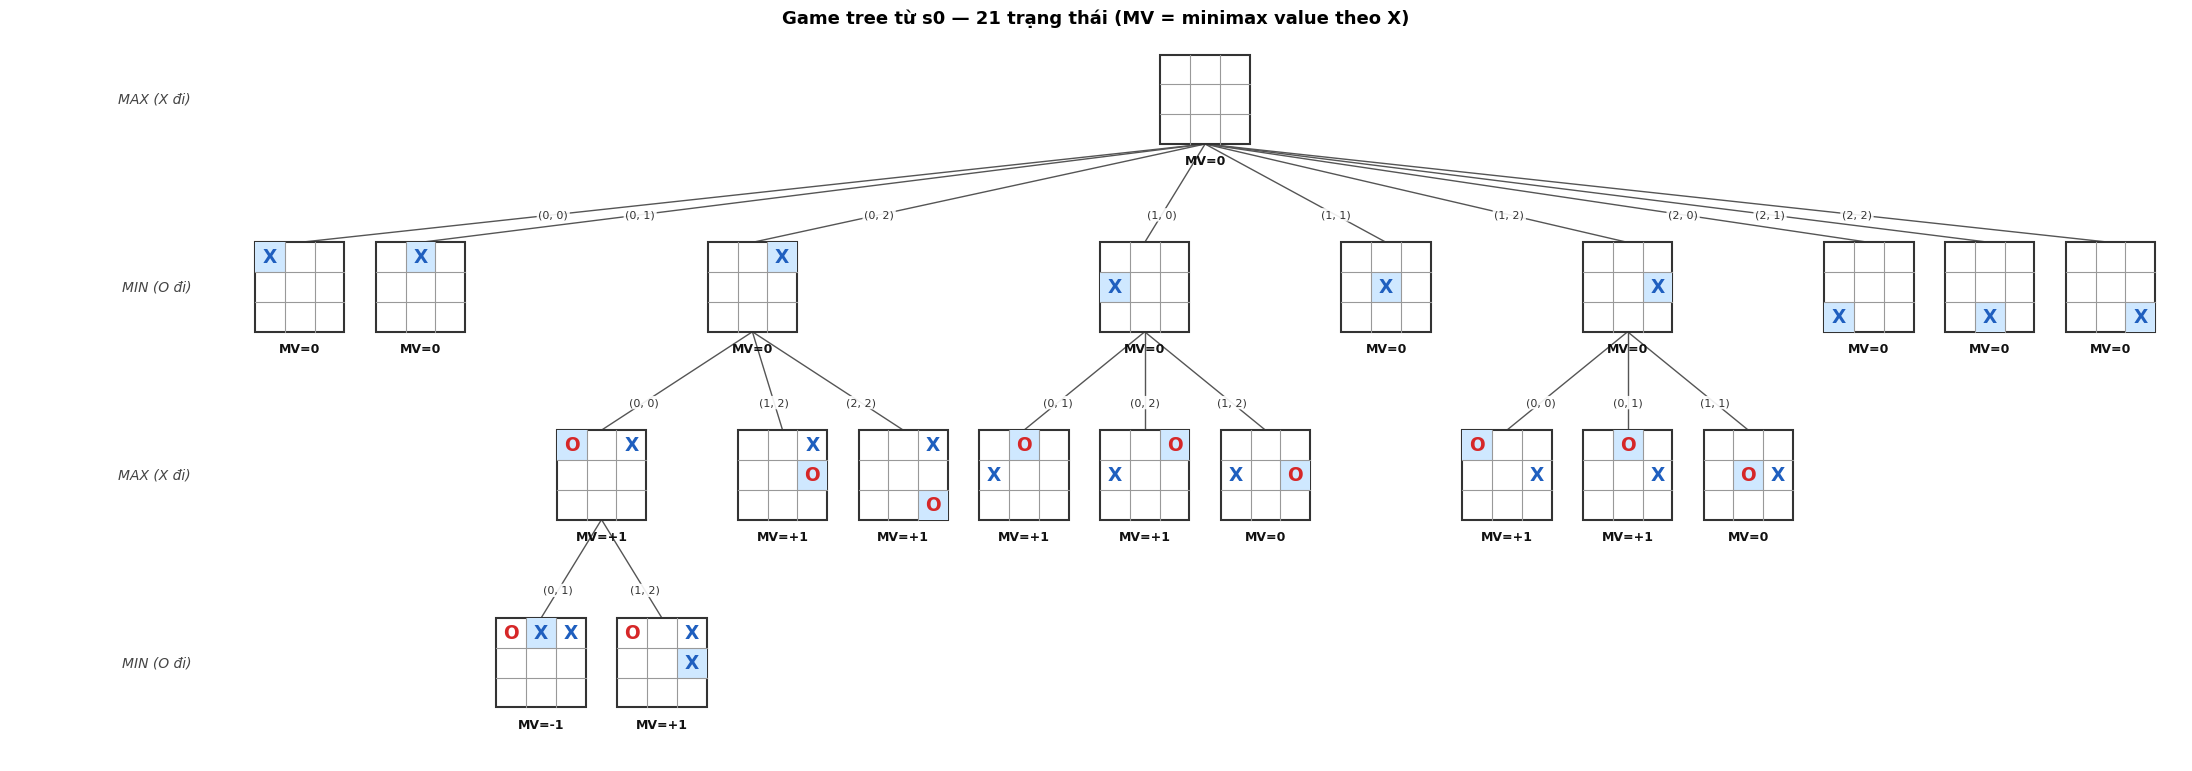

In [23]:
for nd in tree1.all_nodes():
    v = exact_value(game, nd.state, X)
    nd.label = f'MV={v:+g}' if v else 'MV=0'
draw_tree(game, tree1, f'Game tree từ s0 — {n_nodes} trạng thái (MV = minimax value theo X)',
          level_names=['MAX (X đi)', 'MIN (O đi)'])
plt.show()

**Đọc cây:**
- **Gốc** (bàn trống) có **MV = 0**: nếu cả hai chơi hoàn hảo thì Tic-Tac-Toe 3×3 **luôn hòa** — đúng như slide tr. 16 (MV của gốc là 0).
- **Mức 1:** cả 9 nước đầu của X đều có MV = 0 → nước đầu nào cũng không thua (nếu sau đó chơi đúng).
- **Mức 2:** nhiều nước trả lời của O có **MV = +1** → đó là **nước sai** của O, X có cách thắng chắc (ví dụ X đánh góc (0,2) mà O **không** đánh vào ô giữa thì O thua). Nút MV = 0 là nước trả lời đúng.
- **Mức 3:** từ một thế X đang thắng (+1), nếu X đi sai thì MV có thể tụt xuống **−1** (O lại thắng) → mỗi nước đều quan trọng.

### 5.10 Kiểm tra tính đúng đắn
Các giải thuật exact phải **cho cùng minimax value** (Alpha-Beta và các cải tiến tối ưu như Minimax). Ta thử trên **các thế cờ ngẫu nhiên** và cho AI đấu thử.

In [24]:
random.seed(1)
checked = mismatch = 0
for _ in range(300):
    s = game.initial_state()
    for _ in range(random.randint(1, 6)):                  # đi ngẫu nhiên 1-6 nước
        if game.terminal(s):
            break
        s = game.result(s, random.choice(game.actions(s)))
    if game.terminal(s):
        continue
    rs = [solve(game, s, a) for a in ['minimax', 'alphabeta', 'alphabeta_mo', 'alphabeta_tt']]
    checked += 1
    if len({r.value for r in rs}) != 1:
        mismatch += 1
    for res in rs[1:]:      # giá trị "chính xác" ở gốc phải trùng Minimax; giá trị "cận" phải >= giá trị thật
        for a, (v, exact) in res.move_values.items():
            true_v = rs[0].move_values[a][0]
            if (exact and v != true_v) or (not exact and not true_v <= v):
                mismatch += 1
print(f'Đã kiểm tra {checked} thế cờ: {mismatch} lỗi -> 4 giải thuật exact cho CÙNG minimax value ✔')


def play_game(game, agent_first, agent_second):
    """Cho 2 agent đấu 1 ván. agent(game, state) -> nước đi. Trả về 'X', 'O' hoặc 'Hòa'."""
    s = game.initial_state()
    agents = {game.first: agent_first, other(game.first): agent_second}
    while not game.terminal(s):
        s = game.result(s, agents[s.to_move](game, s))
    return game.winner(s.board) or 'Hòa'

optimal_agent = lambda g, s: solve(g, s, 'alphabeta_tt').move
random_agent = lambda g, s: random.choice(g.empty_cells(s.board))

print('AI tối ưu (X) vs AI tối ưu (O):', play_game(game, optimal_agent, optimal_agent))
random.seed(0)
res_x = [play_game(game, optimal_agent, random_agent) for _ in range(100)]
res_o = [play_game(game, random_agent, optimal_agent) for _ in range(100)]
print(f'AI (X, đi trước) vs Ngẫu nhiên: thắng {res_x.count(X)}, hòa {res_x.count("Hòa")}, thua {res_x.count(O)}')
print(f'AI (O, đi sau)  vs Ngẫu nhiên: thắng {res_o.count(O)}, hòa {res_o.count("Hòa")}, thua {res_o.count(X)}')

Đã kiểm tra 289 thế cờ: 0 lỗi -> 4 giải thuật exact cho CÙNG minimax value ✔
AI tối ưu (X) vs AI tối ưu (O): Hòa


AI (X, đi trước) vs Ngẫu nhiên: thắng 96, hòa 4, thua 0
AI (O, đi sau)  vs Ngẫu nhiên: thắng 86, hòa 14, thua 0


**Kết luận kiểm tra:** 4 giải thuật exact cho **cùng giá trị** trên mọi thế cờ; hai AI tối ưu đấu nhau luôn **hòa**; AI **không thua ván nào** trước đối thủ ngẫu nhiên ⇒ cài đặt đúng và **tối ưu**.

---
### 5.11 So sánh các giải thuật

#### (a) So sánh lý thuyết
*(b = hệ số phân nhánh, m = độ sâu tối đa, d = độ sâu cut-off, n = beam, N = số playout, |S| = số trạng thái khác nhau)*

| Giải thuật | Tính đầy đủ¹ | Tính tối ưu | Thời gian | Bộ nhớ |
|---|---|---|---|---|
| AND-OR Search | Có (cây hữu hạn, không vòng lặp) | Có — tìm được kế hoạch thắng chắc nếu tồn tại | O(bᵐ) trường hợp xấu | O(bm) + kích thước kế hoạch |
| Minimax Search | Có | **Có** (đối thủ tối ưu) | O(bᵐ) (slide tr. 19) | O(bm) |
| Alpha-Beta Pruning | Có | **Có** (cùng MV với Minimax) | Tốt nhất O(b^(m/2)) | O(bm) |
| Alpha-Beta + Move Ordering | Có | **Có** | gần O(b^(m/2)) nếu thứ tự tốt | O(bm) |
| + TT + Đối xứng *(mở rộng)* | Có | **Có** | ≤ O(\|S\|) | O(\|S\|) cho bảng TT |
| Heuristic Alpha-Beta (cut-off d) | Có (luôn trả về nước đi) | **Không đảm bảo** (phụ thuộc d, Eval) | O(b^d); beam: O(n^d) | O(bd) |
| Pure Monte Carlo | Có (*anytime*: dừng lúc nào cũng có nước) | **Không đảm bảo** với N hữu hạn; hội tụ khi N → ∞ (slide tr. 38) | O(N·m) | O(b) |
| MCTS (UCB1) | Có (*anytime*) | **Không đảm bảo** với N hữu hạn; hội tụ về Minimax khi N → ∞ | O(N·m) | O(N) cho cây |

¹ *Đề bài ghi "tính mở" — nhóm hiểu là **tính đầy đủ/hoàn chỉnh** (completeness): thuật toán có chắc chắn kết thúc và trả về lời giải hay không.*

#### (b) Thí nghiệm E1 — Bàn 3×3 trống (tình huống khó nhất)
Mỗi giải thuật chạy 2 lần: một lần đo **thời gian**, một lần đo **bộ nhớ đỉnh** (đo bộ nhớ làm chương trình chậm đi). Cột **"Nước tối ưu?"** kiểm tra MV *thật* của nước được chọn có bằng giá trị tối ưu không. Monte Carlo dùng `seed=0` để tái lập.

In [25]:
def compare(game, state, configs):
    """Chạy nhiều cấu hình giải thuật trên cùng 1 trạng thái, trả về bảng so sánh."""
    player = state.to_move
    optimal_v = solve(game, state, 'alphabeta_tt').value if game.n == 3 else None
    rows = []
    for cfg in configs:
        try:
            r = solve(game, state, **cfg)                                       # lần 1: đo thời gian
            mem = solve(game, state, measure_memory=True, **cfg).stats.peak_kb  # lần 2: đo bộ nhớ
        except SearchLimitExceeded:
            rows.append({'Giải thuật': ALGORITHMS[cfg['algo']], 'Nước chọn': '—', 'Giá trị': '—',
                         'Số nút duyệt': f'> {cfg["max_nodes"]:,} (dừng)', 'Cắt tỉa': '—', 'TT / cây MCTS': '—',
                         'Độ sâu max': '—', 'Thời gian (ms)': '—', 'Bộ nhớ đỉnh (KB)': '—',
                         'Nước tối ưu?': 'KHÔNG HOÀN THÀNH'})
            continue
        ok = '—'
        if optimal_v is not None:
            ok = 'Có' if exact_value(game, game.result(state, r.move), player) == optimal_v else 'KHÔNG'
        rows.append({'Giải thuật': r.algorithm, 'Nước chọn': game.rc(r.move),
                     'Giá trị': round(r.value, 4), 'Số nút duyệt': r.stats.nodes, 'Cắt tỉa': r.stats.cutoffs,
                     'TT / cây MCTS': r.stats.tt_size, 'Độ sâu max': r.stats.max_depth,
                     'Thời gian (ms)': round(r.stats.time_ms, 1), 'Bộ nhớ đỉnh (KB)': round(mem, 1),
                     'Nước tối ưu?': ok})
    return pd.DataFrame(rows)


configs_3x3 = [dict(algo='minimax'), dict(algo='alphabeta'), dict(algo='alphabeta_mo'),
               dict(algo='alphabeta_tt', use_symmetry=False), dict(algo='alphabeta_tt'),
               dict(algo='heuristic_ab', depth_limit=2, heuristic='h1'), dict(algo='heuristic_ab', depth_limit=2, heuristic='h2'),
               dict(algo='heuristic_ab', depth_limit=4, heuristic='h1'), dict(algo='heuristic_ab', depth_limit=4, heuristic='h2'),
               dict(algo='heuristic_ab', depth_limit=4, heuristic='h2', beam=3),
               dict(algo='pure_mc', n_playouts=1000, seed=0), dict(algo='mcts', n_playouts=1000, seed=0)]
df_e1 = compare(game, game.initial_state(), configs_3x3)
display(df_e1)

,Giải thuật,Nước chọn,Giá trị,Số nút duyệt,Cắt tỉa,TT / cây MCTS,Độ sâu max,Thời gian (ms),Bộ nhớ đỉnh (KB),Nước tối ưu?
0,Minimax Search,"(0, 0)",0.0000,549946,0,0,9,1034.5,2.9,Có
1,Alpha-Beta Pruning,"(0, 0)",0.0000,18297,8180,0,9,37.6,2.8,Có
2,Alpha-Beta + Move Ordering,"(1, 1)",0.0000,7275,3090,0,9,14.6,2.9,Có
3,Alpha-Beta + Move Ordering + TT (không đối xứng),"(1, 1)",0.0000,1981,656,889,9,4.3,175.5,Có
4,Alpha-Beta + Move Ordering + TT + Đối xứng,"(1, 1)",0.0000,466,148,204,9,2.3,43.1,Có
5,"Heuristic Alpha-Beta Tree Search (d=2, h1)","(1, 1)",0.1111,26,8,0,2,0.1,1.7,Có
6,"Heuristic Alpha-Beta Tree Search (d=2, h2)","(1, 1)",0.0123,26,8,0,2,0.1,1.7,Có
7,"Heuristic Alpha-Beta Tree Search (d=4, h1)","(1, 1)",0.1111,206,77,0,4,0.6,2.2,Có
8,"Heuristic Alpha-Beta Tree Search (d=4, h2)","(1, 1)",0.0000,303,86,0,4,1.0,2.5,Có
9,"Heuristic Alpha-Beta Tree Search (d=4, h2, beam=3)","(1, 1)",-0.0988,49,13,0,4,0.8,1.9,Có


**Nhận xét E1:**
- **Minimax** duyệt **549.946 nút**; **Alpha-Beta** chỉ **18.297**; thêm **Move ordering** còn **7.275** — đúng bảng slide tr. 27, cùng giá trị **0**.
- **Bảng chuyển vị** giảm xuống khoảng 1–2 nghìn nút; thêm **đối xứng** chỉ còn **vài trăm nút** — nhanh hơn Minimax **hàng trăm lần**, đổi lại tốn bộ nhớ cho bảng TT.
- **Heuristic Alpha-Beta** duyệt rất ít nút; giá trị chỉ là **HMV ước lượng** (số lẻ trong (−1, 1)). **Beam = 3** (forward pruning) giảm số nút thêm nữa.
- **Monte Carlo**: số "nút" ở đây là số trạng thái được mô phỏng trong các playout; giá trị là **utility trung bình** của playout. Cả hai đều chọn được nước an toàn ở bàn trống.
- *Bộ nhớ đỉnh* của Minimax/Alpha-Beta nhỏ vì là DFS (slide tr. 19: O(bm)); TT và cây MCTS tốn nhiều hơn.

#### (c) Thí nghiệm E2 — Số nút và thời gian theo số ô trống
Chọn ngẫu nhiên các thế cờ 3×3 có từ 4 đến 9 ô trống, tính trung bình cho 4 giải thuật exact. Trục tung dùng **thang logarit**.

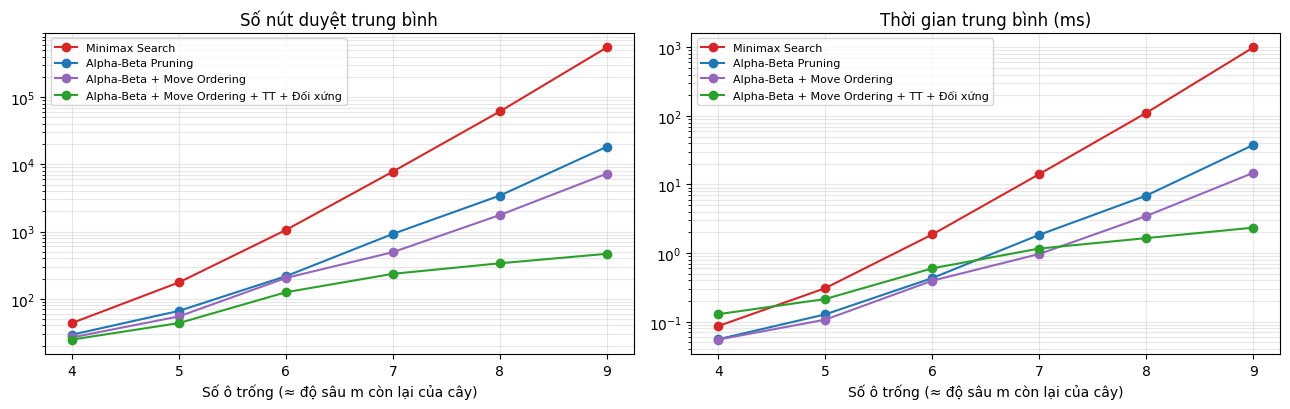

Giải thuật,Alpha-Beta + Move Ordering,Alpha-Beta + Move Ordering + TT + Đối xứng,Alpha-Beta Pruning,Minimax Search
Số ô trống,,,,
4,26,25,29,43
5,54,43,66,175
6,204,125,216,1053
7,493,235,922,7802
8,1761,337,3429,61280
9,7275,466,18297,549946


In [26]:
random.seed(3)
algos = ['minimax', 'alphabeta', 'alphabeta_mo', 'alphabeta_tt']
records = []
for empties in range(4, 10):
    positions, tries = set(), 0
    while len(positions) < 8 and tries < 500:                 # tối đa 8 thế cờ khác nhau cho mỗi mức
        tries += 1
        s = game.initial_state()
        for _ in range(9 - empties):
            if game.terminal(s):
                break
            s = game.result(s, random.choice(game.actions(s)))
        if not game.terminal(s) and s.board.count(EMPTY) == empties:
            positions.add(s)
    for algo in algos:
        rs = [solve(game, s, algo) for s in positions]
        records.append({'Số ô trống': empties, 'Giải thuật': ALGORITHMS[algo], 'Số thế cờ': len(rs),
                        'Số nút TB': sum(r.stats.nodes for r in rs) / len(rs),
                        'Thời gian TB (ms)': sum(r.stats.time_ms for r in rs) / len(rs)})
df_e2 = pd.DataFrame(records)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for algo, color in zip(algos, ['#d62728', '#1f77b4', '#9467bd', '#2ca02c']):
    part = df_e2[df_e2['Giải thuật'] == ALGORITHMS[algo]]
    axes[0].plot(part['Số ô trống'], part['Số nút TB'], 'o-', color=color, label=ALGORITHMS[algo])
    axes[1].plot(part['Số ô trống'], part['Thời gian TB (ms)'], 'o-', color=color, label=ALGORITHMS[algo])
for ax, t in zip(axes, ['Số nút duyệt trung bình', 'Thời gian trung bình (ms)']):
    ax.set_yscale('log'); ax.set_xlabel('Số ô trống (≈ độ sâu m còn lại của cây)'); ax.set_title(t)
    ax.grid(alpha=.3, which='both'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

display(df_e2.pivot(index='Số ô trống', columns='Giải thuật', values='Số nút TB').round(0).astype(int))

**Nhận xét E2:** đường **Minimax** gần như **thẳng trên thang log** → số nút tăng **theo hàm mũ** O(bᵐ) khi số ô trống (m) tăng. **Alpha-Beta** dốc ít hơn; **Move ordering** dốc ít hơn nữa (gần O(b^(m/2))); **TT + đối xứng** gần như nằm ngang vì bị chặn bởi số trạng thái khác nhau. Khoảng cách giữa các đường **càng lớn khi bài toán càng lớn** ⇒ đúng nhận định của slide tr. 19: *"We need to reduce the time complexity! → Game tree pruning"*.

#### (d) Thí nghiệm E3 — Bàn 4×4 (k = 4): cây trò chơi quá lớn
Minimax được đặt **giới hạn 2.000.000 nút**. Thử trên một thế cờ 4×4 còn **10 ô trống**, và trên **bàn 4×4 trống** (16 ô) với các phương pháp heuristic.

In [27]:
game4 = TicTacToe(n=4, k=4)
random.seed(5)
s4 = game4.initial_state()
for _ in range(6):                                            # đi ngẫu nhiên 6 nước -> còn 10 ô trống
    s4 = game4.result(s4, random.choice(game4.empty_cells(s4.board)))
print(f'Thế cờ 4x4 (k=4), đến lượt {s4.to_move}, còn {s4.board.count(EMPTY)} ô trống:')
print(game4.pretty(s4.board))

configs_4x4 = [dict(algo='minimax', max_nodes=2_000_000), dict(algo='alphabeta'), dict(algo='alphabeta_mo'),
               dict(algo='alphabeta_tt'),
               dict(algo='heuristic_ab', depth_limit=2, heuristic='h1'), dict(algo='heuristic_ab', depth_limit=2, heuristic='h2'),
               dict(algo='heuristic_ab', depth_limit=4, heuristic='h1'), dict(algo='heuristic_ab', depth_limit=4, heuristic='h2'),
               dict(algo='mcts', n_playouts=2000, seed=0)]
display(compare(game4, s4, configs_4x4).drop(columns=['Nước tối ưu?']))

print('\nBàn 4x4 TRỐNG (16 ô) — chỉ các phương pháp heuristic khả thi:')
display(compare(game4, game4.initial_state(),
                [dict(algo='heuristic_ab', depth_limit=d, heuristic=h) for d in (2, 4) for h in ('h1', 'h2')] +
                [dict(algo='heuristic_ab', depth_limit=4, heuristic='h2', beam=4),
                 dict(algo='pure_mc', n_playouts=2000, seed=0), dict(algo='mcts', n_playouts=2000, seed=0)])
        .drop(columns=['Nước tối ưu?']))

Thế cờ 4x4 (k=4), đến lượt X, còn 10 ô trống:
. . . .
. X . .
X . . .
O O X O


,Giải thuật,Nước chọn,Giá trị,Số nút duyệt,Cắt tỉa,TT / cây MCTS,Độ sâu max,Thời gian (ms),Bộ nhớ đỉnh (KB)
0,Minimax Search,—,—,"> 2,000,000 (dừng)",—,—,—,—,—
1,Alpha-Beta Pruning,"(0, 0)",0,77723,37311,0,10,190.8,3.2
2,Alpha-Beta + Move Ordering,"(0, 0)",0,38850,18324,0,10,92.2,3.3
3,Alpha-Beta + Move Ordering + TT + Đối xứng,"(0, 0)",0,5218,1614,2258,10,34.4,469.2
4,"Heuristic Alpha-Beta Tree Search (d=2, h1)","(0, 3)",0.1818,37,8,0,2,0.1,1.9
5,"Heuristic Alpha-Beta Tree Search (d=2, h2)","(0, 3)",0.002,50,8,0,2,0.3,1.9
6,"Heuristic Alpha-Beta Tree Search (d=4, h1)","(0, 3)",0.0909,362,102,0,4,1.3,2.4
7,"Heuristic Alpha-Beta Tree Search (d=4, h2)","(0, 3)",0.001,737,169,0,4,3.1,2.4
8,Monte Carlo Tree Search (UCB1) (N=2000),"(1, 2)",0.2188,13387,0,2001,10,47.3,829.3



Bàn 4x4 TRỐNG (16 ô) — chỉ các phương pháp heuristic khả thi:


,Giải thuật,Nước chọn,Giá trị,Số nút duyệt,Cắt tỉa,TT / cây MCTS,Độ sâu max,Thời gian (ms),Bộ nhớ đỉnh (KB)
0,"Heuristic Alpha-Beta Tree Search (d=2, h1)","(0, 0)",0.000,47,15,0,2,0.1,2.1
1,"Heuristic Alpha-Beta Tree Search (d=2, h2)","(0, 0)",0.000,47,15,0,2,0.2,2.1
2,"Heuristic Alpha-Beta Tree Search (d=4, h1)","(0, 0)",0.000,837,256,0,4,2.8,3.3
3,"Heuristic Alpha-Beta Tree Search (d=4, h2)","(0, 0)",-0.008,1941,415,0,4,8.3,2.9
4,"Heuristic Alpha-Beta Tree Search (d=4, h2, beam=4)","(0, 0)",-0.008,107,28,0,4,3.3,3.2
5,Pure Monte Carlo Search (N=2000),"(0, 0)",0.136,29346,0,0,16,63.9,8.4
6,Monte Carlo Tree Search (UCB1) (N=2000),"(0, 3)",0.187,25200,0,2001,16,100.9,957.3


**Nhận xét E3:**
- Chỉ với **10 ô trống**, **Minimax vượt 2 triệu nút mà chưa xong**; Alpha-Beta và các cải tiến giải xong và cho **cùng một giá trị**; move ordering và TT nhanh hơn nhiều lần.
- Với **bàn 4×4 trống**, cây có tới 16! ≈ 2·10¹³ đường đi → chỉ các phương pháp **heuristic** (cut-off + Eval, forward pruning, Monte Carlo) trả lời được trong thời gian ngắn. Đúng ý slide tr. 35: *cut-off thấp thì nhanh nhưng ước lượng kém; cut-off cao chậm hơn nhưng tốt hơn*; beam giảm mạnh số nút.

#### (e) Thí nghiệm E4 — Chất lượng nước đi của các phương pháp heuristic
Cho từng agent chơi bàn 3×3:
- với **AI tối ưu** (Alpha-Beta + TT): đi trước và đi sau → nếu **thua** thì nước đi **không tối ưu**;
- với **người chơi ngẫu nhiên**: 40 ván (20 ván đi trước + 20 ván đi sau).

In [28]:
def make_agent(**cfg):
    return lambda g, s: solve(g, s, **cfg).move

configs_e4 = ([dict(algo='heuristic_ab', depth_limit=d, heuristic=h) for d in (1, 2, 3) for h in ('h1', 'h2')] +
              [dict(algo='heuristic_ab', depth_limit=3, heuristic='h2', beam=2)] +
              [dict(algo=a, n_playouts=n) for a in ('pure_mc', 'mcts') for n in (30, 300)])
rows = []
random.seed(11)
for cfg in configs_e4:
    ag = make_agent(**cfg)
    name = solve(game, game.initial_state(), **cfg).algorithm
    as_x = [play_game(game, ag, optimal_agent) for _ in range(3 if cfg['algo'] in MC_ALGOS else 1)]
    as_o = [play_game(game, optimal_agent, ag) for _ in range(3 if cfg['algo'] in MC_ALGOS else 1)]
    w = dr = l = 0
    for _ in range(20):
        r = play_game(game, ag, random_agent); w += r == X; dr += r == 'Hòa'; l += r == O
        r = play_game(game, random_agent, ag); w += r == O; dr += r == 'Hòa'; l += r == X
    rows.append({'Agent': name,
                 'vs Tối ưu: số ván THUA': f'{as_x.count(O) + as_o.count(X)} / {len(as_x) + len(as_o)}',
                 'vs Ngẫu nhiên: Thắng': w, 'Hòa': dr, 'Thua': l})
display(pd.DataFrame(rows))

,Agent,vs Tối ưu: số ván THUA,vs Ngẫu nhiên: Thắng,Hòa,Thua
0,"Heuristic Alpha-Beta Tree Search (d=1, h1)",1 / 2,34,2,4
1,"Heuristic Alpha-Beta Tree Search (d=1, h2)",0 / 2,39,0,1
2,"Heuristic Alpha-Beta Tree Search (d=2, h1)",0 / 2,31,7,2
3,"Heuristic Alpha-Beta Tree Search (d=2, h2)",0 / 2,37,3,0
4,"Heuristic Alpha-Beta Tree Search (d=3, h1)",0 / 2,38,2,0
5,"Heuristic Alpha-Beta Tree Search (d=3, h2)",0 / 2,37,3,0
6,"Heuristic Alpha-Beta Tree Search (d=3, h2, beam=2)",0 / 2,38,2,0
7,Pure Monte Carlo Search (N=30),3 / 6,35,1,4
8,Pure Monte Carlo Search (N=300),1 / 6,38,2,0
9,Monte Carlo Tree Search (UCB1) (N=30),1 / 6,33,6,1


**Nhận xét E4** *(Monte Carlo có yếu tố ngẫu nhiên nên số liệu dao động nhẹ giữa các lần chạy)*:
- **h1 với d = 1** thua AI tối ưu: tìm quá nông + heuristic "thô" (không phân biệt đường 1 quân và 2 quân) → **không tối ưu**; **h2** cùng độ sâu tốt hơn vì nhận ra mối đe dọa. Tăng d thì chất lượng tăng — đúng slide tr. 35.
- **Monte Carlo với ít playout (N = 30)** dễ thua vì ước lượng nhiễu; tăng N lên 300 thì gần như không thua — đúng *"converges to optimal play as N increases"* (slide tr. 38). MCTS dùng UCB1 nên với cùng N thường tốt hơn Pure MC.
- Trong khi đó các giải thuật exact **không bao giờ thua** (mục 5.10).

#### (f) Tổng kết so sánh
| | Minimax | Alpha-Beta | + Move Ordering | + TT + Đối xứng | Heuristic AB | Pure MC / MCTS |
|---|---|---|---|---|---|---|
| Đầy đủ | ✔ | ✔ | ✔ | ✔ | ✔ | ✔ (anytime) |
| Tối ưu | ✔ | ✔ | ✔ | ✔ | ✘ (phụ thuộc d, Eval) | ✘ (hội tụ khi N → ∞) |
| Số nút (3×3 trống) | 549.946 | 18.297 | 7.275 | vài trăm | vài chục – vài trăm | tùy N |
| Bộ nhớ | O(bm) nhỏ | O(bm) nhỏ | O(bm) nhỏ | lớn hơn (TT) | O(bd) nhỏ | O(N) (cây MCTS) |
| Bàn 4×4, 5×5 | ✘ | chỉ gần cuối ván | chỉ gần cuối ván | chỉ gần cuối ván | ✔ | ✔ |

⇒ **Lựa chọn cho giao diện:** mặc định dùng **Alpha-Beta + Move Ordering + TT + Đối xứng** cho bàn 3×3 (tối ưu và nhanh nhất), **Heuristic Alpha-Beta với h2** cho bàn 4×4, 5×5.

---
# PHẦN 6 — GIAO DIỆN ĐỒ HỌA: CHƠI TIC-TAC-TOE

Giao diện xây bằng **ipywidgets** (chạy ngay trong notebook: Jupyter, JupyterLab, VS Code, Colab). Mục 6.4 có thêm bản **cửa sổ riêng (tkinter)**.

### 6.1 Ba chế độ chơi
| Chế độ | Mô tả |
|---|---|
| 🧑 **Người vs 🤖 Máy** | Bạn đấu với AI. Chọn **độ khó** hoặc **thuật toán** cụ thể cho máy. Có nút 💡 Gợi ý. |
| 🧑 **Người vs 🧑 Người** | Hai người thay phiên đánh trên cùng màn hình (không có AI). Dùng để chơi với bạn bè. |
| 🤖 **Máy vs 🤖 Máy** | Xem hai AI tự đấu. Chọn độ khó / thuật toán **riêng cho quân X và quân O**; bấm **▶ Đi 1 nước**, **⏯ Tự chạy** (có chỉnh tốc độ) hoặc **⏭ Chạy hết ván**. |

### 6.2 Độ khó của AI
Thay vì phải hiểu các tham số kỹ thuật, bạn có thể chọn nhanh một trong ba mức (áp dụng cho bàn mọi kích thước):

| Mức | Cách AI chơi | Ghi chú |
|---|---|---|
| 🟢 **Dễ** | Tìm nông (Heuristic d=1) và **50% số nước đi ngẫu nhiên** | Người mới dễ thắng |
| 🟡 **Vừa** | Heuristic Alpha-Beta d=3 (h2), **~18% nước đi ngẫu nhiên** | Cần suy nghĩ mới thắng |
| 🔴 **Khó** | **Alpha-Beta + TT tối ưu** (bàn 3×3) — *không bao giờ thua*; bàn lớn dùng Heuristic d=4 | Giỏi nhất, hòa là tốt |

> 💡 Mức Dễ/Vừa cố tình cho AI **đi ngẫu nhiên** một tỉ lệ nước để người chơi có cơ hội thắng — đây là cách làm "độ khó" phổ biến trong game. Chọn **"⚙ …"** trong danh sách để dùng thẳng từng thuật toán ở Phần 5 (khi đó các tham số nâng cao bên dưới có tác dụng).

### 6.3 Trực quan hóa & tiện ích
- Sau mỗi nước của máy, **các ô trống hiện con số** = giá trị AI tính cho nước đi vào ô đó (theo góc nhìn của AI): 🟩 dương = AI thắng · ⬜ 0 = hòa · 🟥 âm = AI thua · **"≤ v"** = nhánh bị Alpha-Beta cắt tỉa · **số lẻ** = ước lượng heuristic / trung bình Monte Carlo. Bật/tắt bằng ô *"Hiện điểm AI tính cho từng ô"*.
- Ô máy vừa chọn có **viền xanh lá**; đường thắng **nhấp nháy**. Rê chuột lên ô để xem giải thích.
- **↩️ Hoàn tác**, **🌳 Xem cây tìm kiếm** (lượt suy nghĩ gần nhất), bảng thống kê số nút / cắt tỉa / thời gian, và tỉ số nhiều ván.
- Khung **⚙️ Tùy chỉnh nâng cao** (gấp lại được): heuristic, độ sâu d, beam, số playout N, hằng số C, giới hạn số nút, Utility thắng nhanh — chỉ cần khi chọn thuật toán cụ thể.

In [29]:
import ipywidgets as W
import threading
from IPython.display import clear_output

# ---- CSS làm đẹp giao diện (ghép từ các chuỗi để tránh ký tự đặc biệt) ----
TTT_CSS = (
'<style>'
'.ttt-header{background:linear-gradient(135deg,#6366f1,#8b5cf6);color:#fff;'
'padding:12px 18px;border-radius:16px;margin-bottom:10px;font-weight:700;font-size:18px;}'
'.ttt-card{background:#ffffff;border:1px solid #e5e7eb;border-radius:16px;'
'padding:14px;box-shadow:0 4px 14px rgba(0,0,0,.06);}'
'.ttt-board-wrap{background:linear-gradient(135deg,#eef2ff,#faf5ff);'
'border-radius:18px;padding:14px;display:inline-block;}'
'.ttt-cell{border:none !important;border-radius:12px !important;font-weight:800 !important;'
'box-shadow:0 2px 5px rgba(0,0,0,.12);transition:transform .07s ease,box-shadow .12s ease;}'
'.ttt-cell:hover{transform:translateY(-2px);box-shadow:0 6px 14px rgba(0,0,0,.22);}'
'.ttt-chosen{outline:3px solid #16a34a !important;outline-offset:-3px;}'
'.ttt-win{animation:tttpulse 1s ease-in-out infinite;}'
'@keyframes tttpulse{0%,100%{transform:scale(1);}50%{transform:scale(1.08);}}'
'.ttt-chip{display:inline-block;padding:2px 12px;border-radius:999px;font-weight:700;}'
'</style>'
)


def fmt_value(v, exact=True):
    # Định dạng giá trị ngắn gọn để hiện trên ô
    p = "" if exact else "≤"
    if v == 0:
        return p + "0"
    if float(v).is_integer():
        return p + f"{v:+g}"
    return p + f"{v:+.2f}"


def explain_value(v, exact, empties_before, who, game, approx=False):
    # Giải thích bằng lời giá trị một nước đi (hiện khi rê chuột)
    if approx:
        s = "có lợi" if v > 0 else "bất lợi" if v < 0 else "cân bằng"
        return f"Ước lượng = {v:+.3f} -> {s} cho {who}"
    if not exact:
        return f"Nhánh bị cắt tỉa: giá trị thật <= {fmt_value(v)} (không tốt hơn nước tốt nhất)"
    if v > 0:
        more = f" — kết thúc sau {empties_before - (v - 1):g} nước nữa" if game.fast_win else ""
        return f"{who} THẮNG nếu chơi đúng{more}"
    if v < 0:
        return f"{who} THUA nếu đối thủ chơi hoàn hảo"
    return "HÒA nếu hai bên chơi tối ưu"


def value_color(v, exact, approx=False):
    if not exact:
        return "#f3f4f6"
    if approx:
        return "#dcfce7" if v > 0 else "#fee2e2" if v < 0 else "#e5e7eb"
    return "#86efac" if v > 0 else "#fca5a5" if v < 0 else "#e5e7eb"


def difficulty_config(n, level):
    # Quy đổi mức độ khó -> cấu hình thuật toán cho AI (dùng chung cho ipywidgets và tkinter)
    if level == "easy":
        return dict(algo="alphabeta_tt" if n == 3 else "heuristic_ab", depth_limit=1, heuristic="h1",
                    beam=0, n_playouts=200, c=1.41, blunder=0.5, label="🟢 Dễ")
    if level == "medium":
        return dict(algo="heuristic_ab", depth_limit=3 if n == 3 else 2, heuristic="h2",
                    beam=0, n_playouts=800, c=1.41, blunder=0.18, label="🟡 Vừa")
    return dict(algo="alphabeta_tt" if n == 3 else "heuristic_ab", depth_limit=4, heuristic="h2",
                beam=0, n_playouts=3000, c=1.41, blunder=0.0, label="🔴 Khó")

print("✅ Đã nạp tiện ích giao diện + mức độ khó")

✅ Đã nạp tiện ích giao diện + mức độ khó


In [30]:
MODES = [("🧑 Người vs 🤖 Máy", "pvc"), ("🧑 Người vs 🧑 Người", "pvp"), ("🤖 Máy vs 🤖 Máy", "cvc")]
# Danh sách lựa chọn đối thủ: 3 mức khó + 7 thuật toán cụ thể (tiền tố ⚙)
OPP_OPTIONS = [("🟢 Dễ", "easy"), ("🟡 Vừa", "medium"), ("🔴 Khó (tối ưu)", "hard")] + \
              [("⚙ " + v, k) for k, v in ALGORITHMS.items()]


class TicTacToeApp:
    # Giao diện Tic-Tac-Toe: 3 chế độ chơi, chọn độ khó, trực quan hóa tìm kiếm

    def __init__(self):
        st = {"description_width": "130px"}
        L = W.Layout(width="330px")
        self.w_mode = W.ToggleButtons(options=MODES, value="pvc", style={"button_width": "auto"})
        self.w_size = W.Dropdown(options=[("3 × 3", 3), ("4 × 4", 4), ("5 × 5", 5)], value=3,
                                 description="Kích thước:", style=st, layout=L)
        self.w_k = W.Dropdown(options=[3], value=3, description="Số quân thắng k:", style=st, layout=L)
        self.w_opp = W.Dropdown(options=OPP_OPTIONS, value="hard", description="Đối thủ AI:", style=st, layout=L)
        self.w_ai_x = W.Dropdown(options=OPP_OPTIONS, value="hard", description="AI quân X:", style=st, layout=L)
        self.w_ai_o = W.Dropdown(options=OPP_OPTIONS, value="medium", description="AI quân O:", style=st, layout=L)
        self.w_human = W.ToggleButtons(options=["X", "O"], value="X", description="Bạn cầm:", style=st)
        self.w_first = W.ToggleButtons(options=["X", "O"], value="X", description="Quân đi trước:", style=st)
        self.w_speed = W.FloatSlider(value=0.6, min=0.1, max=2.0, step=0.1, description="Tốc độ (giây):",
                                     style=st, layout=L)
        # --- nâng cao ---
        self.w_heur = W.Dropdown(options=[("h1 – Số đường còn mở", "h1"), ("h2 – Trọng số đe dọa", "h2")],
                                 value="h2", description="Heuristic:", style=st, layout=L)
        self.w_depth = W.IntSlider(value=3, min=1, max=9, description="Độ sâu d:", style=st, layout=L)
        self.w_beam = W.IntSlider(value=0, min=0, max=9, description="Beam n:", style=st, layout=L)
        self.w_playouts = W.IntSlider(value=1000, min=50, max=10000, step=50, description="Playout N:",
                                      style=st, layout=L)
        self.w_c = W.FloatSlider(value=1.41, min=0.1, max=3.0, step=0.05, description="C (UCB1):", style=st, layout=L)
        self.w_limit = W.BoundedIntText(value=1_000_000, min=1_000, max=50_000_000, step=100_000,
                                        description="Giới hạn nút:", style=st, layout=L)
        self.w_fast = W.Checkbox(value=True, description="Ưu tiên thắng nhanh", indent=False)
        self.w_show = W.Checkbox(value=True, description="Hiện điểm AI tính cho từng ô", indent=False)
        # --- nút bấm ---
        self.b_new = W.Button(description="🔄 Ván mới", button_style="primary", layout=W.Layout(width="115px"))
        self.b_undo = W.Button(description="↩️ Hoàn tác", layout=W.Layout(width="115px"))
        self.b_hint = W.Button(description="💡 Gợi ý", button_style="info", layout=W.Layout(width="110px"))
        self.b_tree = W.Button(description="🌳 Cây tìm kiếm", button_style="success", layout=W.Layout(width="150px"))
        self.b_step = W.Button(description="▶ Đi 1 nước", layout=W.Layout(width="120px"))
        self.b_auto = W.Button(description="⏯ Tự chạy", button_style="warning", layout=W.Layout(width="110px"))
        self.b_runall = W.Button(description="⏭ Chạy hết", layout=W.Layout(width="110px"))

        self.status, self.info, self.hist, self.score = W.HTML(), W.HTML(), W.HTML(), W.HTML()
        self.legend = W.HTML(
            '<div style="font-size:12px;line-height:1.6">Số trên ô trống = giá trị AI tính: '
            '<span style="background:#86efac;padding:0 5px;border-radius:4px">+ thắng</span> '
            '<span style="background:#e5e7eb;padding:0 5px;border-radius:4px">0 hòa</span> '
            '<span style="background:#fca5a5;padding:0 5px;border-radius:4px">− thua</span> '
            '<span style="background:#f3f4f6;padding:0 5px;border-radius:4px">≤ cắt tỉa</span> '
            '<span style="background:#dcfce7;padding:0 5px;border-radius:4px">số lẻ = ước lượng</span></div>')
        self.grid = W.GridBox()
        self.tree_out = W.Output()
        self.tally = {X: 0, O: 0, "draw": 0}
        self._suspend = False
        self._auto = False
        self._last = None

        self.w_size.observe(self._on_size, names="value")
        for w in (self.w_k, self.w_human, self.w_first, self.w_fast, self.w_mode):
            w.observe(lambda ch: self.new_game(), names="value")
        self.w_show.observe(lambda ch: self.render(), names="value")
        self.b_new.on_click(lambda b: self.new_game())
        self.b_undo.on_click(lambda b: self.undo())
        self.b_hint.on_click(lambda b: self.hint())
        self.b_tree.on_click(lambda b: self.show_tree())
        self.b_step.on_click(lambda b: self.cvc_step())
        self.b_auto.on_click(lambda b: self.toggle_auto())
        self.b_runall.on_click(lambda b: self.run_all())
        self.new_game()

    @property
    def mode(self):
        return self.w_mode.value

    # ---------------- tham số ----------------
    def _on_size(self, change):
        n = self.w_size.value
        self._suspend = True
        self.w_k.options = list(range(3, n + 1))
        self.w_k.value = {3: 3, 4: 4, 5: 4}[n]
        self.w_depth.max = self.w_beam.max = n * n
        self._suspend = False
        self.new_game()

    def _adv(self):
        return dict(depth_limit=self.w_depth.value, heuristic=self.w_heur.value, beam=self.w_beam.value,
                    n_playouts=self.w_playouts.value, c=self.w_c.value)

    def _resolve(self, preset):
        # preset: 'easy'/'medium'/'hard' hoặc khóa thuật toán -> cấu hình đầy đủ
        if preset in ("easy", "medium", "hard"):
            lvl = {"easy": "easy", "medium": "medium", "hard": "hard"}[preset]
            return difficulty_config(self.w_size.value, lvl)
        cfg = dict(algo=preset, blunder=0.0, label=ALGORITHMS[preset])
        cfg.update(self._adv())
        return cfg

    def _ai_cfg(self):
        if self.mode == "pvc":
            return self._resolve(self.w_opp.value)
        return self._resolve((self.w_ai_x if self.state.to_move == X else self.w_ai_o).value)

    def _approx_of(self, cfg):
        return cfg["algo"] not in EXACT_ALGOS

    def _role(self, sym):
        if self.mode == "pvc":
            return "Bạn" if sym == self.human else "Máy"
        if self.mode == "pvp":
            return "Người 1" if sym == X else "Người 2"
        return "AI " + sym

    # ---------------- ván cờ ----------------
    def new_game(self):
        if self._suspend:
            return
        self._auto = False
        self.b_auto.description = "⏯ Tự chạy"
        n, k = self.w_size.value, self.w_k.value
        self.human = self.w_human.value
        self.ai = other(self.human)
        self.game = TicTacToe(n, k, self.w_first.value, fast_win=self.w_fast.value)
        self.state = self.game.initial_state()
        self.moves, self.overlay, self.last, self._last, self.over = [], None, None, None, False
        self.cell = {3: 90, 4: 72, 5: 60}[n]
        self.buttons, self._cls = [], []
        for i in range(n * n):
            b = W.Button(layout=W.Layout(width=f"{self.cell}px", height=f"{self.cell}px", margin="0"))
            b.add_class("ttt-cell")
            b.on_click(lambda btn, i=i: self.on_cell(i))
            self.buttons.append(b)
            self._cls.append(set())
        self.grid.children = self.buttons
        self.grid.layout = W.Layout(grid_template_columns=f"repeat({n}, {self.cell}px)", grid_gap="6px")
        self.info.value = "<i>Chưa có lượt suy nghĩ nào của AI.</i>"
        with self.tree_out:
            clear_output()
        self._sync_mode()
        self.render()
        if self.mode == "pvc" and self.state.to_move == self.ai:
            self.ai_step()

    def _sync_mode(self):
        m = self.mode
        def show(w, on):
            w.layout.display = "" if on else "none"
        show(self.w_opp, m == "pvc")
        show(self.w_human, m == "pvc")
        for w in (self.w_ai_x, self.w_ai_o, self.w_speed, self.b_step, self.b_auto, self.b_runall):
            show(w, m == "cvc")
        show(self.b_hint, m != "cvc")

    def on_cell(self, i):
        if self.over or self.mode == "cvc":
            return
        if self.mode == "pvc" and self.state.to_move != self.human:
            return
        if self.state.board[i] != EMPTY:
            return
        self.overlay = None
        self._play(i)
        if self.mode == "pvc" and not self.over and self.state.to_move == self.ai:
            self.ai_step()

    def _play(self, a):
        sym = self.state.to_move
        self.state = self.game.result(self.state, a)      # Transition Function Result(s, a)
        self.moves.append((sym, a))
        self.last = a
        if self.game.terminal(self.state):
            self.over = True
            w = self.game.winner(self.state.board)
            self.tally["draw" if w is None else w] += 1
        self.render()

    def undo(self):
        self._auto = False
        if not self.moves:
            return
        kback = 2 if (self.mode == "pvc" and len(self.moves) >= 2) else 1
        self.moves = self.moves[:-kback]
        self.state = self.game.initial_state()
        for _, a in self.moves:
            self.state = self.game.result(self.state, a)
        self.over = self.game.terminal(self.state)
        self.last = self.moves[-1][1] if self.moves else None
        self.overlay = None
        self.render()

    def _search(self, state, cfg):
        lim = self.w_limit.value
        try:
            res = solve(self.game, state, cfg["algo"], depth_limit=cfg.get("depth_limit", 3),
                        heuristic=cfg.get("heuristic", "h2"), beam=cfg.get("beam", 0),
                        n_playouts=cfg.get("n_playouts", 1000), c=cfg.get("c", 1.41), max_nodes=lim)
            note = ""
        except SearchLimitExceeded:
            res = solve(self.game, state, "heuristic_ab", 2, cfg.get("heuristic", "h2"))
            note = f"⚠️ {ALGORITHMS[cfg['algo']]} vượt {lim:,} nút -> tạm dùng Heuristic Alpha-Beta d=2."
        played = res.move
        legal = self.game.empty_cells(state.board)
        if cfg.get("blunder") and len(legal) > 1 and random.random() < cfg["blunder"]:
            played = random.choice([a for a in legal if a != res.move])
            note = (note + " ") if note else ""
            note += f"🎲 {cfg['label']}: AI đi ngẫu nhiên (không chọn nước tốt nhất)."
        return res, note, played

    def ai_step(self):
        cfg = self._ai_cfg()
        before = self.state
        self.status.value = f'<span class="ttt-chip" style="background:#ede9fe;color:#5b21b6">🤖 {self._role(before.to_move)} đang suy nghĩ…</span>'
        res, note, played = self._search(before, cfg)
        self._last = dict(state=before, res=res, cfg=cfg, played=played)
        self.overlay = (res.move_values, before.board.count(EMPTY), cfg["label"], played, self._approx_of(cfg))
        self._play(played)
        self.show_info(res, note, before, cfg, played)

    # ---- chế độ Máy vs Máy ----
    def cvc_step(self):
        if self.mode == "cvc" and not self.over:
            self.ai_step()

    def run_all(self):
        self._auto = False
        while self.mode == "cvc" and not self.over:
            self.ai_step()

    def toggle_auto(self):
        if self.mode != "cvc":
            return
        if self._auto:
            self._auto = False
            self.b_auto.description = "⏯ Tự chạy"
            return
        self._auto = True
        self.b_auto.description = "⏸ Dừng"

        def loop():
            while self._auto and not self.over:
                self.ai_step()
                time.sleep(self.w_speed.value)
            self._auto = False
            self.b_auto.description = "⏯ Tự chạy"
        threading.Thread(target=loop, daemon=True).start()

    def hint(self):
        if self.over or self.mode == "cvc" or self.state.board.count(EMPTY) == 0:
            return
        cfg = self._resolve("hard")
        res, note, _ = self._search(self.state, cfg)
        who = self._role(self.state.to_move)
        self.overlay = (res.move_values, self.state.board.count(EMPTY), who, res.move, self._approx_of(cfg))
        self.render()
        self.show_info(res, note, self.state, cfg, res.move, hint=True)

    # ---------------- hiển thị ----------------
    def show_info(self, res, note, state, cfg, played, hint=False):
        s, E, g = res.stats, state.board.count(EMPTY), self.game
        v, exact = res.move_values.get(played, (res.value, True))
        approx = self._approx_of(cfg) and not float(v).is_integer()
        who = self._role(state.to_move)
        if approx:
            pred = f'ước lượng {v:+.3f} ({"có lợi" if v > 0 else "bất lợi" if v < 0 else "cân bằng"})'
        elif v > 0:
            pred = f'<b style="color:#15803d">{who} sẽ THẮNG</b> nếu chơi đúng'
        elif v < 0:
            pred = f'<b style="color:#b91c1c">{who} sẽ THUA</b> nếu đối thủ hoàn hảo'
        else:
            pred = "<b>HÒA</b> nếu cả hai tối ưu"
        title = "💡 Gợi ý cho bạn" if hint else "🤖 Lượt suy nghĩ vừa rồi"
        rows = [("Độ khó / Thuật toán", cfg["label"] + " — " + res.algorithm),
                ("Nước chọn (hàng, cột)", str(g.rc(played))),
                ("Giá trị", fmt_value(v, exact)), ("Dự đoán", pred),
                ("Số nút duyệt / mô phỏng", f"{s.nodes:,}"), ("Số lần cắt tỉa", f"{s.cutoffs:,}"),
                ("Tra bảng TT", f"{s.tt_hits:,}"), ("TT / cây MCTS", f"{s.tt_size:,}"),
                ("Độ sâu lớn nhất", s.max_depth), ("Thời gian", f"{s.time_ms:.1f} ms")]
        html = f'<b>{title}</b><table style="font-size:13px;border-collapse:collapse;margin-top:4px">'
        html += "".join(f'<tr><td style="padding:2px 8px;color:#555">{a}</td>'
                        f'<td style="padding:2px 8px"><b>{b}</b></td></tr>' for a, b in rows) + "</table>"
        if note:
            html += f'<div style="color:#b45309;font-size:12px;max-width:360px;margin-top:4px">{note}</div>'
        self.info.value = html

    def _setcls(self, i, name, on):
        cur = self._cls[i]
        if on and name not in cur:
            self.buttons[i].add_class(name); cur.add(name)
        elif not on and name in cur:
            self.buttons[i].remove_class(name); cur.discard(name)

    def render(self):
        g, b = self.game, self.state.board
        win = set(g.winning_line(b) or [])
        mv, E, who, chosen, apx = self.overlay if (self.overlay and self.w_show.value) else ({}, 0, "", None, False)
        for i, btn in enumerate(self.buttons):
            ch, (r, c) = b[i], g.rc(i)
            self._setcls(i, "ttt-win", i in win)
            self._setcls(i, "ttt-chosen", i == chosen)
            if ch != EMPTY:
                btn.description = ch
                btn.style.font_size = f"{int(self.cell * .5)}px"
                btn.style.text_color = COLORS[ch]
                btn.style.button_color = "#fde68a" if i in win else ("#e0f2fe" if i == self.last else "white")
                btn.tooltip = f"Ô ({r},{c}) = {ch}"
            elif i in mv:
                v, exact = mv[i]
                a2 = apx and not float(v).is_integer()
                btn.description = fmt_value(v, exact)
                btn.style.font_size = "16px"
                btn.style.text_color = "#111827"
                btn.style.button_color = value_color(v, exact, a2)
                btn.tooltip = f"Ô ({r},{c}): " + explain_value(v, exact, E, who, g, a2)
            else:
                btn.description = ""
                btn.style.button_color = "#f9fafb"
                btn.tooltip = f"Ô ({r},{c}) — bấm để đánh"
        # thanh trạng thái
        if self.over:
            w = g.winner(b)
            if w is None:
                chip = '<span class="ttt-chip" style="background:#e5e7eb;color:#374151">🤝 HÒA!</span>'
            else:
                col = "#15803d" if (self.mode == "pvc" and w == self.human) else ("#b91c1c" if self.mode == "pvc" else "#4338ca")
                chip = f'<span class="ttt-chip" style="background:#dcfce7;color:{col}">🏆 {self._role(w)} ({w}) THẮNG!</span>'
            self.status.value = f'<div style="font-size:16px">{chip} &nbsp; <span style="color:#6b7280">— “Ván mới” để chơi tiếp</span></div>'
        else:
            cur = self.state.to_move
            self.status.value = (f'<div style="font-size:15px">Lượt: '
                                 f'<span class="ttt-chip" style="background:#eef2ff;color:{COLORS[cur]}">{self._role(cur)} — quân {cur}</span>'
                                 f' &nbsp;·&nbsp; thắng khi có <b>{g.k}</b> quân liên tiếp</div>')
        self.hist.value = ("<b>Lịch sử:</b> " + ", ".join(f"{i+1}.{p}{g.rc(a)}" for i, (p, a) in enumerate(self.moves))) \
            if self.moves else "<b>Lịch sử:</b> (chưa có)"
        t = self.tally
        self.score.value = (f'<b>Tỉ số:</b> {self._role(X)} ({X}) <b>{t[X]}</b> · '
                            f'{self._role(O)} ({O}) <b>{t[O]}</b> · Hòa <b>{t["draw"]}</b>')

    def show_tree(self):
        with self.tree_out:
            clear_output(wait=True)
            if not self._last:
                print("Chưa có lượt suy nghĩ nào của AI.")
                return
            g = self.game
            root_state, res, cfg = self._last["state"], self._last["res"], self._last["cfg"]
            ai, opp = root_state.to_move, other(root_state.to_move)
            root = TreeNode(root_state)
            root.label = "gốc: " + fmt_value(res.value)
            best_move = self._last["played"]
            moves = sorted(res.move_values, key=lambda a: (a != best_move, -res.move_values[a][0]))[:8]
            for a in sorted(moves):
                child = root.add(g, a)
                v, exact = res.move_values[a]
                child.label = fmt_value(v, exact)
                child.style = "best" if a == best_move else (None if exact else "pruned")
            best = next((c for c in root.children if c.action == best_move), None)
            if best is not None and not g.terminal(best.state):
                replies = []
                for b_ in g.actions(best.state)[:8]:
                    gc = best.add(g, b_)
                    replies.append((self._value_for(gc.state, ai, cfg), gc))
                for v, gc in replies:
                    gc.label = fmt_value(v)
                if replies:
                    min(replies, key=lambda t: t[0])[1].style = "reply"
            draw_tree(g, root, f"Cây tìm kiếm của {self._role(ai)} ({ai}) — {res.algorithm}",
                      level_names=[f"MAX ({ai})", f"MIN ({opp})"])
            plt.show()
            print("Viền xanh = nước đã chọn · viền cam = nước đáp trả tốt nhất của đối thủ · mờ = bị cắt tỉa."
                  + (" Chỉ hiện tối đa 8 nhánh mỗi mức." if g.n > 3 else ""))

    def _value_for(self, state, ai, cfg):
        g, algo = self.game, cfg["algo"]
        if g.terminal(state):
            return g.utility(state, ai)
        if algo == "heuristic_ab":
            rem = cfg.get("depth_limit", 3) - 2
            if rem <= 0:
                return HEURISTICS[cfg.get("heuristic", "h2")](g, state.board, ai)
            return solve(g, state, "heuristic_ab", rem, cfg.get("heuristic", "h2"), cfg.get("beam", 0)).value
        if algo in MC_ALGOS:
            return solve(g, state, algo, n_playouts=max(100, cfg.get("n_playouts", 1000) // 4), c=cfg.get("c", 1.41)).value
        try:
            return solve(g, state, "alphabeta_tt", max_nodes=self.w_limit.value).value
        except SearchLimitExceeded:
            return solve(g, state, "heuristic_ab", 2, cfg.get("heuristic", "h2")).value

    def widget(self):
        adv = W.Accordion(children=[W.VBox([self.w_heur, self.w_depth, self.w_beam, self.w_playouts,
                                            self.w_c, self.w_limit, self.w_fast])])
        adv.set_title(0, "⚙️ Tùy chỉnh nâng cao (cho thuật toán cụ thể)")
        adv.selected_index = None
        controls = W.VBox([W.HTML('<b style="font-size:15px">🎮 Chế độ chơi</b>'), self.w_mode,
                           W.HTML('<hr style="border:none;border-top:1px solid #eee">'),
                           self.w_size, self.w_k, self.w_first, self.w_human, self.w_opp,
                           self.w_ai_x, self.w_ai_o, self.w_speed, adv, self.w_show,
                           W.HBox([self.b_new, self.b_undo, self.b_hint]),
                           W.HBox([self.b_step, self.b_auto, self.b_runall]),
                           self.b_tree], layout=W.Layout(width="360px"))
        controls.add_class("ttt-card")
        boardwrap = W.VBox([self.grid])
        boardwrap.add_class("ttt-board-wrap")
        board = W.VBox([self.status, boardwrap, self.legend, self.hist, self.score],
                       layout=W.Layout(padding="0 14px", max_width="470px"))
        infocard = W.VBox([self.info], layout=W.Layout(width="400px"))
        infocard.add_class("ttt-card")
        header = W.HTML('<div class="ttt-header">🎲 TIC-TAC-TOE · Minimax &amp; Adversarial Search</div>')
        return W.VBox([header, W.HBox([controls, board, infocard]), self.tree_out])

    def show(self):
        display(HTML(TTT_CSS))
        display(self.widget())

print("✅ Đã định nghĩa giao diện TicTacToeApp")

✅ Đã định nghĩa giao diện TicTacToeApp


### 6.4 ▶️ CHẠY GIAO DIỆN
Chọn **chế độ chơi** ở trên cùng, rồi bấm vào ô trống để đánh (chế độ Máy vs Máy dùng các nút ▶ / ⏯ / ⏭).
> Nếu giao diện không hiện: cài `ipywidgets` (ô đầu notebook) rồi **khởi động lại kernel**. Trên VS Code cần extension *Jupyter*.

In [31]:
app = TicTacToeApp()
app.show()

### 6.5 (Tùy chọn) Phiên bản cửa sổ riêng bằng tkinter
Bản ứng dụng cửa sổ riêng, cũng có **3 chế độ chơi** và **chọn độ khó**. Bỏ dấu `#` ở dòng cuối ô dưới rồi chạy. *Đóng cửa sổ để notebook tiếp tục.* (Không dùng được trên Google Colab.)

In [32]:
def run_tkinter_app():
    import tkinter as tk
    from tkinter import ttk

    root = tk.Tk()
    root.title("Tic-Tac-Toe — Minimax")
    root.configure(bg="#eef2ff")
    style = ttk.Style(root)
    try:
        style.theme_use("clam")
    except Exception:
        pass
    style.configure("TLabel", background="#eef2ff", font=("Arial", 11))
    style.configure("Head.TLabel", background="#eef2ff", font=("Arial", 15, "bold"), foreground="#4338ca")
    style.configure("TButton", font=("Arial", 11))

    v_mode = tk.StringVar(value="Người vs Máy")
    v_size, v_k = tk.IntVar(value=3), tk.IntVar(value=3)
    v_diff = tk.StringVar(value="🔴 Khó")
    v_diff_x = tk.StringVar(value="🔴 Khó")
    v_diff_o = tk.StringVar(value="🟡 Vừa")
    v_first, v_human = tk.StringVar(value="X"), tk.StringVar(value="X")
    DIFFS = {"🟢 Dễ": "easy", "🟡 Vừa": "medium", "🔴 Khó": "hard"}
    S = {"auto": False}

    ttk.Label(root, text="🎲 TIC-TAC-TOE", style="Head.TLabel").grid(row=0, column=0, columnspan=2, pady=(10, 4))
    panel = tk.Frame(root, bg="#ffffff", bd=0, highlightthickness=0)
    panel.grid(row=1, column=0, sticky="n", padx=10, pady=10)
    boardf = tk.Frame(root, bg="#c7d2fe", bd=0)
    boardf.grid(row=1, column=1, padx=10, pady=10)
    status = tk.Label(root, text="", bg="#eef2ff", font=("Arial", 13, "bold"), fg="#1e293b")
    status.grid(row=2, column=0, columnspan=2, pady=(0, 2))
    info = tk.Label(root, text="", justify="left", anchor="w", bg="#eef2ff", font=("Arial", 10),
                    wraplength=560, fg="#334155")
    info.grid(row=3, column=0, columnspan=2, sticky="w", padx=12, pady=(0, 10))

    def row(parent, label, widget, r):
        tk.Label(parent, text=label, bg="#ffffff", font=("Arial", 10)).grid(row=r, column=0, sticky="w", pady=3, padx=6)
        widget.grid(row=r, column=1, sticky="we", pady=3, padx=6)

    w_mode = ttk.Combobox(panel, values=["Người vs Máy", "Người vs Người", "Máy vs Máy"],
                          textvariable=v_mode, state="readonly", width=20)
    w_size = ttk.Spinbox(panel, from_=3, to=5, textvariable=v_size, width=6)
    w_k = ttk.Spinbox(panel, from_=3, to=5, textvariable=v_k, width=6)
    w_first = ttk.Combobox(panel, values=["X", "O"], textvariable=v_first, state="readonly", width=6)
    w_human = ttk.Combobox(panel, values=["X", "O"], textvariable=v_human, state="readonly", width=6)
    w_diff = ttk.Combobox(panel, values=list(DIFFS), textvariable=v_diff, state="readonly", width=12)
    w_diff_x = ttk.Combobox(panel, values=list(DIFFS), textvariable=v_diff_x, state="readonly", width=12)
    w_diff_o = ttk.Combobox(panel, values=list(DIFFS), textvariable=v_diff_o, state="readonly", width=12)
    row(panel, "Chế độ:", w_mode, 0)
    row(panel, "Kích thước n:", w_size, 1)
    row(panel, "Số quân k:", w_k, 2)
    row(panel, "Quân đi trước:", w_first, 3)
    row(panel, "Bạn cầm:", w_human, 4)
    row(panel, "Độ khó AI:", w_diff, 5)
    row(panel, "Độ khó AI X:", w_diff_x, 6)
    row(panel, "Độ khó AI O:", w_diff_o, 7)

    btns = tk.Frame(panel, bg="#ffffff")
    btns.grid(row=8, column=0, columnspan=2, pady=8)
    b_new = ttk.Button(btns, text="🔄 Ván mới", command=lambda: new_game())
    b_hint = ttk.Button(btns, text="💡 Gợi ý", command=lambda: hint())
    b_step = ttk.Button(btns, text="▶ Đi 1 nước", command=lambda: ai_move())
    b_auto = ttk.Button(btns, text="⏯ Tự chạy", command=lambda: toggle_auto())
    b_new.grid(row=0, column=0, padx=3); b_hint.grid(row=0, column=1, padx=3)
    b_step.grid(row=1, column=0, padx=3, pady=3); b_auto.grid(row=1, column=1, padx=3, pady=3)

    def mode_key():
        return {"Người vs Máy": "pvc", "Người vs Người": "pvp", "Máy vs Máy": "cvc"}[v_mode.get()]

    def role(sym):
        m = mode_key()
        if m == "pvc":
            return "Bạn" if sym == S["human"] else "Máy"
        if m == "pvp":
            return "Người 1" if sym == X else "Người 2"
        return "AI " + sym

    def cfg_for(sym):
        m = mode_key()
        if m == "pvc":
            lvl = DIFFS[v_diff.get()]
        else:
            lvl = DIFFS[v_diff_x.get() if sym == X else v_diff_o.get()]
        return difficulty_config(v_size.get(), lvl)

    def new_game():
        S["auto"] = False
        b_auto.config(text="⏯ Tự chạy")
        n = v_size.get(); k = min(max(3, v_k.get()), n); v_k.set(k)
        S["human"] = v_human.get()
        g = TicTacToe(n, k, v_first.get(), fast_win=True)
        S.update(game=g, state=g.initial_state(), overlay={}, last=None, over=False)
        for w in boardf.winfo_children():
            w.destroy()
        size = {3: 6, 4: 5, 5: 4}[n]
        S["cells"] = []
        for i in range(n * n):
            lb = tk.Label(boardf, width=size, height=size // 2 + 1, font=("Arial", 24, "bold"),
                          bd=0, bg="#ffffff", relief="flat", cursor="hand2")
            lb.grid(row=i // n, column=i % n, padx=3, pady=3)
            lb.bind("<Button-1>", lambda e, i=i: click(i))
            S["cells"].append(lb)
        # hiện/ẩn ô độ khó theo chế độ
        m = mode_key()
        for wdg, on in [(w_diff, m == "pvc"), (w_human, m == "pvc"),
                        (w_diff_x, m == "cvc"), (w_diff_o, m == "cvc")]:
            wdg.configure(state="readonly" if on else "disabled")
        b_hint.config(state="normal" if m != "cvc" else "disabled")
        b_step.config(state="normal" if m == "cvc" else "disabled")
        b_auto.config(state="normal" if m == "cvc" else "disabled")
        info.config(text="Bấm vào ô trống để đánh." if m != "cvc" else "Bấm ▶ hoặc ⏯ để máy đấu máy.")
        render()
        if m == "pvc" and S["state"].to_move == other(S["human"]):
            root.after(120, ai_move)

    def render():
        g, b = S["game"], S["state"].board
        win = set(g.winning_line(b) or [])
        ov = S["overlay"]
        for i, lb in enumerate(S["cells"]):
            if b[i] != EMPTY:
                lb.config(text=b[i], fg=COLORS[b[i]],
                          bg="#fde68a" if i in win else ("#e0f2fe" if i == S["last"] else "#ffffff"),
                          font=("Arial", 24, "bold"))
            elif i in ov:
                v, ex = ov[i]
                lb.config(text=fmt_value(v, ex), fg="#111", bg=value_color(v, ex), font=("Arial", 12))
            else:
                lb.config(text="", bg="#ffffff")
        if S["over"]:
            w = g.winner(b)
            status.config(text="🤝 HÒA!" if w is None else f"🏆 {role(w)} ({w}) THẮNG!")
        else:
            cur = S["state"].to_move
            status.config(text=f"Lượt: {role(cur)} — quân {cur}")

    def finished():
        return S["game"].terminal(S["state"])

    def click(i):
        g, s = S["game"], S["state"]
        m = mode_key()
        if S["over"] or m == "cvc" or s.board[i] != EMPTY:
            return
        if m == "pvc" and s.to_move != S["human"]:
            return
        S["state"] = g.result(s, i); S["overlay"] = {}; S["last"] = i
        S["over"] = finished(); render()
        if m == "pvc" and not S["over"] and S["state"].to_move == other(S["human"]):
            root.after(60, ai_move)

    def do_search(cfg):
        g, s = S["game"], S["state"]
        try:
            res = solve(g, s, cfg["algo"], cfg["depth_limit"], cfg["heuristic"], cfg["beam"],
                        cfg["n_playouts"], cfg["c"], max_nodes=1_000_000)
        except SearchLimitExceeded:
            res = solve(g, s, "heuristic_ab", 2, cfg["heuristic"])
        played = res.move
        legal = g.empty_cells(s.board)
        rnd = False
        if cfg["blunder"] and len(legal) > 1 and random.random() < cfg["blunder"]:
            played = random.choice([a for a in legal if a != res.move]); rnd = True
        return res, played, rnd

    def ai_move():
        g, s = S["game"], S["state"]
        if S["over"]:
            return
        cfg = cfg_for(s.to_move)
        res, played, rnd = do_search(cfg)
        S["state"] = g.result(s, played); S["overlay"] = res.move_values; S["last"] = played
        S["over"] = finished(); render()
        st = res.stats
        extra = " 🎲 đi ngẫu nhiên" if rnd else ""
        info.config(text=f"{cfg['label']} · {res.algorithm}: ô {g.rc(played)}, giá trị {fmt_value(res.value)}{extra} | "
                         f"{st.nodes:,} nút, {st.cutoffs:,} cắt tỉa, {st.time_ms:.1f} ms.")
        if mode_key() == "cvc" and S["auto"] and not S["over"]:
            root.after(600, ai_move)

    def toggle_auto():
        if mode_key() != "cvc":
            return
        S["auto"] = not S["auto"]
        b_auto.config(text="⏸ Dừng" if S["auto"] else "⏯ Tự chạy")
        if S["auto"] and not S["over"]:
            ai_move()

    def hint():
        g, s = S["game"], S["state"]
        if S["over"] or mode_key() == "cvc":
            return
        res, _, _ = do_search(difficulty_config(v_size.get(), "hard"))
        S["overlay"] = res.move_values; render()
        info.config(text=f"💡 Gợi ý: nên đi ô {g.rc(res.move)} (giá trị {fmt_value(res.value)}).")

    w_mode.bind("<<ComboboxSelected>>", lambda e: new_game())
    for w in (w_size, w_k):
        w.configure(command=new_game)
    for w in (w_first, w_human):
        w.bind("<<ComboboxSelected>>", lambda e: new_game())
    new_game()
    root.mainloop()

# run_tkinter_app()     # <- bỏ dấu # để mở cửa sổ

---
# PHẦN 7 — KẾT LUẬN

### Kết quả đạt được (đối chiếu yêu cầu đề)
1. **PEAS**: đặc tả đầy đủ; môi trường *perfect information (quan sát đầy đủ) – deterministic – tĩnh – rời rạc – two-player zero-sum (đa tác nhân cạnh tranh) – strategic*, đúng thuật ngữ slide.
2. **Bài toán tìm kiếm**: `s0, Actions(s), Result(s,a), Terminal(s), Utility(s)` đúng slide tr. 4–5, cùng biến thể Utility "thắng nhanh".
3. **Transition Function**: lời, công thức và **bảng 14 dòng** sinh tự động.
4. **Cây tìm kiếm**: game tree **21 trạng thái** từ s0 (có nhánh ngẫu nhiên, kèm MV) + cây **30 trạng thái** minh họa back-up minimax value và cắt tỉa Alpha-Beta.
5. **7 giải thuật** theo đúng 2 nhóm của slide (AND-OR, Minimax, Alpha-Beta, Move Ordering, + TT/Đối xứng, Heuristic Alpha-Beta với **2 heuristic** h1/h2 và forward pruning, Pure Monte Carlo/MCTS); **tái hiện chính xác bảng slide tr. 27**; giải lại **toàn bộ bài tập 2-ply và ví dụ Alpha-Beta** trong slide; so sánh lý thuyết + 4 thí nghiệm.
6. **Giao diện**: chơi với AI, thay đổi n, k, thuật toán, heuristic, độ sâu, beam, số playout, C, Utility, phe, lượt đi; trực quan hóa giá trị từng ô, thống kê và cây tìm kiếm.

### Bài học chính (khớp phần *Conclusion* của slide tr. 49)
- **Optimal decisions:** Minimax và Alpha-Beta cho nước đi **tối ưu** nhưng *"scale only for tiny problems"*; Alpha-Beta + Move ordering giảm 549.946 → 7.275 nút mà không mất tính tối ưu.
- **Heuristic Alpha-Beta** (cut-off + Eval, forward pruning) và **Monte Carlo** (playout, UCB1) cho phép chơi bàn lớn, **đánh đổi tính tối ưu lấy tốc độ**; chất lượng phụ thuộc độ sâu, heuristic (h2 tốt hơn h1) và số playout.

### 💬 Câu hỏi thường gặp khi bảo vệ (tự ôn)
**1. Tại sao Tic-Tac-Toe là môi trường "deterministic" dù không đoán được người chơi đi gì?**
→ Vì luật chơi (*game mechanics*) xác định: không có xúc xắc/rút bài. Sự không chắc chắn đến từ **đối thủ** — slide gọi là môi trường **strategic** và mô hình hóa bằng **nondeterministic actions** (AND-OR search), rồi Minimax giả sử đối thủ chơi tối ưu.

**2. AND-OR search khác Minimax thế nào?**
→ AND-OR chỉ tìm **có hay không** một kế hoạch đạt mục tiêu (thắng chắc). Minimax gán **giá trị** cho mọi trạng thái nên luôn chọn được nước tốt nhất kể cả khi không thể thắng chắc (slide tr. 17: Minimax là "a modification of the AND-OR Tree Search").

**3. Alpha-Beta có làm thay đổi kết quả không?**
→ **Không thay đổi minimax value** ở gốc (xem bài tập slide tr. 24/26 và kiểm tra ở mục 5.10). Chỉ giảm số nút phải duyệt.

**4. Vì sao Move ordering giúp Alpha-Beta?**
→ Xét nước tốt trước thì α, β sớm "chặt" → điều kiện α ≥ β xảy ra sớm hơn → cắt nhiều hơn (Bài 3: cắt 3 lá thay vì 1; Tic-Tac-Toe: 18.297 → 7.275 nút).

**5. Hàm Eval cần những tính chất gì?** *(slide tr. 31)*
→ Nhanh; **Eval ∈ [Utility_loss, Utility_win]** (h1, h2 được chuẩn hóa về (−1, 1)); tương quan với khả năng thắng. h1, h2 đều là **hàm tuyến tính có trọng số** của các đặc trưng.

**6. Forward pruning có rủi ro gì?** → *"May prune important moves"* — có thể bỏ sót nước quan trọng nên không đảm bảo tối ưu.

**7. UCB1 cân bằng điều gì?** → **Exploitation** (U/N: ưu tiên nước đang có kết quả tốt) và **exploration** (C·√(log N_parent / N): ưu tiên nước ít được thử).

**8. Vì sao có biến thể Utility "thắng nhanh"?**
→ Với +1/0/−1, thắng ngay và thắng chậm cùng giá trị (mục 4.2) nên AI có thể chọn nước thắng chậm; ±(1 + số ô trống) đưa **chi phí đường đi** vào Utility để AI thắng dứt khoát.

### Tài liệu tham khảo
1. Bài giảng *Lecture 3 – Adversarial Search and Games (AIMA Chapter 6)*, Trường ĐH Hoa Sen; *examples.pptx*, *exercises.pptx*, *exercises-solutions.pptx*.
2. S. Russell, P. Norvig — *Artificial Intelligence: A Modern Approach* (4th ed.) — chương Adversarial Search and Games.
3. D. Knuth, R. Moore — *An Analysis of Alpha-Beta Pruning*, Artificial Intelligence 6(4), 1975.
4. L. Kocsis, C. Szepesvári — *Bandit based Monte-Carlo Planning* (UCT), ECML 2006.